# 객체탐지 파일별 3 · 평가지표 보충

**한 줄 요약** · IoU에서 TP · FP · FN, 정밀도 · 재현율, PR 점 · 포락선 · AP, 계산 조건, mAP까지 손계산으로 확인

- **원본** · `7. 딥러닝/06_객체인식/강의자료/평가지표_보충_v2.html` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/11_객체탐지` 객체탐지-1 5 · 6장 (같은 개념을 실제 사진 · torchmetrics로 정리)

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. IoU를 손으로 계산하고, 탐지에 TN이 없는 이유를 말한다
2. 컨피던스 높은 순 짝짓기로 TP · FP · FN을 정하고 정밀도 · 재현율 · F1을 계산한다
3. PR 점 → 포락선 → all-point AP를 직접 계산한다
4. 먼저 자르기 · 계산 방식 · 평가 IoU 임계값이 AP를 어떻게 바꾸는지 숫자로 보인다
5. mAP와 평균 IoU의 차이를 반례로 설명하고, 결과를 조건과 함께 한 문장으로 적는다

## 어디에 쓰나

*실제 상황 → 이 권에서 배우는 것*

- **탐지 모델 점수표를 처음 읽을 때** · TP · FP · FN · 정밀도 · 재현율 (2 · 3장)
- **두 모델 중 무엇이 나은지 정할 때** · AP · F1 곡선 (3 · 4장)
- **논문 · 대회 숫자와 내 숫자를 비교할 때** · 계산 방식 · 평가 IoU (5장)
- **미션 보고서에 평가 결과를 적을 때** · mAP · 한 문장 형식 (6 · 7장)

## 학습 지도

<img src="images/pfo3_map.png" alt="평가지표 보충 학습 지도" width="763">

**예상 학습 시간** · 개념 1시간 30분 + 실습 30분 (데이터 · GPU 필요 없음)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">장</th><th style="text-align: left;">제목</th><th style="text-align: left;">이 장의 질문</th></tr>
</thead>
<tbody>
<tr><td>0</td><td>준비</td><td>실행 환경 · 원본 구성</td></tr>
<tr><td>1</td><td>IoU · 겹침 재기</td><td>정답과 예측이 얼마나 겹쳤는지 숫자 하나로 어떻게 재는가?</td></tr>
<tr><td>2</td><td>짝짓기 · TP · FP · FN</td><td>탐지에서 맞음 · 틀림 · 놓침은 어떻게 세는가?</td></tr>
<tr><td>3</td><td>정밀도 · 재현율 · 임계값</td><td>판정표로 정밀도 · 재현율을 내고, 임계값을 바꾸면 무엇이 달라지는가?</td></tr>
<tr><td>4</td><td>PR 점 · 포락선 · AP</td><td>모든 임계값을 숫자 하나로 묶은 AP는 어떻게 계산하는가?</td></tr>
<tr><td>5</td><td>AP를 바꾸는 조건 세 가지</td><td>같은 예측인데 AP가 달라지는 조건은 무엇인가?</td></tr>
<tr><td>6</td><td>mAP · 평균 IoU 반례</td><td>mAP는 무엇의 평균이고, 평균 IoU로 대신할 수 있는가?</td></tr>
<tr><td>7</td><td>종합 실습</td><td>평가 결과를 다시 재현할 수 있게 한 문장으로 적으려면?</td></tr>
<tr><td>—</td><td>마무리 · 부록</td><td>오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td></tr>
</tbody></table>

---
## 0. 준비

손으로 검산할 수 있는 작은 예시만 씀. **셀은 위에서부터 차례로 실행** (앞 섹션의 함수 · 판정을 이어서 씀).

*항목 → 설정*

- **라이브러리** · `numpy` · `matplotlib`
- **seed · 장치** · 필요 없음 (무작위 · GPU 없음)
- **데이터** · 원본의 사진 2장 · 정답 3개 · 예측 6개 예시를 그대로 씀
- **원본 셀 수** · 63개 (코드 31 · 설명 32)
- **그림 색** · 원본은 어두운 배경용 → 흰 배경에서 보이게 바꿈

**실행 흐름**

1. 그림 도구 · 한글 글꼴
2. 흰 배경용 색 정하기

In [1]:
# 라이브러리 · 그림 설정 (데이터 · GPU 없이 손계산 예시만)
# 왜 · 데이터 · GPU 없이 손계산 예시만으로 지표를 이해하기 위해
import matplotlib.pyplot as plt  # 그림
import numpy as np               # 누적합 · 포락선 계산
from matplotlib import patches   # 박스 · 칸 그리기

# 왜 · 그림 속 한글이 깨지지 않게 하기 위해
plt.rcParams["font.family"] = "Malgun Gothic"  # 그림 속 한글 (Windows)
plt.rcParams["axes.unicode_minus"] = False     # 음수 기호 깨짐 방지

# 색: 원본은 어두운 배경용 → 흰 배경에서 보이게 바꿈
# 왜 · 흰 배경에서도 정답 · 예측 · 포락선 색이 구분되게 하기 위해
GT_COLOR = "#16a34a"                                    # 정답(GT) = 초록
PRED_COLOR = "#2563eb"                                  # 예측 · TP = 파랑
FP_COLOR = "#dc2626"                                    # FP = 빨강
ENV_COLOR = "#ea580c"                                   # 포락선 · AP 넓이 = 주황
INK = "white"                                           # 색 상자 위 글자
print("numpy", np.__version__, "| 그림 색 4가지 준비")  # 실행 확인

numpy 2.4.6 | 그림 색 4가지 준비


### 원본 구성

- **먼저 용어 세 개** · 컨피던스 · 컨피던스 임계값 · 평가 IoU 임계값
- **Part A. 기반** · A1 IoU → A2 TP · FP · FN → A3 예시 데이터 → A4 짝짓기
- **Part A. 기반 (이어서)** · A5 정밀도 · 재현율 · F1 → A6 임계값 바꾸기 → A7 두 모델 비교
- **Part B. AP · mAP** · B1 PR 점 → B2 포락선 → B3 AP → B4 먼저 자르기 → B5 계산 방식
- **Part B. AP · mAP (이어서)** · B6 평가 IoU → B7 mAP → B8 평균 IoU 반례 → B9 미션 노트북에 적는 법

**원본 힌트**

- 컨피던스 = 박스에 붙은 값 · 컨피던스 임계값 = 어떤 박스까지 볼지
- 평가 IoU 임계값 = 정답과 얼마나 겹쳐야 맞은 것인지
- 수업 Day01의 '신뢰도' = 컨피던스 · Day02의 '점수 기준' = 컨피던스 임계값

---
## 1. IoU · 겹침 재기

> **이 장의 흐름**
>
> - 원본 '먼저 용어 세 개'와 A1
> - 평가의 가장 작은 단위인 박스 두 개의 겹침부터

<img src="images/od1_iou.png" alt="IoU = 겹친 넓이 ÷ 합친 넓이" width="744">

**파이프라인 위치** · ⑥ 평가 — 박스 하나의 맞은 정도

### 1-1. `A` IoU 손계산 · `iou(a, b)` <sub>원본 A1 · 셀 3 · 4</sub>

> 🎯 **정답 박스와 예측 박스가 반쯤 겹쳤다는 것을 숫자 하나로 어떻게 말하는가?**

💡 **쉽게 말하면**

- IoU는 **두 종이를 겹쳤을 때 겹친 넓이 ÷ 두 종이가 차지한 전체 넓이**.
- 딱 포개지면 1, 안 겹치면 0이라 크기가 다른 박스끼리도 비교 가능.

**실행 흐름**

1. 겹친 가로 · 세로 (음수면 0)
2. 겹친 넓이 · 합친 넓이
3. 옆으로 20 밀린 박스 · 거의 같은 박스

**먼저 예측** · 정답 50 × 50을 옆으로 20 밀면 IoU는 0.6일까? — 답은 코드 실행 결과 아래에

옆으로 20 밀린 박스 [30, 10, 80, 60] → IoU 0.429
거의 같은 박스   [12, 12, 60, 62] → IoU 0.888


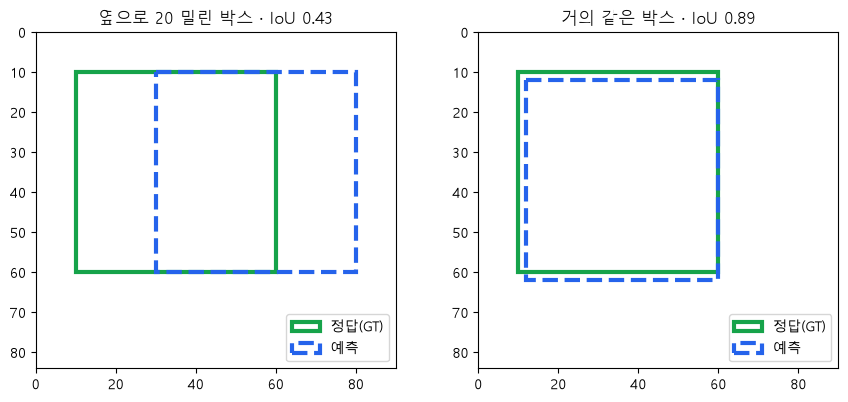

In [2]:
# 왜 · IoU 공식을 직접 구현해 손계산과 맞춰 보기 위해
def iou(a, b):                                     # 박스 [x1, y1, x2, y2] 두 개 → IoU
    """겹친 넓이 ÷ 합친 넓이"""                    # 함수 설명
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))  # 겹친 가로 (음수면 0)
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))  # 겹친 세로 (음수면 0)
    inter = w * h                                  # 겹친 넓이
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter  # 겹침은 한 번만
    return inter / union                           # 0 ~ 1


# 왜 · 많이 밀린 박스와 거의 같은 박스의 IoU 차이를 숫자로 보기 위해
gt = [10, 10, 60, 60]                                # 정답 50 × 50 = 2500
pairs = {"옆으로 20 밀린 박스": [30, 10, 80, 60], "거의 같은 박스": [12, 12, 60, 62]}  # 예측 2개
for name, p in pairs.items():                        # 예측마다
    print(f"{name:10s} {p} → IoU {iou(gt, p):.3f}")  # 숫자로 확인

# 왜 · 두 경우의 겹침을 그림으로 확인하기 위해
fig, axes = plt.subplots(1, 2, figsize=(9, 4))                   # 두 경우 나란히
for ax, (name, p) in zip(axes, pairs.items()):                   # 경우마다
    ax.add_patch(patches.Rectangle(gt[:2], 50, 50, fill=False, ec=GT_COLOR, lw=3,  # 정답 = 초록
                                   label="정답(GT)"))
    ax.add_patch(patches.Rectangle(p[:2], p[2] - p[0], p[3] - p[1], fill=False,  # 예측 = 파랑 점선
                                   ec=PRED_COLOR, lw=3, ls="--", label="예측"))
    ax.set_xlim(0, 90)                                           # 가로 범위
    ax.set_ylim(84, 0)                                           # 세로는 위가 0 (사진 좌표)
    ax.set_aspect("equal")                                       # 정사각형 비율
    ax.set_title(f"{name} · IoU {iou(gt, p):.2f}", fontsize=12)  # 제목에 IoU
    ax.legend(loc="lower right", fontsize=10)                    # 범례
plt.tight_layout()                                               # 여백 정리
plt.show()                                                       # 그림 출력

**결과** · 예측 정답은 아님 — `0.429` (겹친 1500 ÷ 합친 3500)

- `옆으로 20 밀린 박스 [30, 10, 80, 60] → IoU 0.429` — 겹친 30 × 50 = 1500 · 합친 2500 + 2500 - 1500 = 3500
- `거의 같은 박스   [12, 12, 60, 62] → IoU 0.888` — 몇 픽셀 차이 → 1에 가까움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>IoU</td><td>겹친 넓이 ÷ 합친 넓이 (0 ~ 1)</td><td>박스 하나가 얼마나 맞았는지</td></tr>
<tr><td>겹친 넓이만</td><td>큰 박스일수록 유리</td><td>쓰지 않음 (크기 영향)</td></tr>
<tr><td>정답 안에 든 비율</td><td>예측이 크면 1이 됨</td><td>IoU 대신 쓰지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 겹친 가로 · 세로가 음수일 때 `max(0, ·)`을 빼면 안 겹친 박스도 IoU가 양수가 됨

> ✅ **한 줄 정리** · IoU는 겹친 넓이를 합친 넓이로 나눈 0 ~ 1 값으로, 박스가 밀리거나 크기가 달라도 낮아진다.

**딥러닝 코드에서는**

- `torchvision.ops.box_iou(pred, gt)` — 같은 계산을 표로 (객체탐지-1 3장)

---
## 2. 짝짓기 · TP · FP · FN

> **이 장의 흐름**
>
> - 1장의 IoU로 정답과 예측을 1 : 1 짝지음
> - 분류와 달리 TN이 없다는 점부터 확인

<img src="images/pfo3_matching.png" alt="짝짓기 규칙: 컨피던스 높은 순 → TP · FP · FN" width="763">

**파이프라인 위치** · ⑥ 평가 — 판정표 만들기

### 2-1. `A` 분류의 혼동 행렬과 탐지의 차이 · `TP · FP · FN` <sub>원본 A2 · 셀 5 · 6</sub>

> 🎯 **분류에서 쓰던 혼동 행렬의 네 칸을 탐지에도 그대로 쓸 수 있는가?**

💡 **쉽게 말하면**

- 분류는 **사진 한 장에 답 하나**라 네 칸을 모두 셈.
- 탐지의 TN은 '물체 없는 자리에 박스를 안 친 것'인데, 그런 자리는 셀 수 없음.

**실행 흐름**

1. 왼쪽: 분류 혼동 행렬 네 칸
2. 오른쪽: 탐지 정답 2개 · 예측 3개
3. 칸 이름 비교

**먼저 예측** · 탐지에서 셀 수 없는 칸은? — 답은 코드 실행 결과 아래에

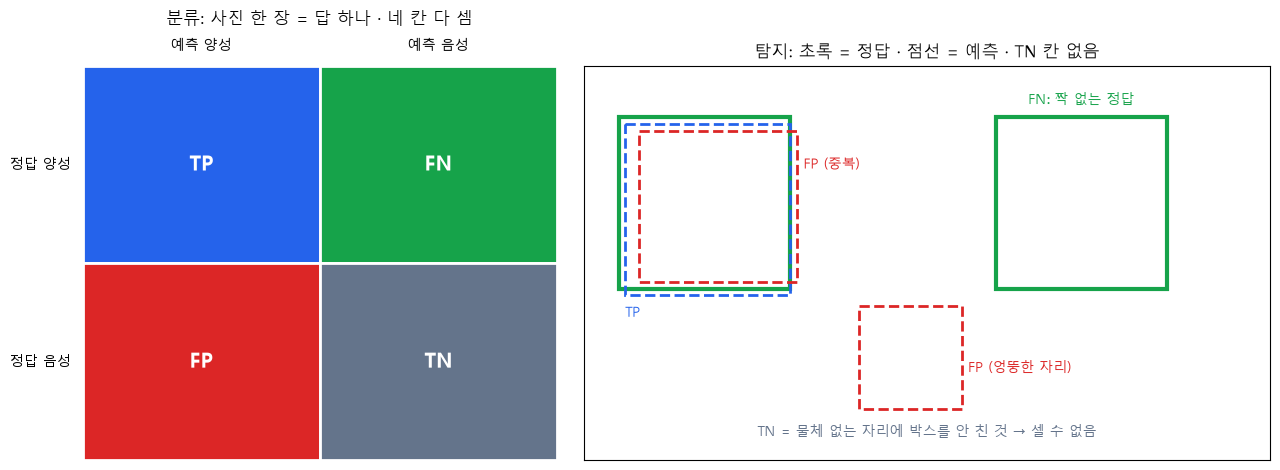

분류 칸: ['TP', 'FN', 'FP', 'TN'] | 탐지 칸: ['TP', 'FP', 'FN']


In [3]:
# 왜 · 분류와 탐지의 TP · FP · FN을 나란히 비교하기 위해
fig, (axl, axr) = plt.subplots(1, 2, figsize=(13, 4.8),  # 왼쪽 분류 · 오른쪽 탐지
                               gridspec_kw={"width_ratios": [1, 1.5]})

# 왼쪽: 분류의 혼동 행렬 네 칸
# 왜 · 분류에는 TN이 있다는 것을 먼저 보이기 위해
axl.set_xlim(0, 2)                                                            # 두 열
axl.set_ylim(2, 0)                                                            # 두 행 (위가 0)
axl.axis("off")                                                               # 눈금 숨김
cells = {(0, 0): ("TP", PRED_COLOR), (1, 0): ("FN", GT_COLOR),                # (열, 행): (이름, 색)
         (0, 1): ("FP", FP_COLOR), (1, 1): ("TN", "#64748b")}
for (c, r), (t, col) in cells.items():                                        # 칸마다
    axl.add_patch(patches.Rectangle((c, r), 1, 1, fc=col, ec="white", lw=2))  # 색 칸
    axl.text(c + 0.5, r + 0.5, t, ha="center", va="center", fontsize=15,      # 칸 이름
             fontweight="bold", color=INK)
axl.text(0.5, -0.08, "예측 양성", ha="center", fontsize=10)                   # 열 이름
axl.text(1.5, -0.08, "예측 음성", ha="center", fontsize=10)                   # 열 이름
axl.text(-0.05, 0.5, "정답 양성", ha="right", va="center", fontsize=10)       # 행 이름
axl.text(-0.05, 1.5, "정답 음성", ha="right", va="center", fontsize=10)       # 행 이름
axl.set_title("분류: 사진 한 장 = 답 하나 · 네 칸 다 셈", fontsize=12, pad=30)  # 제목

# 오른쪽: 탐지 (정답 2개 · 예측 3개)
# 왜 · 탐지에는 TN이 없어 정확도를 쓸 수 없다는 것을 보이기 위해
axr.set_xlim(0, 200)                                                                # 가로 범위
axr.set_ylim(115, 0)                                                                # 세로 (위가 0)
axr.set_aspect("equal")                                                             # 비율 유지
axr.set_xticks([])                                                                  # 눈금 숨김
axr.set_yticks([])                                                                  # 눈금 숨김
for g in ([10, 15, 60, 65], [120, 15, 170, 65]):                                    # 정답 2개
    axr.add_patch(patches.Rectangle(g[:2], 50, 50, fill=False, ec=GT_COLOR, lw=3))  # 초록
axr.text(145, 12, "FN: 짝 없는 정답", color=GT_COLOR, fontsize=10, ha="center", va="bottom")  # 놓침
for b, col in [([12, 17, 60, 67], PRED_COLOR), ([16, 19, 62, 63], FP_COLOR),        # TP · 중복 FP
               ([80, 70, 110, 100], FP_COLOR)]:                                     # 엉뚱한 자리 FP
    axr.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False,    # 예측 = 점선
                                    ec=col, lw=2, ls="--"))
axr.text(12, 70, "TP", color=PRED_COLOR, fontsize=10, va="top")                     # 맞힘
axr.text(64, 30, "FP (중복)", color=FP_COLOR, fontsize=10)  # 같은 정답을 또 침
axr.text(112, 88, "FP (엉뚱한 자리)", color=FP_COLOR, fontsize=10, va="center")     # 물체 없는 곳
axr.text(100, 108, "TN = 물체 없는 자리에 박스를 안 친 것 → 셀 수 없음", ha="center",  # TN 없음
         fontsize=10, color="#64748b")
axr.set_title("탐지: 초록 = 정답 · 점선 = 예측 · TN 칸 없음", fontsize=12)          # 제목
plt.tight_layout()                                                                  # 여백 정리
plt.show()                                                                          # 그림 출력
print("분류 칸:", [t for t, _ in cells.values()], "| 탐지 칸: ['TP', 'FP', 'FN']")  # 칸 비교

**결과** · 예측 정답은 `TN` — 물체 없는 자리의 개수가 정해져 있지 않음

- `분류 칸: ['TP', 'FN', 'FP', 'TN'] | 탐지 칸: ['TP', 'FP', 'FN']` — 탐지는 TN 칸이 없음
- 그림 오른쪽: 같은 정답을 또 친 박스 · 엉뚱한 자리 박스 = FP, 짝 없는 정답 = FN

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>분류 정확도</td><td>(TP + TN) ÷ 전체</td><td>분류 (TN이 있음)</td></tr>
<tr><td>정밀도 · 재현율</td><td>TN 없이 계산</td><td>탐지 (기본)</td></tr>
<tr><td>TP · FP · FN</td><td>정답과 예측을 1 : 1로 짝지어 정함</td><td>탐지 채점의 출발점</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 탐지에 정확도(accuracy)를 쓰면 분모가 정해지지 않음 → 정밀도 · 재현율로 평가

> ✅ **한 줄 정리** · 탐지는 TN을 셀 수 없으므로 정답과 예측을 짝지어 TP · FP · FN만 센다.

**딥러닝 코드에서는**

- torchmetrics · pycocotools도 TN 없이 TP · FP · FN으로 정밀도 · 재현율을 냄

### 2-2. `A` 예시 데이터 · 사진 2장 · 정답 3개 · 예측 6개 · `GT` · `PRED_A` <sub>원본 A3 · 셀 7 · 8</sub>

> 🎯 **손으로 검산할 수 있는 작은 예시는 어떻게 생겼는가?**

💡 **쉽게 말하면**

- **사진 2장 · 고양이 얼굴 정답 3개**에 모델 A가 예측 6개를 냄.
- 예측마다 (컨피던스, 사진, 박스) 세 가지를 적음.

**실행 흐름**

1. 정답 dict · 정답 수
2. 예측 6개 (컨피던스 높은 순)
3. 그림 도우미 · 그림

**먼저 예측** · 정답 박스와 예측 박스는 각각 몇 개? — 답은 코드 실행 결과 아래에

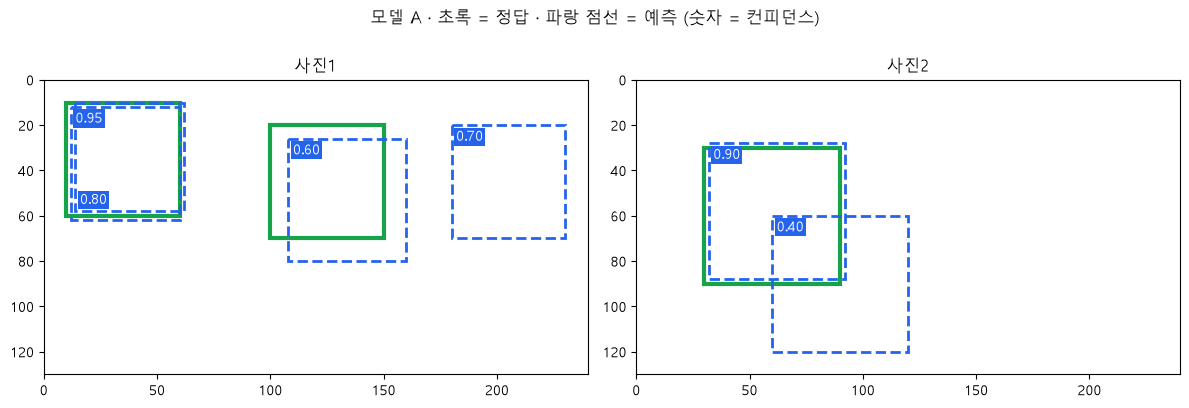

정답 박스 3 개 · 예측 박스 6 개


In [4]:
# 왜 · 손으로 검산할 수 있는 작은 정답을 만들기 위해
GT = {"사진1": [[10, 10, 60, 60], [100, 20, 150, 70]],  # 사진별 정답 박스
      "사진2": [[30, 30, 90, 90]]}
N_GT = sum(len(v) for v in GT.values())                 # 정답 수 3
GT_NAME = {("사진1", 0): "사진1 왼쪽", ("사진1", 1): "사진1 오른쪽", ("사진2", 0): "사진2"}  # 이름

# 모델 A의 예측: (컨피던스, 사진, 박스)
# 왜 · TP · FP가 섞인 예측으로 짝짓기 규칙을 연습하기 위해
PRED_A = [(0.95, "사진1", [12, 12, 60, 62]),    # 사진1 왼쪽 근처
          (0.90, "사진2", [32, 28, 92, 88]),    # 사진2 근처
          (0.80, "사진1", [14, 10, 62, 58]),    # 사진1 왼쪽 근처 (두 번째)
          (0.70, "사진1", [180, 20, 230, 70]),  # 엉뚱한 자리
          (0.60, "사진1", [108, 26, 160, 80]),  # 사진1 오른쪽 근처 (덜 맞음)
          (0.40, "사진2", [60, 60, 120, 120])]  # 사진2 반쯤


# 왜 · 정답과 예측을 사진별로 같은 형식으로 그리기 위해
def draw_boxes(ax, img, preds):                                   # 한 사진에 정답 · 예측 그리기
    for g in GT[img]:                                             # 정답
        ax.add_patch(patches.Rectangle(g[:2], g[2] - g[0], g[3] - g[1], fill=False,  # 초록 실선
                                       ec=GT_COLOR, lw=3))
    placed = []                                                   # 이미 놓은 이름표 자리
    for c, im, b in preds:                                        # 예측
        if im != img:                                             # 다른 사진이면
            continue                                              # 건너뜀
        ax.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False,  # 파랑 점선
                                       ec=PRED_COLOR, lw=2, ls="--"))
        x, y, va = b[0] + 2, b[1] + 2, "top"                      # 이름표는 왼쪽 위
        if any(abs(x - px) < 25 and abs(y - py) < 15 for px, py in placed):  # 겹치면
            y, va = b[3] - 2, "bottom"                            # 아래쪽으로
        placed.append((x, y))                                     # 자리 기록
        ax.text(x, y, f"{c:.2f}", color=INK, fontsize=10, va=va,  # 컨피던스
                bbox=dict(fc=PRED_COLOR, ec="none", pad=1.5))
    ax.set_xlim(0, 240)                                           # 가로 범위
    ax.set_ylim(130, 0)                                           # 세로 (위가 0)
    ax.set_aspect("equal")                                        # 비율 유지
    ax.set_title(img, fontsize=12)                                # 사진 이름


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))              # 사진 2장
for ax, img in zip(axes, GT):                                  # 사진마다
    draw_boxes(ax, img, PRED_A)                                # 정답 · 예측
fig.suptitle("모델 A · 초록 = 정답 · 파랑 점선 = 예측 (숫자 = 컨피던스)", fontsize=12)  # 제목
plt.tight_layout()                                             # 여백 정리
plt.show()                                                     # 그림 출력
print("정답 박스", N_GT, "개 · 예측 박스", len(PRED_A), "개")  # 개수 확인

**결과** · 예측 정답은 정답 `3`개 · 예측 `6`개

- `정답 박스 3 개 · 예측 박스 6 개` — 사진1에 정답 2개 · 사진2에 1개
- 그림: 0.95 · 0.80은 같은 사진1 왼쪽 정답 근처, 0.70은 아무 정답과도 먼 자리

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>정답 dict</td><td>사진 이름 → 박스 목록</td><td>사진별 정답을 찾을 때</td></tr>
<tr><td>예측 튜플</td><td>(컨피던스, 사진, 박스)</td><td>컨피던스 순 정렬 · 사진별 짝짓기</td></tr>
<tr><td>작은 예시</td><td>손으로 검산 가능</td><td>평가 함수가 맞는지 확인</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 예측은 컨피던스 순서로 정렬해 다루며, 같은 정답 근처에 박스가 여러 개 있을 수 있음

> ✅ **한 줄 정리** · 평가 원리는 손으로 검산할 수 있는 작은 예시로 먼저 확인한다.

**딥러닝 코드에서는**

- 실제 평가도 `{boxes, scores, labels}`를 사진마다 모으는 같은 구조 (객체탐지-2 6장)

### 2-3. `A` 짝짓기로 TP · FP · FN 정하기 · `judge()` <sub>원본 A4 · 셀 9 ~ 12</sub>

> 🎯 **컨피던스 0.80 박스는 사진1 왼쪽 정답과 꽤 겹치는데, 판정은?**

💡 **쉽게 말하면**

- **댄스파티 짝 정하기**처럼 컨피던스 높은 예측부터 차례로 짝을 정함.
- 이미 짝이 있는 정답에 또 다가간 예측은 중복이라 FP.

**실행 흐름**

1. 컨피던스 높은 순 정렬
2. 짝 없는 정답 중 IoU 최대
3. 0.5 이상 TP · 아니면 FP · 이유 설명
4. 남은 정답 = FN

**먼저 예측** · 0.80 박스(사진1 왼쪽 정답과 IoU 0.85)의 판정은? — 답은 코드 실행 결과 아래에

In [5]:
# 왜 · 정답 하나에 예측 하나만 짝지어 중복 정답을 막기 위해
def judge(preds, iou_thr=0.5):                                  # 예측 목록 → (판정 목록, FN 수)
    """컨피던스 높은 순 · 아직 짝 없는 정답 중 IoU가 가장 큰 것과 짝"""  # 함수 설명
    partner = {img: [None] * len(b) for img, b in GT.items()}   # 정답마다 짝의 컨피던스
    rows = []  # (컨피던스, TP 여부, IoU, 설명, 사진, 박스)
    for conf, img, box in sorted(preds, key=lambda p: -p[0]):   # 컨피던스 높은 순
        # 빈 정답
        free = [(iou(box, g), j) for j, g in enumerate(GT[img]) if partner[img][j] is None]
        best, j = max(free) if free else (0.0, -1)              # 가장 많이 겹친 빈 정답
        taken, jt = max(((iou(box, g), k) for k, g in enumerate(GT[img])  # 이미 짝 있는 정답 중
                         if partner[img][k] is not None), default=(0.0, -1))
        if j >= 0 and best >= iou_thr:                          # 기준 이상 → TP
            partner[img][j] = conf                              # 그 정답은 짝이 생김
            note = f"{GT_NAME[(img, j)]} 정답과 IoU {best:.2f} ≥ {iou_thr} → 짝"  # 설명
            rows.append((conf, True, best, note, img, box))     # TP 기록
            continue                                            # 다음 예측
        if taken >= iou_thr:                                    # 이미 짝 있는 정답과 많이 겹침
            note = (f"가장 많이 겹친 {GT_NAME[(img, jt)]} 정답(IoU {taken:.2f})은"  # 중복
                    f" 이미 {partner[img][jt]:.2f} 박스의 짝 → 중복")
        elif best > 0:                                          # 빈 정답과 조금 겹침
            note = f"남은 {GT_NAME[(img, j)]} 정답과 IoU {best:.2f} < {iou_thr}"  # 덜 겹침
        elif taken > 0:                                         # 짝 있는 정답과만 조금 겹침
            note = (f"겹치는 {GT_NAME[(img, jt)]} 정답(IoU {taken:.2f})은"  # 남은 정답과 0
                    f" 이미 {partner[img][jt]:.2f} 박스의 짝 · 남은 정답과는 안 겹침")
        else:                                                   # 아무것도 안 겹침
            note = "겹치는 정답 없음"                           # 엉뚱한 자리
        rows.append((conf, False, best, note, img, box))        # FP 기록
    fn = sum(c is None for cs in partner.values() for c in cs)  # 끝까지 짝 없는 정답
    return rows, fn                                             # 판정 · FN


# 왜 · 예측마다 왜 TP · FP가 되었는지 한 줄씩 확인하기 위해
rows_A, fn_A = judge(PRED_A, 0.5)                              # 평가 IoU 임계값 0.5
for k, (conf, ok, v, note, img, box) in enumerate(rows_A, 1):  # 꺼낸 순서대로
    print(f"{k}. 컨피던스 {conf:.2f} · {img} → {'TP' if ok else 'FP'} · {note}")  # 판정 한 줄
print("예측 6개를 전부 냈을 때 FN (놓친 정답):", fn_A)         # 놓친 수

1. 컨피던스 0.95 · 사진1 → TP · 사진1 왼쪽 정답과 IoU 0.89 ≥ 0.5 → 짝
2. 컨피던스 0.90 · 사진2 → TP · 사진2 정답과 IoU 0.88 ≥ 0.5 → 짝
3. 컨피던스 0.80 · 사진1 → FP · 가장 많이 겹친 사진1 왼쪽 정답(IoU 0.85)은 이미 0.95 박스의 짝 → 중복
4. 컨피던스 0.70 · 사진1 → FP · 겹치는 정답 없음
5. 컨피던스 0.60 · 사진1 → TP · 사진1 오른쪽 정답과 IoU 0.53 ≥ 0.5 → 짝
6. 컨피던스 0.40 · 사진2 → FP · 겹치는 사진2 정답(IoU 0.14)은 이미 0.90 박스의 짝 · 남은 정답과는 안 겹침
예측 6개를 전부 냈을 때 FN (놓친 정답): 0


**결과** · 예측 정답은 `FP` — 그 정답은 이미 0.95 박스의 짝 (중복)

- `1. 컨피던스 0.95 · 사진1 → TP · 사진1 왼쪽 정답과 IoU 0.89 ≥ 0.5 → 짝` — 가장 먼저 짝
- `3. 컨피던스 0.80 · 사진1 → FP · 가장 많이 겹친 사진1 왼쪽 정답(IoU 0.85)은 이미 0.95 박스의 짝 → 중복` — 많이 겹쳐도 중복이면 FP
- `4. 컨피던스 0.70 · 사진1 → FP · 겹치는 정답 없음` — 엉뚱한 자리
- `5. 컨피던스 0.60 · 사진1 → TP · 사진1 오른쪽 정답과 IoU 0.53 ≥ 0.5 → 짝` — 아슬아슬하게 TP (5-3에서 다시)
- `예측 6개를 전부 냈을 때 FN (놓친 정답): 0` — 정답 3개 모두 짝이 생김

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>COCO · 이 노트북</td><td>짝 없는 정답 중에서 찾음</td><td>직접 만드는 평가 함수</td></tr>
<tr><td>PASCAL VOC</td><td>가장 많이 겹친 정답이 이미 짝이면 바로 FP</td><td>VOC 방식 재현</td></tr>
<tr><td>컨피던스 순서 무시</td><td>판정이 달라짐</td><td>쓰지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 반드시 컨피던스 높은 순으로 꺼내야 함 → 순서를 바꾸면 TP · FP가 바뀜
> - 도구마다 세부 규칙이 조금 다름 (이 예시에서는 COCO · VOC 결과가 같음)

> ✅ **한 줄 정리** · 컨피던스 높은 예측부터 짝 없는 같은 클래스 정답과 IoU 기준 이상이면 TP, 아니면 FP이고, 끝까지 짝 없는 정답은 FN이다.

**딥러닝 코드에서는**

- torchmetrics `MeanAveragePrecision`이 사진 · 클래스마다 이 짝짓기를 실행

### 2-4. `B` 판정을 그림으로 · `show_judged()` <sub>원본 A4 · 셀 11 · 12</sub>

> 🎯 **판정표를 사진 위에 그리면 중복 FP는 어디에 보이는가?**

💡 **쉽게 말하면**

- 표로 본 판정을 **색으로 다시 칠함**.
- TP는 파랑 실선, FP는 빨강 점선, 짝 없는 정답에는 FN 글자.

**실행 흐름**

1. 짝이 생긴 정답 찾기
2. 정답 · 이름 · FN 표시
3. 예측마다 번호 · 판정 색
4. 개수 출력

**먼저 예측** · 사진1 왼쪽 정답 위에 겹친 박스는 몇 개이고 각각 판정은? — 답은 코드 실행 결과 아래에

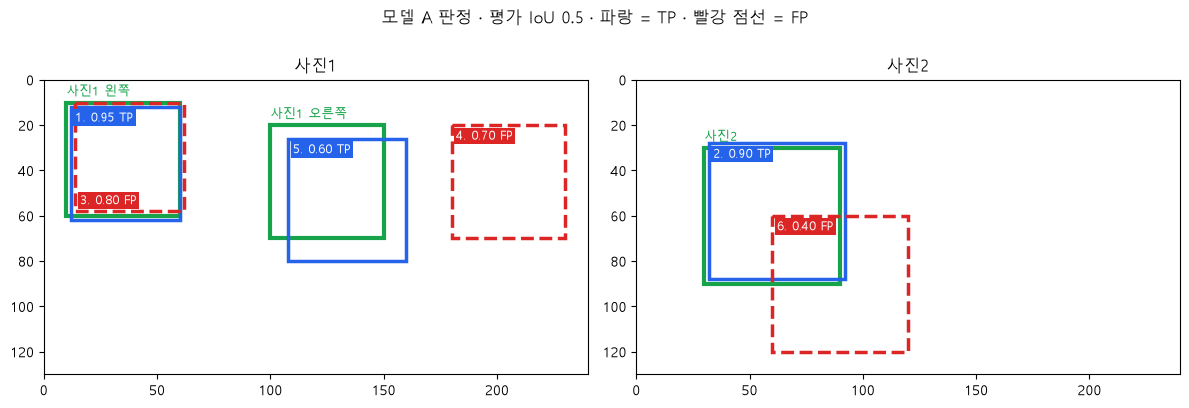

TP 3 · FP 3 · FN 0


In [6]:
# 왜 · 판정 결과를 번호 · 색으로 그림에 표시하기 위해
def show_judged(rows, title, axes=None):                             # 판정 결과로 색칠
    """TP = 파랑 실선 · FP = 빨강 점선 · 짝 못 찾은 정답 = FN · 번호 = 꺼낸 순서"""  # 함수 설명
    own = axes is None                                               # 그림을 직접 만들지
    if own:                                                          # 칸을 안 받았으면
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))            # 새 그림
    matched = {(img, max(range(len(GT[img])), key=lambda j: iou(box, GT[img][j])))  # 짝 생긴 정답
               for conf, ok, v, note, img, box in rows if ok}
    for ax, img in zip(axes, GT):                                    # 사진마다
        for j, g in enumerate(GT[img]):                              # 정답마다
            ax.add_patch(patches.Rectangle(g[:2], g[2] - g[0], g[3] - g[1], fill=False,  # 초록
                                           ec=GT_COLOR, lw=3))
            # 이름
            ax.text(g[0], g[1] - 2, GT_NAME[(img, j)], color=GT_COLOR, fontsize=9, va="bottom")
            if (img, j) not in matched:                              # 짝이 없으면
                # 놓침
                ax.text(g[0], g[3] + 2, "FN", color=GT_COLOR, fontsize=10, fontweight="bold",
                        va="top")
        placed = []                                                  # 이름표 자리
        for k, (conf, ok, v, note, im, b) in enumerate(rows, 1):     # 판정마다
            if im != img:                                            # 다른 사진
                continue                                             # 건너뜀
            col, ls = (PRED_COLOR, "-") if ok else (FP_COLOR, "--")  # TP · FP 색
            ax.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False,  # 예측 박스
                                           ec=col, lw=2.5, ls=ls))
            x, y, va = b[0] + 2, b[1] + 2, "top"                     # 이름표 자리
            if any(abs(x - px) < 25 and abs(y - py) < 15 for px, py in placed):  # 겹치면
                y, va = b[3] - 2, "bottom"                           # 아래쪽
            placed.append((x, y))                                    # 기록
            # 번호 · 판정
            ax.text(x, y, f"{k}. {conf:.2f} {'TP' if ok else 'FP'}", color=INK, fontsize=9,
                    va=va, bbox=dict(fc=col, ec="none", pad=1.5))
        ax.set_xlim(0, 240)                                          # 가로 범위
        ax.set_ylim(130, 0)                                          # 세로 (위가 0)
        ax.set_aspect("equal")                                       # 비율 유지
        ax.set_title(img, fontsize=12)                               # 사진 이름
    if own:                                                          # 직접 만든 그림이면
        fig.suptitle(title, fontsize=12)                             # 제목
        plt.tight_layout()                                           # 여백 정리
        plt.show()                                                   # 그림 출력


# 왜 · 숫자로 본 판정을 그림으로 확인하기 위해
show_judged(rows_A, "모델 A 판정 · 평가 IoU 0.5 · 파랑 = TP · 빨강 점선 = FP")  # 판정 그림
print("TP", sum(r[1] for r in rows_A), "· FP", sum(not r[1] for r in rows_A), "· FN", fn_A)  # 개수

**결과** · 예측 정답은 2개 — 0.95 TP · 0.80 FP (중복)

- `TP 3 · FP 3 · FN 0` — 그림의 파랑 실선 3개 · 빨강 점선 3개
- 0.60 박스는 TP지만 IoU 0.53 → 평가 IoU 0.75로 올리면 FP (5-3)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>판정표 (글)</td><td>이유를 한 줄씩</td><td>규칙 확인</td></tr>
<tr><td>판정 그림</td><td>자리 · 중복이 한눈에</td><td>오류 분석 · 보고</td></tr>
<tr><td>번호 = 꺼낸 순서</td><td>컨피던스 순서 확인</td><td>판정이 순서에 따라 바뀌는지</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 그림만 보면 0.80 박스가 맞아 보임 → 판정은 늘 짝 규칙으로

> ✅ **한 줄 정리** · 판정을 그림으로 칠하면 중복 박스와 놓친 정답이 한눈에 보인다.

**딥러닝 코드에서는**

- 오류 분석에서 FP · FN 사진을 따로 모아 보는 것과 같은 일 (객체탐지-2 6-2)

---
## 3. 정밀도 · 재현율 · 임계값

> **이 장의 흐름**
>
> - 2장의 판정표에서 몇 개를 셀지 정하는 것이 컨피던스 임계값
> - 임계값 하나로는 모델 비교가 흔들림 → 4장 AP로

<img src="images/pfo3_prf.png" alt="정밀도는 낸 박스, 재현율은 정답이 분모" width="763">

**파이프라인 위치** · ⑥ 평가 — 기준 하나의 성적

### 3-1. `A` 정밀도 · 재현율 · F1 · `prf()` <sub>원본 A5 · 셀 13 ~ 16</sub>

> 🎯 **컨피던스 0.75 이상인 박스만 내면 정밀도와 재현율은?**

💡 **쉽게 말하면**

- 정밀도는 **낸 답안 중 맞힌 비율**, 재현율은 **풀어야 할 문제 중 맞힌 비율**.
- F1은 둘의 조화 평균이라 하나만 높아서는 높게 안 나옴.

**실행 흐름**

1. 임계값 이상 박스만 남기기
2. TP · FP · FN 세기
3. 정밀도 · 재현율 · F1
4. 분모 비교 그림

**먼저 예측** · 0.75 이상 박스 3개 중 TP는 몇 개? — 답은 코드 실행 결과 아래에

컨피던스 0.75 이상: 낸 박스 3개 · TP 2 · FP 1 · FN 1
정밀도 2/3 = 0.667 · 재현율 2/3 = 0.667 · F1 0.667


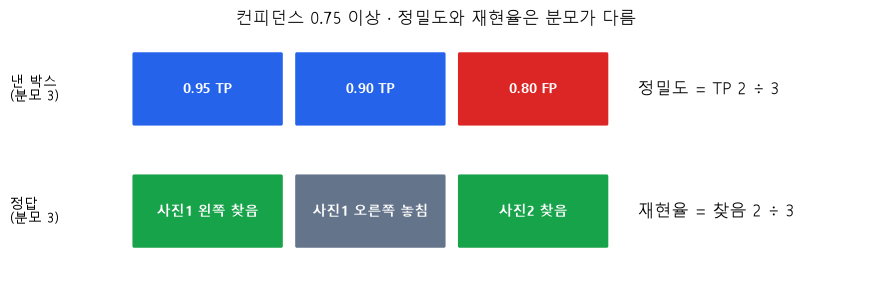

In [7]:
# 왜 · 임계값 하나에서의 정밀도 · 재현율 · F1을 한 함수로 구하기 위해
def prf(rows, conf_thr):                                      # 컨피던스 임계값 이상만 냈을 때
    """TP · FP · FN · 정밀도 · 재현율 · F1"""                 # 함수 설명
    kept = [ok for conf, ok, *_ in rows if conf >= conf_thr]  # 낸 박스의 판정
    tp = sum(kept)                                            # 맞힌 박스
    fp = len(kept) - tp                                       # 틀린 박스
    fn = N_GT - tp                                            # 놓친 정답
    p = tp / (tp + fp) if kept else 0.0                       # 정밀도 = TP ÷ 낸 박스
    r = tp / N_GT                                             # 재현율 = TP ÷ 정답 수
    f1 = 2 * p * r / (p + r) if p + r else 0.0                # 조화 평균
    return tp, fp, fn, p, r, f1                               # 여섯 값


# 왜 · 컨피던스 0.75에서의 지표를 손계산과 맞춰 보기 위해
tp, fp, fn, p, r, f1 = prf(rows_A, 0.75)                                         # 0.75 이상만
print(f"컨피던스 0.75 이상: 낸 박스 {tp + fp}개 · TP {tp} · FP {fp} · FN {fn}")  # 개수
print(f"정밀도 {tp}/{tp + fp} = {p:.3f} · 재현율 {tp}/{N_GT} = {r:.3f} · F1 {f1:.3f}")  # 비율

# 그림: 정밀도와 재현율은 분모가 다름
# 왜 · 두 지표의 분모 차이를 그림으로 보이기 위해
kept = [row for row in rows_A if row[0] >= 0.75]                              # 낸 박스 3개
found = {(img, max(range(len(GT[img])), key=lambda j: iou(box, GT[img][j])))  # 찾은 정답
         for conf, ok, v, note, img, box in kept if ok}
fig, ax = plt.subplots(figsize=(11, 3.4))                                     # 가로로 긴 그림
ax.set_xlim(0, 11)                                                            # 가로 범위
ax.set_ylim(3.0, 0)                                                           # 세로 (위가 0)
ax.axis("off")                                                                # 눈금 숨김


# 왜 · 판정 칩을 같은 모양으로 그리기 위해
def chip(x, y, text, col):                                                   # 둥근 이름표 하나
    ax.add_patch(patches.FancyBboxPatch((x, y), 1.9, 0.8, boxstyle="round,pad=0.02",  # 상자
                                        fc=col, ec="none"))
    ax.text(x + 0.95, y + 0.4, text, ha="center", va="center", fontsize=10,  # 글자
            color=INK, fontweight="bold")


ax.text(0, 0.65, f"낸 박스\n(분모 {len(kept)})", fontsize=10, va="center")       # 정밀도의 분모
for k, (conf, ok, *_) in enumerate(kept):                                        # 낸 박스마다
    # 판정
    chip(1.6 + k * 2.1, 0.25, f"{conf:.2f} {'TP' if ok else 'FP'}", PRED_COLOR if ok else FP_COLOR)
ax.text(8.1, 0.65, f"정밀도 = TP {sum(r_[1] for r_ in kept)} ÷ {len(kept)}", fontsize=12,  # 식
        va="center")
ax.text(0, 2.05, f"정답\n(분모 {N_GT})", fontsize=10, va="center")               # 재현율의 분모
for k, key in enumerate(GT_NAME):                                                # 정답마다
    chip(1.6 + k * 2.1, 1.65, f"{GT_NAME[key]} {'찾음' if key in found else '놓침'}",  # 찾았나
         GT_COLOR if key in found else "#64748b")
ax.text(8.1, 2.05, f"재현율 = 찾음 {len(found)} ÷ {N_GT}", fontsize=12, va="center")  # 식
ax.set_title("컨피던스 0.75 이상 · 정밀도와 재현율은 분모가 다름", fontsize=12)  # 제목
plt.show()                                                                       # 그림 출력

**결과** · 예측 정답은 `2`개 — 0.95 · 0.90 TP, 0.80 FP(중복)

- `컨피던스 0.75 이상: 낸 박스 3개 · TP 2 · FP 1 · FN 1` — 0.60 박스가 빠져 사진1 오른쪽 정답을 놓침
- `정밀도 2/3 = 0.667 · 재현율 2/3 = 0.667 · F1 0.667` — 분모: 낸 박스 3 · 정답 3

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>정밀도</td><td>TP ÷ (TP + FP) = TP ÷ 낸 박스 수</td><td>오탐이 비쌀 때</td></tr>
<tr><td>재현율</td><td>TP ÷ (TP + FN) = TP ÷ 정답 수</td><td>놓치면 안 될 때</td></tr>
<tr><td>F1</td><td>2 × 정밀도 × 재현율 ÷ (정밀도 + 재현율)</td><td>둘을 한 숫자로</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - TP · FP 판정은 A4 그대로 · 컨피던스 임계값은 그중 어디까지 셀지만 정함

> ✅ **한 줄 정리** · 정밀도는 낸 박스 중 맞은 비율, 재현율은 정답 중 찾은 비율이며 두 분모가 다르다.

**딥러닝 코드에서는**

- 서비스 기준(예: 0.5)을 정하면 그 자리의 정밀도 · 재현율 · F1을 따로 보고

### 3-2. `A` 컨피던스 임계값을 바꾸면 · `prf(rows, t)` <sub>원본 A6 · 셀 17 ~ 20</sub>

> 🎯 **임계값을 0.9 → 0.7 → 0.5로 내리면 정밀도와 재현율은 어느 쪽으로 움직이는가?**

💡 **쉽게 말하면**

- 임계값을 내리면 **발표하는 답이 늘어남**.
- 재현율은 늘거나 그대로, 정밀도는 대체로 내려감.

**실행 흐름**

1. 임계값 0.9 · 0.7 · 0.5
2. 새로 든 박스
3. 판정 그림 3줄

**먼저 예측** · 0.7 → 0.5로 내리면 정밀도는 내려갈까? — 답은 코드 실행 결과 아래에

컨피던스 임계값 | 낸 박스 | TP | FP | FN | 정밀도 | 재현율 | F1    | 새로 든 박스
           0.9 |      2 |  2 |  0 |  1 |  1.000 |  0.667 | 0.800 | 0.95 TP · 0.90 TP
           0.7 |      4 |  2 |  2 |  1 |  0.500 |  0.667 | 0.571 | 0.80 FP · 0.70 FP
           0.5 |      5 |  3 |  2 |  0 |  0.600 |  1.000 | 0.750 | 0.60 TP


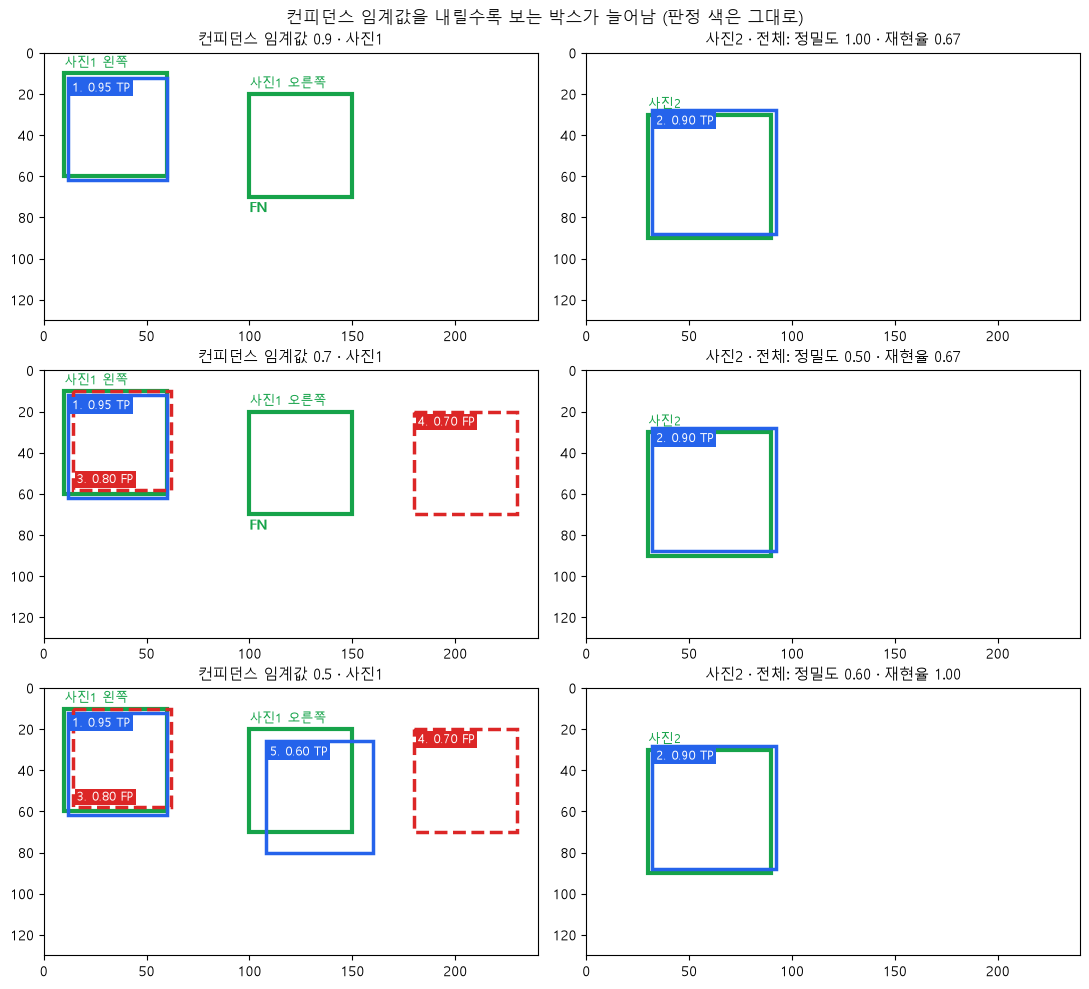

In [8]:
# 왜 · 임계값마다 지표가 어떻게 바뀌는지 한 표로 보기 위해
head = ("컨피던스 임계값 | 낸 박스 | TP | FP | FN | 정밀도 | 재현율 | F1    |"  # 표 머리
        " 새로 든 박스")
print(head)                                                                     # 머리 출력
prev = 1.01  # 이전 임계값 (처음은 1보다 크게)
for t in (0.9, 0.7, 0.5):                                                       # 임계값을 내리며
    tp, fp, fn, p, r, f1 = prf(rows_A, t)                                       # 그 임계값의 성적
    new = " · ".join(f"{c:.2f} {'TP' if ok else 'FP'}" for c, ok, *_ in rows_A  # 새로 든 박스
                     if t <= c < prev)
    print(f"{t:14.1f} | {tp + fp:6d} | {tp:2d} | {fp:2d} | {fn:2d} | {p:6.3f} | {r:6.3f} |"  # 한 줄
          f" {f1:.3f} | {new}")
    prev = t                                                                    # 다음 구간 시작

# 왜 · 임계값 세 개에서 남는 박스를 그림으로 비교하기 위해
fig, axes = plt.subplots(3, 2, figsize=(11, 10))                         # 임계값 3개 × 사진 2장
for row_axes, t in zip(axes, (0.9, 0.7, 0.5)):                           # 줄마다 임계값 하나
    show_judged([r_ for r_ in rows_A if r_[0] >= t], "", axes=row_axes)  # 그 임계값까지만
    tp, fp, fn, p, r, f1 = prf(rows_A, t)                                # 성적
    row_axes[0].set_title(f"컨피던스 임계값 {t} · 사진1", fontsize=11)   # 왼쪽 제목
    # 오른쪽 제목
    row_axes[1].set_title(f"사진2 · 전체: 정밀도 {p:.2f} · 재현율 {r:.2f}", fontsize=11)
# 제목
fig.suptitle("컨피던스 임계값을 내릴수록 보는 박스가 늘어남 (판정 색은 그대로)", fontsize=12)
plt.tight_layout()                                                       # 여백 정리
plt.show()                                                               # 그림 출력

**결과** · 예측 정답은 아님 — `0.500` → `0.600` (0.60 TP가 들어옴)

- `0.9 |      2 |  2 |  0 |  1 |  1.000 |  0.667 | 0.800 | 0.95 TP · 0.90 TP` — 엄격 · 모두 맞힘 · 하나 놓침
- `0.7 |      4 |  2 |  2 |  1 |  0.500 |  0.667 | 0.571 | 0.80 FP · 0.70 FP` — FP만 들어와 정밀도만 하락
- `0.5 |      5 |  3 |  2 |  0 |  0.600 |  1.000 | 0.750 | 0.60 TP` — TP가 들어와 재현율 1 · 정밀도도 다시 오름

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>임계값 올림</td><td>적게 냄 → 정밀도 ↑ · 재현율 ↓</td><td>오탐을 줄일 때</td></tr>
<tr><td>임계값 내림</td><td>많이 냄 → 재현율 ↑ · 정밀도 ↓</td><td>놓침을 줄일 때</td></tr>
<tr><td>정밀도 · 재현율 맞바꿈</td><td>trade-off</td><td>목적에 맞는 자리 고르기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 정밀도가 꼭 계속 내려가지는 않음 → TP가 들어오면 다시 오름

> ✅ **한 줄 정리** · 임계값을 내리면 재현율은 늘거나 그대로이고 정밀도는 대체로 내려간다.

**딥러닝 코드에서는**

- `keep = out["scores"] > 0.5` 한 줄이 이 trade-off의 자리를 정함

### 3-3. `A` 두 모델 중 어느 쪽이 나은가 · `PRED_B` · `F1 곡선` <sub>원본 A7 · 셀 21 ~ 24</sub>

> 🎯 **임계값 하나로 두 모델을 비교하면 결론이 흔들리는가?**

💡 **쉽게 말하면**

- 같은 시험을 **채점 기준 하나로만** 보면 기준에 따라 1등이 바뀜.
- 그래서 모든 기준을 묶은 숫자 하나(AP)가 필요.

**실행 흐름**

1. 모델 B 예측 4개 · 판정
2. 임계값 0.9 · 0.5에서 F1 비교
3. 임계값마다 F1 곡선

**먼저 예측** · 임계값 0.9와 0.5에서 F1이 높은 모델은 같을까? — 답은 코드 실행 결과 아래에

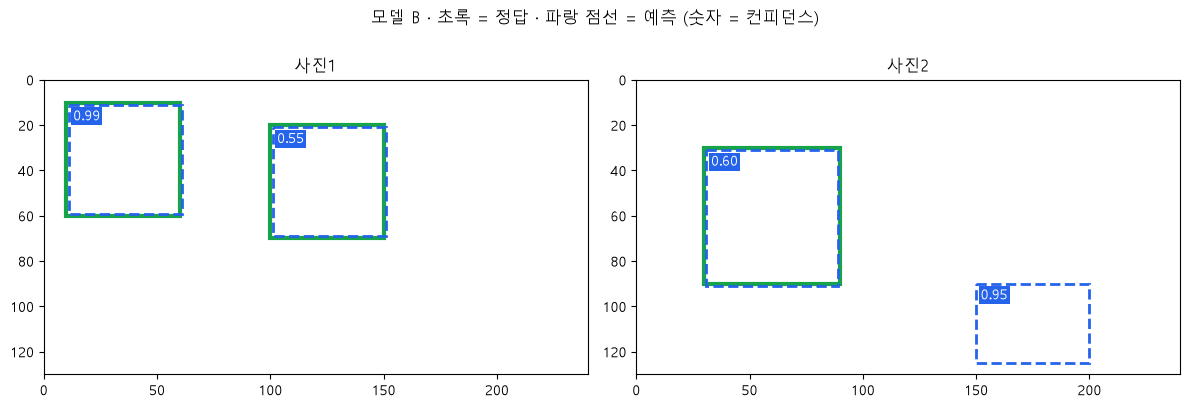

컨피던스 임계값 | 모델 A 정밀도 · 재현율 · F1 | 모델 B 정밀도 · 재현율 · F1
           0.9 | 1.000 · 0.667 · 0.800        | 0.500 · 0.333 · 0.400
           0.5 | 0.600 · 1.000 · 0.750        | 0.750 · 1.000 · 0.857


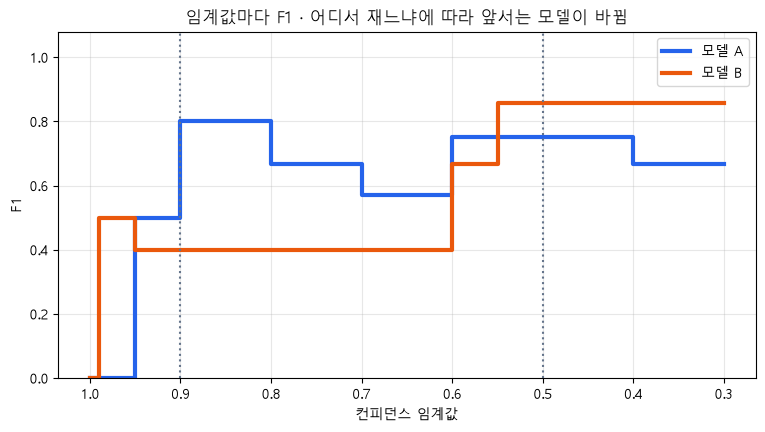

In [9]:
# 왜 · 한 임계값의 지표만으로는 두 모델을 공정하게 비교하기 어렵다는 것을 보이기 위해
PRED_B = [(0.99, "사진1", [11, 11, 61, 59]),       # 사진1 왼쪽
          (0.95, "사진2", [150, 90, 200, 125]),    # 엉뚱한 자리
          (0.60, "사진2", [31, 31, 89, 91]),       # 사진2
          (0.55, "사진1", [101, 21, 151, 69])]     # 사진1 오른쪽
rows_B, _ = judge(PRED_B, 0.5)                     # 같은 규칙으로 판정
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))  # 사진 2장
for ax, img in zip(axes, GT):                      # 사진마다
    draw_boxes(ax, img, PRED_B)                    # 정답 · 예측
fig.suptitle("모델 B · 초록 = 정답 · 파랑 점선 = 예측 (숫자 = 컨피던스)", fontsize=12)  # 제목
plt.tight_layout()                                 # 여백 정리
plt.show()                                         # 그림 출력

# 왜 · 임계값에 따라 나은 모델이 뒤바뀌는 것을 보기 위해
print("컨피던스 임계값 | 모델 A 정밀도 · 재현율 · F1 | 모델 B 정밀도 · 재현율 · F1")  # 표 머리
for t in (0.9, 0.5):                                                                  # 두 기준
    a, b = prf(rows_A, t), prf(rows_B, t)                                             # 두 모델 성적
    print(f"{t:14.1f} | {a[3]:.3f} · {a[4]:.3f} · {a[5]:.3f}        |"                # 한 줄
          f" {b[3]:.3f} · {b[4]:.3f} · {b[5]:.3f}")

# 왜 · 모든 임계값의 F1을 곡선으로 비교하기 위해
ts = np.round(np.arange(0.30, 1.001, 0.01), 2)      # 임계값 0.30 ~ 1.00
fig, ax = plt.subplots(figsize=(9, 4.5))            # F1 곡선
for name, rows, col in [("모델 A", rows_A, PRED_COLOR), ("모델 B", rows_B, ENV_COLOR)]:  # 두 모델
    ax.plot(ts, [prf(rows, t)[5] for t in ts], lw=3, color=col, label=name,  # 계단 모양
            drawstyle="steps-pre")
for t in (0.9, 0.5):                                # 비교한 두 자리
    ax.axvline(t, color="#64748b", ls=":", lw=1.5)  # 세로 점선
ax.set_xlabel("컨피던스 임계값", fontsize=10)       # x축
ax.set_ylabel("F1", fontsize=10)                    # y축
ax.set_ylim(0, 1.08)                                # 범위
ax.invert_xaxis()                                   # 왼쪽 = 높은 임계값 (적게 냄)
ax.set_title("임계값마다 F1 · 어디서 재느냐에 따라 앞서는 모델이 바뀜", fontsize=12)  # 제목
ax.grid(alpha=0.3)                                  # 옅은 격자
ax.legend(fontsize=10)                              # 범례
plt.show()                                          # 그림 출력

**결과** · 예측 정답은 다름 — 0.9에서는 A(0.800), 0.5에서는 B(0.857)

- `0.9 | 1.000 · 0.667 · 0.800        | 0.500 · 0.333 · 0.400` — 엄격한 기준은 A가 높음
- `0.5 | 0.600 · 1.000 · 0.750        | 0.750 · 1.000 · 0.857` — 느슨한 기준은 B가 높음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>임계값 하나의 F1</td><td>그 자리 성능</td><td>서비스 기준이 정해져 있을 때</td></tr>
<tr><td>임계값마다 F1 곡선</td><td>어디서 앞서는지 보임</td><td>비교 결론이 흔들리는지 확인</td></tr>
<tr><td>AP (4장)</td><td>모든 임계값을 숫자 하나로</td><td>모델 비교 (기본)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 어느 임계값을 고르느냐에 따라 '더 나은 모델'이 바뀜 → 비교는 AP로

> ✅ **한 줄 정리** · 임계값 하나의 F1로는 모델 순위가 흔들리므로, 모든 임계값을 묶은 AP가 필요하다.

**딥러닝 코드에서는**

- 체크포인트 고르기는 F1 하나보다 val AP · mAP로 (객체탐지-2 5장)

---
## 4. PR 점 · 포락선 · AP

> **이 장의 흐름**
>
> - 3장의 임계값을 한 박스씩 끝까지 내리며 점을 찍음
> - 점 → 계단(포락선) → 넓이(AP)

<img src="images/pfo3_ap_area.png" alt="포락선 계단 아래 넓이 = AP" width="662">

**파이프라인 위치** · ⑥ 평가 — 모델 비교용 숫자 하나

### 4-1. `A` PR 점 찍기 · `pr_points()` · `np.cumsum()` <sub>원본 B1 · 셀 25 ~ 28</sub>

> 🎯 **임계값을 한 박스씩 내리며 (재현율, 정밀도) 점을 찍으면 FP가 들어올 때 점은 어디로 가는가?**

💡 **쉽게 말하면**

- 예측을 **컨피던스 높은 순으로 세우고 한 명씩 입장**시킬 때마다 점을 찍음.
- TP가 들어오면 오른쪽, FP가 들어오면 아래로 이동.

**실행 흐름**

1. 누적 TP
2. 재현율 = 누적 TP ÷ 정답 수 · 정밀도 = 누적 TP ÷ 낸 수
3. 점 6개 표 · 화살표 그림

**먼저 예측** · 0.70 박스(FP)가 들어오면 재현율은? — 답은 코드 실행 결과 아래에

컨피던스 임계값 | 새로 든 박스 | 누적 TP | 누적 FP | 재현율 | 정밀도
          0.95 | TP         |       1 |       0 |  0.333 | 1.000
          0.90 | TP         |       2 |       0 |  0.667 | 1.000
          0.80 | FP         |       2 |       1 |  0.667 | 0.667
          0.70 | FP         |       2 |       2 |  0.667 | 0.500
          0.60 | TP         |       3 |       2 |  1.000 | 0.600
          0.40 | FP         |       3 |       3 |  1.000 | 0.500


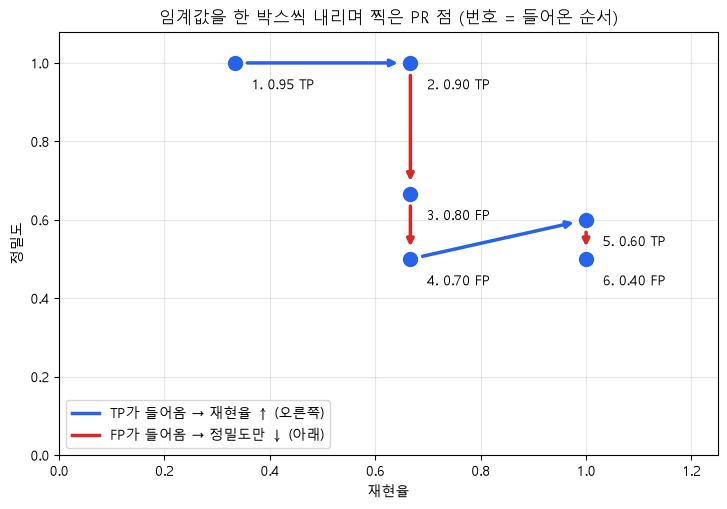

In [10]:
# 왜 · 모든 임계값을 한 번에 보는 PR 점을 만들기 위해
def pr_points(rows, n_gt=None):                                   # 판정 목록 → (재현율, 정밀도) 점
    """컨피던스 높은 순으로 한 박스씩 더하며 (재현율, 정밀도)"""  # 함수 설명
    n_gt = n_gt or N_GT                                           # 정답 수 (기본 3)
    tp = np.cumsum([ok for _, ok, *_ in rows])                    # 누적 TP
    k = np.arange(1, len(rows) + 1)                               # 낸 박스 수 1, 2, ...
    return tp / n_gt, tp / k                                      # 재현율 · 정밀도


# 왜 · 박스를 하나씩 더할 때 재현율 · 정밀도가 어떻게 바뀌는지 표로 보기 위해
rec_A, prec_A = pr_points(rows_A)                                              # 모델 A의 PR 점 6개
print("컨피던스 임계값 | 새로 든 박스 | 누적 TP | 누적 FP | 재현율 | 정밀도")  # 표 머리
for (conf, ok, *_), r, p, k in zip(rows_A, rec_A, prec_A, range(1, 7)):        # 점마다
    tp = round(r * N_GT)                                                       # 누적 TP
    # 한 줄
    print(f"{conf:14.2f} | {'TP' if ok else 'FP':10s} | {tp:7d} | {k - tp:7d} | {r:6.3f} | {p:.3f}")

# 왜 · PR 점을 그림으로 확인하기 위해
fig, ax = plt.subplots(figsize=(8.5, 5.5))                                # PR 점 그림
ax.plot(rec_A, prec_A, "o", color=PRED_COLOR, ms=10, zorder=3)            # 점 6개
for k, ((conf, ok, *_), r, p) in enumerate(zip(rows_A, rec_A, prec_A)):   # 점마다
    ax.annotate(f"{k + 1}. {conf:.2f} {'TP' if ok else 'FP'}", (r, p), xytext=(12, -16),  # 이름표
                textcoords="offset points", va="center", fontsize=10)
    if k > 0:                                                             # 두 번째 점부터
        ax.annotate("", xy=(r, p), xytext=(rec_A[k - 1], prec_A[k - 1]),  # 이전 점에서 화살표
                    arrowprops=dict(arrowstyle="-|>", color=PRED_COLOR if ok else FP_COLOR,
                                    lw=2.5, shrinkA=9, shrinkB=9))
ax.plot([], [], color=PRED_COLOR, lw=2.5, label="TP가 들어옴 → 재현율 ↑ (오른쪽)")  # 범례용
ax.plot([], [], color=FP_COLOR, lw=2.5, label="FP가 들어옴 → 정밀도만 ↓ (아래)")  # 범례용
ax.set_xlim(0, 1.25)                                                      # 이름표 자리까지
ax.set_ylim(0, 1.08)                                                      # 범위
ax.set_xlabel("재현율", fontsize=10)                                      # x축
ax.set_ylabel("정밀도", fontsize=10)                                      # y축
ax.set_title("임계값을 한 박스씩 내리며 찍은 PR 점 (번호 = 들어온 순서)", fontsize=12)  # 제목
ax.grid(alpha=0.3)                                                        # 격자
ax.legend(loc="lower left", fontsize=10)                                  # 범례
plt.show()                                                                # 그림 출력

**결과** · 예측 정답은 그대로 `0.667` — 정밀도만 0.667 → 0.500

- `0.95 | TP         |       1 |       0 |  0.333 | 1.000` — TP → 재현율이 1/3 오름
- `0.80 | FP         |       2 |       1 |  0.667 | 0.667` — FP → 재현율 그대로 · 정밀도만 하락
- `0.70 | FP         |       2 |       2 |  0.667 | 0.500` — 또 FP → 더 하락
- `0.60 | TP         |       3 |       2 |  1.000 | 0.600` — 마지막 TP → 재현율 1

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>TP가 들어옴</td><td>재현율 ↑ (오른쪽)</td><td>정답을 하나 더 찾음</td></tr>
<tr><td>FP가 들어옴</td><td>정밀도 ↓ (아래)</td><td>헛짚은 박스</td></tr>
<tr><td>같은 컨피던스 여럿</td><td>한꺼번에 들어옴</td><td>점 하나로</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 판정은 임계값과 무관 → 컨피던스 높은 순으로 짝지으므로 들어오는 순서가 바뀌지 않음

> ✅ **한 줄 정리** · PR 점은 컨피던스 높은 순으로 한 박스씩 더하며 찍고, TP는 오른쪽 · FP는 아래로 움직인다.

**딥러닝 코드에서는**

- `np.cumsum(tp)`로 누적 → 객체탐지-1 6-1 · torchmetrics 안에서도 같은 순서

### 4-2. `A` 보간 · 포락선 · `envelope()` · `np.maximum.accumulate()` <sub>원본 B2 · 셀 29 ~ 31</sub>

> 🎯 **0.70 박스 점(정밀도 0.5)보다 포락선이 왜 더 높은가?**

💡 **쉽게 말하면**

- 포락선은 **오른쪽에서 본 최고 높이**.
- 재현율 2/3은 0.90 박스까지만 내도 정밀도 1.0으로 얻을 수 있으니 그 아래로 내려가지 않음.

**실행 흐름**

1. 오른쪽 누적 최댓값
2. 정의 그대로 보간 정밀도
3. 계단 꼭짓점
4. 그림 · 높이 출력

**먼저 예측** · 재현율 1.0 이상에서 얻을 수 있는 최고 정밀도는? — 답은 코드 실행 결과 아래에

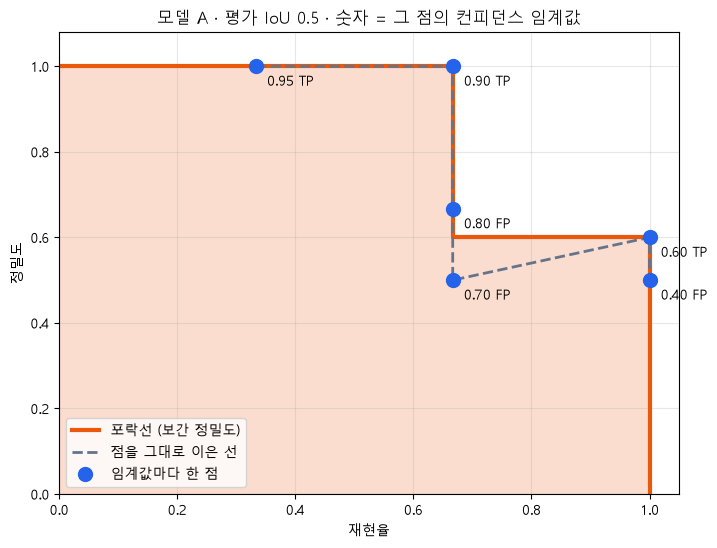

재현율 0.333 이상에서 얻을 수 있는 최고 정밀도 = 1.000
재현율 0.667 이상에서 얻을 수 있는 최고 정밀도 = 1.000
재현율 1.000 이상에서 얻을 수 있는 최고 정밀도 = 0.600


In [11]:
# 왜 · AP 계산이 쓰는 보간 규칙을 직접 구현하기 위해
def envelope(prec):                                    # 포락선 (보간 정밀도)
    """오른쪽(재현율이 같거나 큰 쪽)에서 본 최댓값"""  # 함수 설명
    return np.maximum.accumulate(prec[::-1])[::-1]     # 뒤집기 → 누적 최대 → 뒤집기


# 왜 · 재현율 r에서 읽을 보간 정밀도를 구하기 위해
def interp_precision(rec, prec, r):                    # 정의 그대로
    """재현율이 r 이상인 점들 중 가장 높은 정밀도 (없으면 0)"""  # 함수 설명
    ok = rec >= r - 1e-12                              # 재현율 r 이상인 점 (반올림 오차 허용)
    return float(prec[ok].max()) if ok.any() else 0.0  # 그중 최고


# 왜 · 포락선을 계단 그림으로 그릴 좌표를 만들기 위해
def env_xy(rec, prec):                                            # 포락선 계단의 꼭짓점
    """재현율 구간 (이전, lv]의 높이 = interp_precision(lv) · 끝에서 0으로"""  # 함수 설명
    levels = np.unique(rec)                                       # 재현율이 바뀌는 자리
    heights = [interp_precision(rec, prec, lv) for lv in levels]  # 자리마다 높이
    xs, ys = [0.0], [heights[0]]                                  # 왼쪽 끝에서 시작
    for lv, h in zip(levels, heights):                            # 자리마다
        xs += [xs[-1], lv]                                        # 세로 → 가로
        ys += [h, h]                                              # 같은 높이
    return xs + [levels[-1]], ys + [0.0], levels, heights         # 끝에서 0으로 내림


# 왜 · PR 점과 포락선을 함께 그려 보간의 뜻을 보이기 위해
xs, ys, levels, heights = env_xy(rec_A, prec_A)                                   # 모델 A의 포락선
fig, ax = plt.subplots(figsize=(8, 6))                                            # 그림
ax.fill_between(xs, ys, color=ENV_COLOR, alpha=0.2)                               # 넓이 = AP
ax.plot(xs, ys, color=ENV_COLOR, lw=3, label="포락선 (보간 정밀도)")              # 계단
ax.plot(rec_A, prec_A, "--", color="#64748b", lw=2, label="점을 그대로 이은 선")  # 지그재그
ax.plot(rec_A, prec_A, "o", color=PRED_COLOR, ms=10, label="임계값마다 한 점")    # PR 점
for (conf, ok, *_), r, p in zip(rows_A, rec_A, prec_A):                           # 점마다
    ax.annotate(f"{conf:.2f} {'TP' if ok else 'FP'}", (r, p), xytext=(8, -14),    # 이름표
                textcoords="offset points", fontsize=10)
ax.set_xlim(0, 1.05)                                                              # 범위
ax.set_ylim(0, 1.08)                                                              # 범위
ax.set_xlabel("재현율", fontsize=10)                                              # x축
ax.set_ylabel("정밀도", fontsize=10)                                              # y축
ax.set_title("모델 A · 평가 IoU 0.5 · 숫자 = 그 점의 컨피던스 임계값", fontsize=12)  # 제목
ax.grid(alpha=0.3)                                                                # 격자
ax.legend(loc="lower left", fontsize=10)                                          # 범례
plt.show()                                                                        # 그림 출력
for lv, h in zip(levels, heights):                                                # 계단 높이
    print(f"재현율 {lv:.3f} 이상에서 얻을 수 있는 최고 정밀도 = {h:.3f}")         # 보간 정밀도

**결과** · 예측 정답은 `0.600` — 마지막 TP 점

- `재현율 0.333 이상에서 얻을 수 있는 최고 정밀도 = 1.000` — 첫 계단 높이
- `재현율 0.667 이상에서 얻을 수 있는 최고 정밀도 = 1.000` — FP 점(0.667 · 0.500) 위를 지남
- `재현율 1.000 이상에서 얻을 수 있는 최고 정밀도 = 0.600` — 마지막 계단 높이

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>점을 그대로 잇기</td><td>지그재그</td><td>쓰지 않음</td></tr>
<tr><td>포락선 (보간)</td><td>오른쪽에서 본 최댓값 · 계단</td><td>AP 계산의 높이</td></tr>
<tr><td>둥근 곡선</td><td>점 사이에 없는 값을 만듦</td><td>쓰지 않음</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 점 사이에는 실제 값이 없음 → 포락선은 가로 · 세로 선만으로 된 계단

> ✅ **한 줄 정리** · 포락선은 그 재현율 이상에서 얻을 수 있는 최고 정밀도로 만든 계단이다.

**딥러닝 코드에서는**

- `np.maximum.accumulate(prec[::-1])[::-1]` 한 줄

### 4-3. `A` AP = 포락선 아래 넓이 · `ap_all_point()` <sub>원본 B3 · 셀 32 ~ 39</sub>

> 🎯 **계단 아래 넓이를 손으로 구하면 얼마이고, 두 모델 중 AP가 높은 쪽은?**

💡 **쉽게 말하면**

- AP는 **계단 아래 직사각형 넓이의 합**.
- 넓이가 1이 되려면 모든 정답을 찾을 때까지 FP가 없어야 함.

**실행 흐름**

1. 손계산 (2/3) × 1.0 + (1/3) × 0.6
2. 함수 결과
3. 직사각형 그림
4. 모델 B · 수업 Day02 그림 예

**먼저 예측** · 모델 A의 AP는? — 답은 코드 실행 결과 아래에

손계산: 재현율 0 → 2/3 구간 높이 1.0 · 2/3 → 1 구간 높이 0.6
        (2/3) × 1.0 + (1/3) × 0.6 = 0.8667
함수   : AP = 0.8667


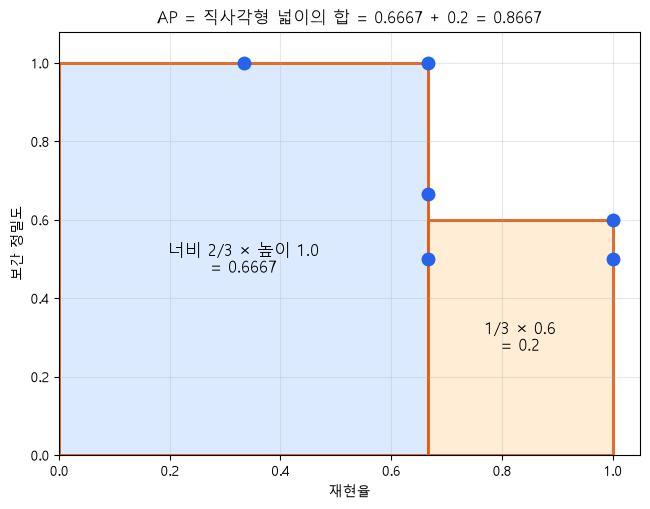

모델 A AP = 0.8667 · 모델 B AP = 0.8333
수업 Day02 그림 (정답 2개 · 예측 3개): 0.8333


In [12]:
# 왜 · 곡선 아래 넓이를 손으로 계산할 수 있는 방식으로 구하기 위해
def ap_all_point(rec, prec):                            # 포락선 아래 넓이
    """재현율이 바뀌는 모든 자리에서 직사각형 넓이를 더함 (PASCAL VOC 2010 이후)"""  # 함수 설명
    r = np.concatenate([[0.0], rec, [1.0]])             # 양 끝 재현율 0 · 1 추가
    p = envelope(np.concatenate([[0.0], prec, [0.0]]))  # 양 끝 정밀도 0 · 포락선
    return float(np.sum((r[1:] - r[:-1]) * p[1:]))      # 너비 × 높이의 합


# 왜 · 함수 결과를 직사각형 넓이 손계산과 맞춰 보기 위해
print("손계산: 재현율 0 → 2/3 구간 높이 1.0 · 2/3 → 1 구간 높이 0.6")          # 계단 두 칸
print(f"        (2/3) × 1.0 + (1/3) × 0.6 = {2 / 3 * 1.0 + 1 / 3 * 0.6:.4f}")  # 손계산
print(f"함수   : AP = {ap_all_point(rec_A, prec_A):.4f}")                      # 함수 결과

fig, ax = plt.subplots(figsize=(7.5, 5.5))                                      # 직사각형 그림
ax.add_patch(patches.Rectangle((0, 0), 2 / 3, 1.0, fc="#dbeafe", ec=ENV_COLOR, lw=2))  # 왼쪽 칸
# 오른쪽 칸
ax.add_patch(patches.Rectangle((2 / 3, 0), 1 / 3, 0.6, fc="#ffedd5", ec=ENV_COLOR, lw=2))
ax.text(1 / 3, 0.5, "너비 2/3 × 높이 1.0\n= 0.6667", ha="center", va="center", fontsize=12)  # 넓이
ax.text(5 / 6, 0.3, "1/3 × 0.6\n= 0.2", ha="center", va="center", fontsize=12)  # 넓이
ax.plot(rec_A, prec_A, "o", color=PRED_COLOR, ms=9)                             # PR 점
ax.set_xlim(0, 1.05)                                                            # 범위
ax.set_ylim(0, 1.08)                                                            # 범위
ax.set_xlabel("재현율", fontsize=10)                                            # x축
ax.set_ylabel("보간 정밀도", fontsize=10)                                       # y축
ax.set_title("AP = 직사각형 넓이의 합 = 0.6667 + 0.2 = 0.8667", fontsize=12)    # 제목
ax.grid(alpha=0.3)                                                              # 격자
plt.show()                                                                      # 그림 출력

# 왜 · 두 모델을 AP 하나로 비교하기 위해
rec_B, prec_B = pr_points(rows_B)                         # 모델 B도 같은 방법
print(f"모델 A AP = {ap_all_point(rec_A, prec_A):.4f} ·"  # 두 모델 비교
      f" 모델 B AP = {ap_all_point(rec_B, prec_B):.4f}")
print("수업 Day02 그림 (정답 2개 · 예측 3개):",           # 0.5 × 1.0 + 0.5 × 0.67
      round(ap_all_point(np.array([0.5, 0.5, 1.0]), np.array([1.0, 0.5, 2 / 3])), 4))

**결과** · 예측 정답은 `0.8667`

- `(2/3) × 1.0 + (1/3) × 0.6 = 0.8667` — 직사각형 두 개
- `함수   : AP = 0.8667` — 손계산과 같음
- `모델 A AP = 0.8667 · 모델 B AP = 0.8333` — AP로는 A가 조금 높음 (F1 하나로는 B가 높았음)
- `수업 Day02 그림 (정답 2개 · 예측 3개): 0.8333` — 0.5 × 1.0 + 0.5 × 0.667 · 수업의 0.83과 같음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>AP</td><td>모든 임계값을 묶은 넓이</td><td>모델 비교</td></tr>
<tr><td>임계값 하나의 F1</td><td>그 자리 하나</td><td>서비스 기준 판단</td></tr>
<tr><td>AP + 그 자리 F1</td><td>둘 다 적기</td><td>보고서 (기본)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - AP는 모델 비교용 · 실제로 쓸 임계값이 있으면 그 자리의 정밀도 · 재현율도 같이 봄

> ✅ **한 줄 정리** · AP는 포락선 아래 넓이이고, 모든 정답을 FP 없이 찾을 때만 1이 된다.

**딥러닝 코드에서는**

- 체크포인트 고르기 · 실험 비교는 val AP로 (객체탐지-2 5 · 7장)

---
## 5. AP를 바꾸는 조건 세 가지

> **이 장의 흐름**
>
> - 4장의 AP는 조건을 하나 정한 값
> - 먼저 자르기 · 계산 방식 · 평가 IoU를 하나씩 바꿔 봄

<img src="images/pfo3_conditions.png" alt="같은 예측이라도 조건마다 AP가 다름" width="660">

**파이프라인 위치** · ⑥ 평가 — 숫자와 조건을 함께 적는 이유

### 5-1. `A` 먼저 자르고 AP를 구하면 · `cut` <sub>원본 B4 · 셀 40 ~ 43</sub>

> 🎯 **컨피던스 0.75 이상 박스만 남긴 뒤 AP를 구하면 0.8667 그대로인가?**

💡 **쉽게 말하면**

- 먼저 자르면 **곡선 뒤쪽이 통째로 사라짐**.
- 모델이 나빠진 게 아니라 계산 범위가 줄어든 것.

**실행 흐름**

1. 0.75 이상만 남기기
2. 잘린 AP · 원래 AP
3. 두 넓이 그림

**먼저 예측** · 0.75 이상만 남기면 AP는? — 답은 코드 실행 결과 아래에

잘려 나간 박스: 0.70 FP · 0.60 TP · 0.40 FP
0.75 이상만: 재현율 최대 0.667 · AP = 0.6667
전부 사용  : 재현율 최대 1.000 · AP = 0.8667


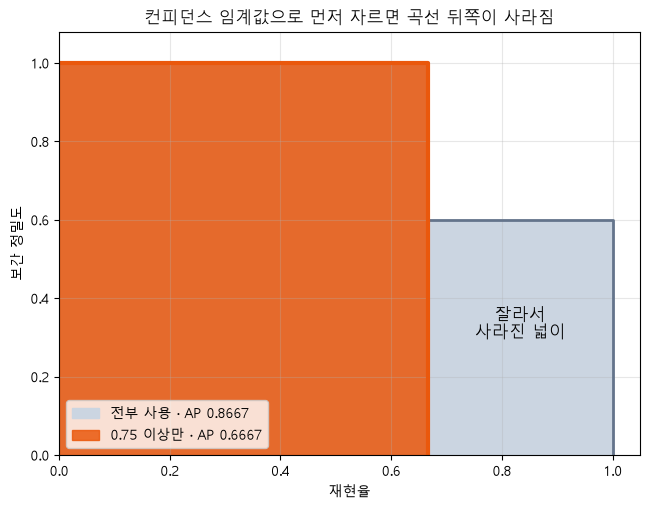

In [13]:
# 왜 · AP 전에 임계값으로 자르면 AP가 낮아지는 실수를 보이기 위해
cut = [row for row in rows_A if row[0] >= 0.75]                        # 0.75 이상만 남김
rec_c, prec_c = pr_points(cut)                                         # 남은 박스로 PR 점
print("잘려 나간 박스:", " · ".join(f"{c:.2f} {'TP' if ok else 'FP'}"  # 버린 박스
                              for c, ok, *_ in rows_A if c < 0.75))
# 잘린 AP
print(f"0.75 이상만: 재현율 최대 {rec_c[-1]:.3f} · AP = {ap_all_point(rec_c, prec_c):.4f}")
# 원래 AP
print(f"전부 사용  : 재현율 최대 {rec_A[-1]:.3f} · AP = {ap_all_point(rec_A, prec_A):.4f}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))                                       # 두 넓이 비교
xa, ya, *_ = env_xy(rec_A, prec_A)                                               # 전부 사용한 계단
xc, yc, *_ = env_xy(rec_c, prec_c)                                               # 잘라 낸 계단
ax.fill_between(xa, ya, color="#cbd5e1", label="전부 사용 · AP 0.8667")          # 회색 넓이
ax.fill_between(xc, yc, color=ENV_COLOR, alpha=0.85, label="0.75 이상만 · AP 0.6667")  # 주황 넓이
ax.plot(xa, ya, color="#64748b", lw=2)                                           # 회색 계단
ax.plot(xc, yc, color=ENV_COLOR, lw=3)                                           # 주황 계단
ax.text(5 / 6, 0.3, "잘라서\n사라진 넓이", ha="center", fontsize=12)             # 설명
ax.set_xlim(0, 1.05)                                                             # 범위
ax.set_ylim(0, 1.08)                                                             # 범위
ax.set_xlabel("재현율", fontsize=10)                                             # x축
ax.set_ylabel("보간 정밀도", fontsize=10)                                        # y축
ax.set_title("컨피던스 임계값으로 먼저 자르면 곡선 뒤쪽이 사라짐", fontsize=12)  # 제목
ax.grid(alpha=0.3)                                                               # 격자
ax.legend(fontsize=10, loc="lower left")                                         # 범례
plt.show()                                                                       # 그림 출력

**결과** · 예측 정답은 `0.6667` — 0.60 TP가 사라져 재현율 2/3에서 끝남

- `잘려 나간 박스: 0.70 FP · 0.60 TP · 0.40 FP` — TP 하나가 함께 잘림
- `0.75 이상만: 재현율 최대 0.667 · AP = 0.6667` — 곡선이 2/3에서 끝남
- `전부 사용  : 재현율 최대 1.000 · AP = 0.8667` — 원래 넓이

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>평가용 예측</td><td>낮은 컨피던스까지 모두 모음</td><td>AP 계산 (기본)</td></tr>
<tr><td>서비스 임계값으로 자른 예측</td><td>곡선 뒤가 사라짐</td><td>AP 계산에는 쓰지 않음</td></tr>
<tr><td>예측을 모은 하한</td><td>계산 범위를 정함</td><td>평가 조건으로 함께 적기</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - AP 계산 전에 0.5 같은 화면 기준으로 자르면 AP가 낮아짐 → 평가용 예측은 0.01 등 낮게

> ✅ **한 줄 정리** · AP는 실제로 쓸 임계값으로 자르지 않은 예측 전부로 계산하고, 예측을 모은 하한을 함께 적는다.

**딥러닝 코드에서는**

- torchvision 탐지 모델의 `score_thresh`(SSD 0.01)가 바로 그 하한

### 5-2. `B` AP 계산 방식 비교 · `ap_11_point()` · `ap_101_point()` <sub>원본 B5 · 셀 44 ~ 47</sub>

> 🎯 **같은 예측인데 AP 값이 달라지는 경우는 언제인가?**

💡 **쉽게 말하면**

- 같은 계단이라도 **넓이를 재는 자**가 다르면 값이 조금씩 다름.
- all-point는 넓이 그대로, 11 · 101-point는 정해진 자리에서 높이를 읽어 평균.

**실행 흐름**

1. 11-point · 101-point 함수
2. 두 모델 세 방식
3. 읽는 자리 그림

**먼저 예측** · COCO 방식(101-point)의 모델 A AP는 0.8667과 같을까? — 답은 코드 실행 결과 아래에

모델 A: all-point 0.8667 · 11-point 0.8545 · 101-point 0.8653
모델 B: all-point 0.8333 · 11-point 0.8409 · 101-point 0.8342


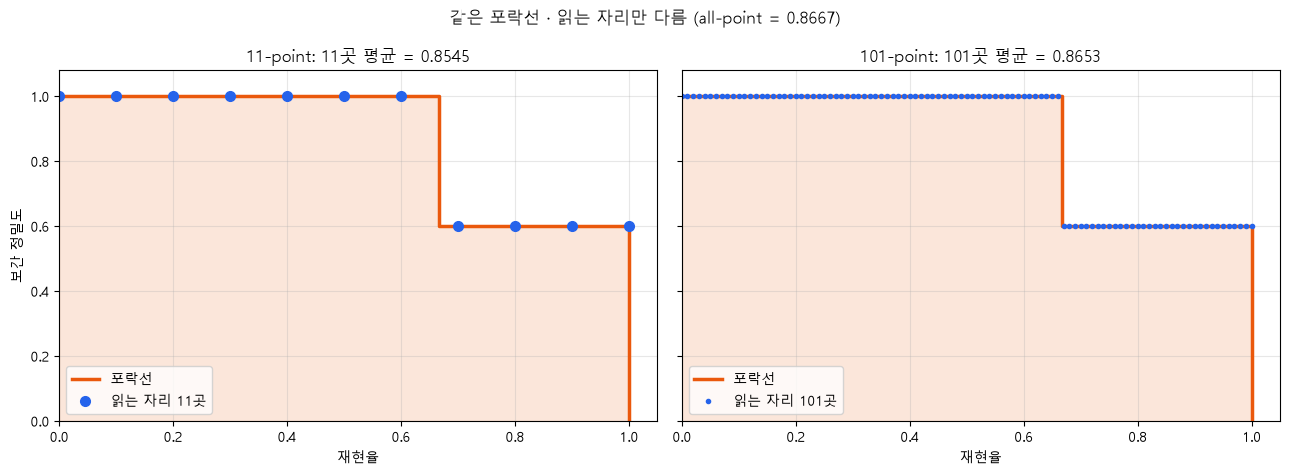

In [14]:
# 왜 · 옛 PASCAL VOC 방식 AP를 구하기 위해
def ap_11_point(rec, prec):                                                       # PASCAL VOC 2007
    """재현율 0, 0.1, …, 1.0마다 그 재현율 이상에서의 최고 정밀도를 읽어 평균"""  # 함수 설명
    return float(np.mean([prec[rec >= t].max() if (rec >= t).any() else 0.0       # 11곳 평균
                          for t in np.linspace(0, 1, 11)]))


# 왜 · COCO 방식 AP를 구하기 위해
def ap_101_point(rec, prec):                                         # COCO와 같은 읽는 법
    """재현율 0, 0.01, …, 1.0마다 보간 정밀도를 읽어 평균"""         # 함수 설명
    env = envelope(prec)                                             # 포락선
    idx = np.searchsorted(rec, np.linspace(0, 1, 101), side="left")  # 그 재현율에 처음 닿는 점
    return float(np.mean([env[i] if i < len(env) else 0.0 for i in idx]))  # 못 닿으면 0


# 왜 · 같은 판정이라도 계산 방식에 따라 AP가 달라지는 것을 보이기 위해
for name, (r, p) in {"모델 A": (rec_A, prec_A), "모델 B": (rec_B, prec_B)}.items():  # 두 모델
    # 세 방식
    print(f"{name}: all-point {ap_all_point(r, p):.4f} · 11-point {ap_11_point(r, p):.4f}"
          f" · 101-point {ap_101_point(r, p):.4f}")

# 왜 · 11-point · 101-point가 읽는 자리를 그림으로 비교하기 위해
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)                # 11곳 · 101곳
xa, ya, *_ = env_xy(rec_A, prec_A)                                            # 같은 포락선
for ax, n, name in [(axes[0], 11, "11-point"), (axes[1], 101, "101-point")]:  # 방식마다
    ax.fill_between(xa, ya, color=ENV_COLOR, alpha=0.15)                      # 넓이
    ax.plot(xa, ya, color=ENV_COLOR, lw=2.5, label="포락선")                  # 계단
    tr = np.linspace(0, 1, n)                                                 # 읽는 자리
    vals = [interp_precision(rec_A, prec_A, t) for t in tr]                   # 자리마다 높이
    ax.plot(tr, vals, "o", color=PRED_COLOR, ms=7 if n == 11 else 3, label=f"읽는 자리 {n}곳")  # 점
    ax.set_title(f"{name}: {n}곳 평균 = {np.mean(vals):.4f}", fontsize=12)    # 제목
    ax.set_xlabel("재현율", fontsize=10)                                      # x축
    ax.set_xlim(0, 1.05)                                                      # 범위
    ax.set_ylim(0, 1.08)                                                      # 범위
    ax.grid(alpha=0.3)                                                        # 격자
    ax.legend(fontsize=10, loc="lower left")                                  # 범례
axes[0].set_ylabel("보간 정밀도", fontsize=10)                                # y축
# 제목
fig.suptitle(f"같은 포락선 · 읽는 자리만 다름 (all-point = {ap_all_point(rec_A, prec_A):.4f})",
             fontsize=12)
plt.tight_layout()                                                            # 여백 정리
plt.show()                                                                    # 그림 출력

**결과** · 예측 정답은 다름 — `0.8653`

- `모델 A: all-point 0.8667 · 11-point 0.8545 · 101-point 0.8653` — 같은 판정 · 읽는 자리만 다름
- `모델 B: all-point 0.8333 · 11-point 0.8409 · 101-point 0.8342` — B는 11-point가 가장 높음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>all-point</td><td>재현율이 바뀌는 모든 자리 · 넓이 그대로</td><td>PASCAL VOC 2010 이후</td></tr>
<tr><td>11-point</td><td>재현율 0, 0.1, …, 1.0의 11곳 평균</td><td>PASCAL VOC 2007</td></tr>
<tr><td>101-point</td><td>재현율 0, 0.01, …, 1.0의 101곳 평균</td><td>COCO 공식 평가 · torchmetrics</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 직접 만든 함수 값을 'COCO mAP'라고 부르지 않음 → COCO는 최대 검출 수 · 크기 구간 등 규칙이 더 있음

> ✅ **한 줄 정리** · AP는 계산 방식마다 값이 조금 다르므로, 값과 함께 계산 방식을 적는다.

**딥러닝 코드에서는**

- torchmetrics `MeanAveragePrecision` = 101-point (객체탐지-1 6-2에서 일치 확인)

### 5-3. `A` 평가 IoU 임계값 · AP50 · AP75 · `ap_at()` <sub>원본 B6 · 셀 48 ~ 51</sub>

> 🎯 **평가 IoU 임계값을 0.5 → 0.75로 올리면 어느 박스의 판정이 바뀌는가?**

💡 **쉽게 말하면**

- 평가 IoU 임계값은 **채점의 깐깐함**.
- 0.5는 '대략 그 자리', 0.75는 '딱 맞게'.

**실행 흐름**

1. 기준 0.75로 다시 판정
2. 0.50 ~ 0.95 열 개 AP
3. AP50 · AP75 · 평균
4. 막대그림

**먼저 예측** · IoU 0.53으로 TP였던 0.60 박스는 0.75에서? — 답은 코드 실행 결과 아래에

컨피던스 0.60 박스: IoU 0.53 → 0.5에서 TP · 0.75에서 FP
평가 IoU 0.5에서 TP 박스들의 IoU: 0.89 · 0.88 · 0.53
평가 IoU 임계값별 AP: {0.5: 0.867, 0.55: 0.667, 0.6: 0.667, 0.65: 0.667, 0.7: 0.667, 0.75: 0.667, 0.8: 0.667, 0.85: 0.667, 0.9: 0.0, 0.95: 0.0}
AP50 = 0.8667 · AP75 = 0.6667 · IoU 0.50~0.95 평균 AP = 0.5533


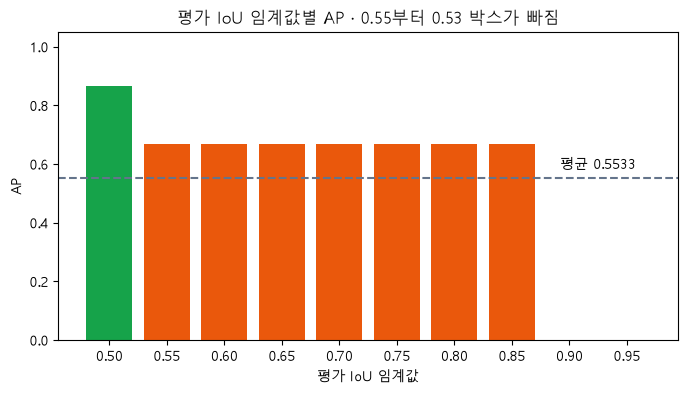

In [15]:
# 왜 · 평가 IoU 기준을 바꿔 다시 판정한 AP를 구하기 위해
def ap_at(preds, iou_thr):           # 평가 IoU 임계값 하나의 AP
    rows, _ = judge(preds, iou_thr)  # 그 기준으로 다시 판정
    r, p = pr_points(rows)           # PR 점
    return ap_all_point(r, p)        # all-point AP


# 왜 · IoU 0.75에서 TP가 FP로 바뀌는 예측을 찾기 위해
rows_75, _ = judge(PRED_A, 0.75)                                                 # 기준 0.75로 판정
for (c, ok5, *_), (_, ok75, v, *_) in zip(rows_A, rows_75):                      # 두 판정 비교
    if ok5 != ok75:                                                              # 판정이 바뀐 박스
        print(f"컨피던스 {c:.2f} 박스: IoU {v:.2f} → 0.5에서 TP · 0.75에서 FP")  # 바뀐 이유

# 왜 · COCO mAP가 여러 IoU 기준의 평균이라는 것을 직접 계산하기 위해
steps = np.round(np.arange(0.50, 0.96, 0.05), 2)                                 # 0.50 ~ 0.95, 10개
aps = {t: ap_at(PRED_A, t) for t in steps}                                       # 기준마다 AP
# 3개
print("평가 IoU 0.5에서 TP 박스들의 IoU:", " · ".join(f"{v:.2f}" for _, ok, v, *_ in rows_A if ok))
print("평가 IoU 임계값별 AP:", {float(t): round(v, 3) for t, v in aps.items()})  # 10개
print(f"AP50 = {aps[0.5]:.4f} · AP75 = {aps[0.75]:.4f} ·"                        # 세 숫자
      f" IoU 0.50~0.95 평균 AP = {np.mean(list(aps.values())):.4f}")

# 왜 · IoU 기준별 AP를 막대로 비교하기 위해
fig, ax = plt.subplots(figsize=(8, 4))                                         # 기준별 막대
# 높이별 색
cols = [GT_COLOR if v > 0.8 else ENV_COLOR if v > 0.5 else FP_COLOR for v in aps.values()]
ax.bar([f"{t:.2f}" for t in aps], list(aps.values()), color=cols)              # 막대 10개
ax.axhline(np.mean(list(aps.values())), color="#64748b", ls="--", lw=1.5)      # 평균선
# 평균값
ax.text(8.5, np.mean(list(aps.values())) + 0.03, f"평균 {np.mean(list(aps.values())):.4f}",
        ha="center", fontsize=10)
ax.set_ylim(0, 1.05)                                                           # 범위
ax.set_xlabel("평가 IoU 임계값", fontsize=10)                                  # x축
ax.set_ylabel("AP", fontsize=10)                                               # y축
ax.set_title("평가 IoU 임계값별 AP · 0.55부터 0.53 박스가 빠짐", fontsize=12)  # 제목
plt.show()                                                                     # 그림 출력

**결과** · 예측 정답은 `FP` — AP가 0.8667 → 0.6667

- `컨피던스 0.60 박스: IoU 0.53 → 0.5에서 TP · 0.75에서 FP` — 판정이 바뀐 박스는 하나
- `평가 IoU 0.5에서 TP 박스들의 IoU: 0.89 · 0.88 · 0.53` — 0.55부터 0.53 박스 탈락 · 0.9부터 셋 다
- `AP50 = 0.8667 · AP75 = 0.6667 · IoU 0.50~0.95 평균 AP = 0.5533` — 엄격할수록 낮아짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>AP50</td><td>평가 IoU 0.5</td><td>대략 맞으면 정답</td></tr>
<tr><td>AP75</td><td>평가 IoU 0.75</td><td>딱 맞아야 정답</td></tr>
<tr><td>IoU 0.50~0.95 평균</td><td>0.05 간격 10개 AP의 평균</td><td>COCO 대표 지표</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 논문 · 대회의 mAP가 AP50인지 0.50~0.95 평균인지 먼저 확인

> ✅ **한 줄 정리** · 평가 IoU 임계값을 올리면 덜 맞은 TP가 FP로 바뀌어 AP가 내려가고, 0.50~0.95 평균은 열 개 AP의 평균이다.

**딥러닝 코드에서는**

- `metric.compute()`의 `map_50` · `map_75` · `map`

---
## 6. mAP · 평균 IoU 반례

> **이 장의 흐름**
>
> - 5장까지는 클래스 하나
> - 클래스 평균 mAP와 미션 문서의 '평균 IoU'를 비교

<img src="images/pfo3_meaniou.png" alt="평균 IoU는 맞힌 박스만, AP는 놓침 · 오탐까지" width="763">

**파이프라인 위치** · ⑥ 평가 — 최종 보고 숫자

### 6-1. `A` mAP = 클래스별 AP 평균 · `(ap_cat + ap_dog) / 2` <sub>원본 B7 · 셀 52 ~ 55</sub>

> 🎯 **AP와 mAP는 무엇이 다른가?**

💡 **쉽게 말하면**

- AP는 **과목 하나의 점수**, mAP는 **과목 평균**.
- 평균 하나만 보면 약한 클래스를 놓칠 수 있음.

**실행 흐름**

1. 고양이 얼굴 AP50 (모델 A)
2. 개 얼굴 AP50 (둘 다 맞힘 → 1.0)
3. 평균 · 막대그림

**먼저 예측** · 고양이 0.8667 · 개 1.0의 mAP50은? — 답은 코드 실행 결과 아래에

고양이 얼굴 AP50 0.8667 · 개 얼굴 AP50 1.0000 → mAP50 = (0.8667 + 1.0000) ÷ 2 = 0.9333


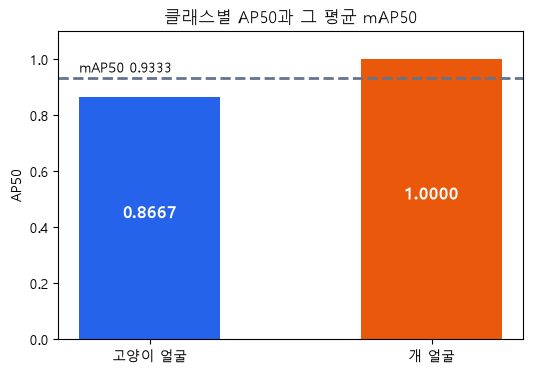

In [16]:
# 왜 · mAP가 클래스별 AP의 단순 평균이라는 것을 숫자로 확인하기 위해
ap_cat = ap_at(PRED_A, 0.5)  # 고양이 얼굴 = 모델 A
ap_dog = 1.0                 # 개 얼굴: 예측 2개가 순서대로 둘 다 TP → 넓이 1.0
print(f"고양이 얼굴 AP50 {ap_cat:.4f} · 개 얼굴 AP50 {ap_dog:.4f} →"  # 클래스별
      f" mAP50 = ({ap_cat:.4f} + {ap_dog:.4f}) ÷ 2 = {(ap_cat + ap_dog) / 2:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))                             # 막대 그림
# 두 AP
ax.bar(["고양이 얼굴", "개 얼굴"], [ap_cat, ap_dog], color=[PRED_COLOR, ENV_COLOR], width=0.5)
ax.axhline((ap_cat + ap_dog) / 2, color="#64748b", ls="--", lw=2)  # 평균선
# 평균값
ax.text(-0.25, (ap_cat + ap_dog) / 2 + 0.02, f"mAP50 {(ap_cat + ap_dog) / 2:.4f}", ha="left",
        fontsize=10)
for i, v in enumerate([ap_cat, ap_dog]):                           # 막대마다
    ax.text(i, v / 2, f"{v:.4f}", ha="center", color=INK, fontsize=12, fontweight="bold")  # 값
ax.set_ylim(0, 1.1)                                                # 범위
ax.set_ylabel("AP50", fontsize=10)                                 # y축
ax.set_title("클래스별 AP50과 그 평균 mAP50", fontsize=12)         # 제목
plt.show()                                                         # 그림 출력

**결과** · 예측 정답은 `0.9333`

- `고양이 얼굴 AP50 0.8667 · 개 얼굴 AP50 1.0000 → mAP50 = (0.8667 + 1.0000) ÷ 2 = 0.9333` — 클래스 2개의 평균

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>AP</td><td>클래스 하나</td><td>약한 클래스 찾기</td></tr>
<tr><td>mAP</td><td>클래스별 AP의 평균</td><td>모델 전체 비교</td></tr>
<tr><td>mAP + 클래스별 AP</td><td>둘 다 적기</td><td>보고 (기본)</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 이름 정리: AP50 · mAP50 (0.5) · AP75 · mAP75 (0.75) · 0.50~0.95 평균

> ✅ **한 줄 정리** · mAP는 클래스별 AP의 평균이므로 클래스별 AP와 함께 적는다.

**딥러닝 코드에서는**

- `MeanAveragePrecision(class_metrics=True)` → `map_per_class`

### 6-2. `A` 평균 IoU 반례 · `PRED_C` · `PRED_D` <sub>원본 B8 · 셀 56 ~ 59</sub>

> 🎯 **맞힌 박스의 평균 IoU가 높으면 좋은 모델인가?**

💡 **쉽게 말하면**

- 평균 IoU는 **맞힌 문제를 얼마나 깔끔하게 풀었나**만 봄.
- 안 푼 문제(FN) · 틀린 답(FP)은 세지 않음.

**실행 흐름**

1. 모델 C: 1개 · 딱 맞음
2. 모델 D: 3개 · 적당히
3. 평균 IoU · AP50 비교 · 막대그림

**먼저 예측** · 평균 IoU가 높은 C와 AP50이 높은 모델은 같을까? — 답은 코드 실행 결과 아래에

모델 C: 맞힌 박스 1개 · 맞힌 박스 평균 IoU 0.980 · 놓친 정답 2개 · AP50 0.333
모델 D: 맞힌 박스 3개 · 맞힌 박스 평균 IoU 0.673 · 놓친 정답 0개 · AP50 1.000


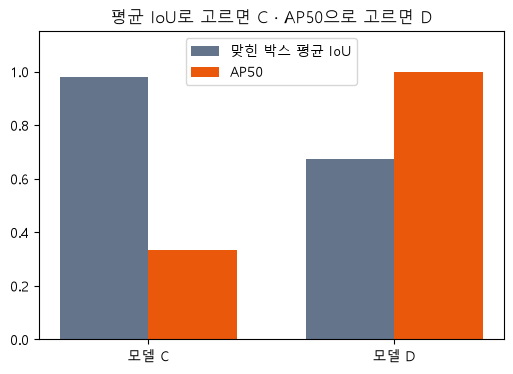

In [17]:
# 왜 · 평균 IoU가 높아도 놓친 정답이 많으면 나쁜 모델이라는 반례를 만들기 위해
PRED_C = [(0.90, "사진1", [10, 10, 60, 59])]  # 모델 C: 1개만 · 딱 맞음
PRED_D = [(0.90, "사진1", [16, 14, 66, 62]), (0.85, "사진1", [106, 25, 156, 75]),  # 모델 D: 3개
          (0.80, "사진2", [37, 36, 97, 96])]  # 셋 다 적당히

# 왜 · 두 모델의 평균 IoU와 AP를 나란히 비교하기 위해
res = {}                                                      # 모델마다 (평균 IoU, AP50)
for name, preds in [("모델 C", PRED_C), ("모델 D", PRED_D)]:  # 두 모델
    rows, fn = judge(preds, 0.5)                              # 판정
    tp_ious = [v for _, ok, v, *_ in rows if ok]              # 맞힌 박스의 IoU
    r, p = pr_points(rows)                                    # PR 점
    res[name] = (np.mean(tp_ious), ap_all_point(r, p))        # 두 숫자
    # 비교
    print(f"{name}: 맞힌 박스 {len(tp_ious)}개 · 맞힌 박스 평균 IoU {np.mean(tp_ious):.3f} ·"
          f" 놓친 정답 {fn}개 · AP50 {ap_all_point(r, p):.3f}")

fig, ax = plt.subplots(figsize=(6, 4))                                           # 막대 비교
x = np.arange(2)                                                                 # 모델 2개 자리
# 회색
ax.bar(x - 0.18, [res[n][0] for n in res], 0.36, color="#64748b", label="맞힌 박스 평균 IoU")
ax.bar(x + 0.18, [res[n][1] for n in res], 0.36, color=ENV_COLOR, label="AP50")  # 주황
ax.set_xticks(x)                                                                 # 눈금 자리
ax.set_xticklabels(list(res))                                                    # 모델 이름
ax.set_ylim(0, 1.15)                                                             # 범위
ax.legend(fontsize=10, loc="upper center")                                       # 범례
ax.set_title("평균 IoU로 고르면 C · AP50으로 고르면 D", fontsize=12)             # 제목
plt.show()                                                                       # 그림 출력

**결과** · 예측 정답은 다름 — AP50은 D(1.000), C는 0.333

- `모델 C: 맞힌 박스 1개 · 맞힌 박스 평균 IoU 0.980 · 놓친 정답 2개 · AP50 0.333` — 놓친 2개가 평균 IoU에 안 들어감
- `모델 D: 맞힌 박스 3개 · 맞힌 박스 평균 IoU 0.673 · 놓친 정답 0개 · AP50 1.000` — 셋 다 찾음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>맞힌 박스 평균 IoU</td><td>TP만 평균</td><td>박스를 얼마나 딱 맞게 쳤나 (진단)</td></tr>
<tr><td>AP · mAP</td><td>TP · FP · FN 모두 반영</td><td>모델 고르기 (기본)</td></tr>
<tr><td>둘 다</td><td>맞힌 정도 + 전체 성능</td><td>보고서</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 평균 IoU를 쓸 때는 어떤 박스만 모았는지 함께 적음

> ✅ **한 줄 정리** · 맞힌 박스의 평균 IoU는 놓친 정답과 틀린 박스를 세지 않아 mAP를 대신할 수 없다.

**딥러닝 코드에서는**

- 미션 문서의 'IOU' 지표 = 진단용 · 모델 선택은 mAP

---
## 7. 종합 실습 · 미션 노트북에 결과 적기

> **이 장의 흐름**
>
> - 1 ~ 6장의 값을 원본 B9 형식 한 문장에 모음
> - 점검표를 코드로 확인하고, 조건만 바꾼 숫자를 나란히 봄

<img src="images/pfo3_report.png" alt="결과를 적는 한 문장 = 조건 다섯 칸 + 값" width="762">

**파이프라인 위치** · ⑥ 평가 → ⑦ 기록

> 🎯 **같은 예측의 평가 결과를 조건과 함께 한 문장으로 적고 점검표를 통과하려면?**

💡 **쉽게 말하면**

- 숫자만 적으면 **어떤 시험지로 몇 점**인지 모름.
- 조건(IoU · 하한 · 방식 · 정답 수)을 함께 적어야 다시 재현됨.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">단계</th><th style="text-align: left;">하는 일</th><th style="text-align: left;">쓰는 문법</th></tr>
</thead>
<tbody>
<tr><td>1</td><td>평가 조건 · 클래스별 AP50 · mAP50 모으기</td><td>4-3 · 6-1</td></tr>
<tr><td>2</td><td>실제로 쓸 임계값 0.5의 정밀도 · 재현율 · F1</td><td>3-1</td></tr>
<tr><td>3</td><td>B9 형식 한 문장 만들기</td><td>원본 B9</td></tr>
<tr><td>4</td><td>점검표 5가지를 코드로 확인</td><td>원본 B9 점검표</td></tr>
<tr><td>5</td><td>조건만 바꾼 AP 네 개 비교</td><td>5-1 ~ 5-3</td></tr>
</tbody></table>

**먼저 예측** · 같은 예측에서 조건만 바꾼 AP 네 개 중 가장 낮은 값은? — 답은 코드 실행 결과 아래에

In [18]:
# 1) 미션 노트북에 적을 값 모으기 (모델 A · 고양이 얼굴 + 개 얼굴 예시)
# 왜 · 보고에 필요한 조건 · 값을 한곳에 모으기 위해
conf_floor = min(c for c, *_ in PRED_A)               # 예측을 모은 컨피던스 하한 (0.40)
report = {"split": "예시 사진 2장", "평가 IoU": 0.5,  # 평가 조건
          "컨피던스 하한": conf_floor,
          "계산 방식": "우리 평가 함수 all-point", "정답 수": {"고양이 얼굴": N_GT, "개 얼굴": 2},
          "AP50": {"고양이 얼굴": round(ap_cat, 4), "개 얼굴": round(ap_dog, 4)}}
report["mAP50"] = round((ap_cat + ap_dog) / 2, 4)     # 클래스 평균
tp, fp, fn, p, r, f1 = prf(rows_A, 0.5)               # 실제로 쓸 임계값 0.5의 성적 (고양이)
# 따로 적음
report["임계값 0.5"] = {"정밀도": round(p, 3), "재현율": round(r, 3), "F1": round(f1, 3)}

# 2) B9 한 문장 형식으로
# 왜 · 조건과 값을 빠짐없이 한 문장으로 쓰는 연습을 하기 위해
# 조건
sentence = (f"{report['split']} · 평가 IoU {report['평가 IoU']} · 컨피던스 {conf_floor} 이상으로"
            f" 모은 예측 전부 · {report['계산 방식']}"
            f" · 고양이 얼굴 정답 {N_GT}개 · 개 얼굴 정답 2개"
            f" → 고양이 AP50 {ap_cat:.4f} · 개 AP50 {ap_dog:.4f} · mAP50 {report['mAP50']:.4f}")
print(sentence)                                      # 한 문장
print("임계값 0.5 (고양이):", report["임계값 0.5"])  # 실제로 쓸 기준

예시 사진 2장 · 평가 IoU 0.5 · 컨피던스 0.4 이상으로 모은 예측 전부 · 우리 평가 함수 all-point · 고양이 얼굴 정답 3개 · 개 얼굴 정답 2개 → 고양이 AP50 0.8667 · 개 AP50 1.0000 · mAP50 0.9333
임계값 0.5 (고양이): {'정밀도': 0.6, '재현율': 1.0, 'F1': 0.75}


**실행 흐름**

1. 보고 점검표 항목을 코드로 확인
2. 같은 예측에서 조건만 바꾼 네 가지 숫자 비교

In [19]:
# 3) 점검표를 코드로 확인 (원본 B9의 7가지 중 숫자로 볼 수 있는 것)
# 왜 · 보고에 빠진 조건이 없는지 사람이 아니라 코드로 확인하기 위해
checks = {  # 점검 항목 → 통과 여부
    "평가 IoU 임계값을 적었나": "평가 IoU" in report,                               # AP50인지 명시
    "먼저 자르지 않았나 (컨피던스 하한 ≤ 0.5)": report["컨피던스 하한"] <= 0.5,     # 0.4까지 모음
    "계산 방식을 적었나 · COCO라고 부르지 않았나": "COCO" not in report["계산 방식"],  # 우리 함수
    # 두 클래스
    "클래스별 AP와 정답 수를 적었나": len(report["AP50"]) == len(report["정답 수"]) == 2,
    "실제 임계값의 정밀도 · 재현율 · F1을 적었나": len(report["임계값 0.5"]) == 3,  # 따로 적음
}
for k, v in checks.items():                                                         # 항목마다
    print(f"{'통과' if v else '빠짐'} · {k}")                                       # 결과
print("모두 통과:", all(checks.values()))                                           # 최종

# 4) 같은 예측 · 조건만 바꾸면 숫자가 얼마나 달라지나 (조건을 적어야 하는 이유)
# 왜 · 조건을 적지 않으면 숫자를 비교할 수 없다는 것을 보이기 위해
variants = {"AP50 all-point": ap_all_point(rec_A, prec_A),       # 기준
            "AP50 101-point": ap_101_point(rec_A, prec_A),       # 계산 방식만 다름
            "AP75 all-point": ap_at(PRED_A, 0.75),               # 평가 IoU만 다름
            "0.75 먼저 자른 AP50": ap_all_point(rec_c, prec_c)}  # 하한만 다름
for k, v in variants.items():                                    # 조건마다
    print(f"{k:16s} {v:.4f}")                                    # 같은 예측 · 다른 숫자

통과 · 평가 IoU 임계값을 적었나
통과 · 먼저 자르지 않았나 (컨피던스 하한 ≤ 0.5)
통과 · 계산 방식을 적었나 · COCO라고 부르지 않았나
통과 · 클래스별 AP와 정답 수를 적었나
통과 · 실제 임계값의 정밀도 · 재현율 · F1을 적었나
모두 통과: True
AP50 all-point   0.8667
AP50 101-point   0.8653
AP75 all-point   0.6667
0.75 먼저 자른 AP50  0.6667


**결과** · 예측 정답은 `0.6667` — AP75와 '0.75 먼저 자른 AP50'이 같은 값

- `고양이 AP50 0.8667 · 개 AP50 1.0000 · mAP50 0.9333` — B9 한 문장의 끝부분 · 조건이 앞에 붙음
- `임계값 0.5 (고양이): {'정밀도': 0.6, '재현율': 1.0, 'F1': 0.75}` — 실제로 쓸 기준은 따로 적음
- `모두 통과: True` — 점검표 5가지 통과
- `AP50 all-point   0.8667` — 기준 값
- `AP50 101-point   0.8653` — 계산 방식만 바꿈
- `AP75 all-point   0.6667` — 평가 IoU만 바꿈
- `0.75 먼저 자른 AP50  0.6667` — 하한만 바꿈 · 같은 예측인데 숫자가 네 가지

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">방법</th><th style="text-align: left;">차이</th><th style="text-align: left;">언제 쓰나</th></tr>
</thead>
<tbody>
<tr><td>숫자만 적기</td><td>조건을 모름 → 재현 불가</td><td>쓰지 않음</td></tr>
<tr><td>B9 한 문장</td><td>split · IoU · 하한 · 방식 · 정답 수 · 값</td><td>미션 보고 (기본)</td></tr>
<tr><td>점검표</td><td>빠진 조건 찾기</td><td>제출 전 확인</td></tr>
<tr><td>임계값 하나의 F1</td><td>서비스 기준 성적</td><td>AP와 함께 따로</td></tr>
</tbody></table>

> ⚠️ **주의**
>
> - 모델 · 설정 고르기는 val로, test는 마지막에 한 번만 (원본 B9 점검표 마지막 줄)

> ✅ **한 줄 정리** · 평가 결과는 평가 IoU · 컨피던스 하한 · 계산 방식 · 클래스별 정답 수와 함께 한 문장으로 적어야 재현된다.

**딥러닝 코드에서는**

- 객체탐지-2 7장 '결과를 적는 한 문장'이 이 형식
- ultralytics `val` 결과도 같은 조건을 함께 적음 (객체탐지-3)

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">학습 목표</th><th style="text-align: left;">할 수 있게 된 것</th><th style="text-align: left;">확인 위치</th></tr>
</thead>
<tbody>
<tr><td>1. IoU · TN 없음</td><td>옆으로 20 밀린 박스 IoU 0.429 · 탐지 칸은 TP · FP · FN</td><td>1-1 · 2-1</td></tr>
<tr><td>2. 짝짓기 · 정밀도 · 재현율</td><td>0.80 박스는 IoU 0.85여도 중복 FP · 0.75 이상 F1 0.667</td><td>2-3 · 3-1</td></tr>
<tr><td>3. AP 직접 계산</td><td>(2/3) × 1.0 + (1/3) × 0.6 = 0.8667</td><td>4-1 ~ 4-3</td></tr>
<tr><td>4. 조건 세 가지</td><td>먼저 자르면 0.6667 · 101-point 0.8653 · AP75 0.6667</td><td>5-1 ~ 5-3</td></tr>
<tr><td>5. mAP · 보고</td><td>mAP50 0.9333 · 평균 IoU 0.980인 C의 AP50은 0.333</td><td>6 · 7장</td></tr>
</tbody></table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">등급</th><th style="text-align: left;">주제</th><th style="text-align: left;">반드시 기억할 것</th><th style="text-align: left;">딥러닝 코드에서</th></tr>
</thead>
<tbody>
<tr><td><code>A</code></td><td>IoU</td><td>겹친 넓이 ÷ 합친 넓이</td><td><code>box_iou(pred, gt)</code></td></tr>
<tr><td><code>A</code></td><td>TP · FP · FN</td><td>컨피던스 순 · 짝 없는 정답 · TN 없음</td><td>torchmetrics 안에서 실행</td></tr>
<tr><td><code>A</code></td><td>정밀도 · 재현율</td><td>분모 = 낸 박스 · 정답</td><td>임계값 하나의 성적</td></tr>
<tr><td><code>A</code></td><td>PR 점 · 포락선</td><td>한 박스씩 · 오른쪽 최댓값</td><td><code>np.maximum.accumulate</code></td></tr>
<tr><td><code>A</code></td><td>AP</td><td>포락선 아래 넓이</td><td><code>metric.compute()["map_50"]</code></td></tr>
<tr><td><code>A</code></td><td>평가 조건</td><td>하한 · 계산 방식 · 평가 IoU</td><td>한 문장에 함께</td></tr>
<tr><td><code>A</code></td><td>mAP</td><td>클래스별 AP 평균</td><td><code>class_metrics=True</code></td></tr>
<tr><td><code>B</code></td><td>평균 IoU</td><td>TP만 평균 → mAP 대신 못 함</td><td>진단용</td></tr>
</tbody></table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

*섹션 → 🎯 질문*

- **1-1** · IoU는 어떻게 계산하는가?
- **2-1** · 탐지에 TN이 없는 이유는?
- **2-3** · 이미 짝 있는 정답과 많이 겹친 예측은?
- **3-1** · 정밀도와 재현율의 분모는?
- **3-2** · 임계값을 내리면 정밀도는 꼭 내려가는가?
- **3-3** · 임계값 하나의 F1로 비교하면 안 되는 이유는?
- **4-1** · FP가 들어오면 PR 점은 어디로?
- **4-2** · 포락선은 무엇인가?
- **4-3** · AP는 무엇의 넓이인가?
- **5-1** · AP 전에 0.75로 먼저 자르면?
- **5-2** · all-point · 11 · 101-point의 차이는?
- **5-3** · 평가 IoU 0.75로 올리면?
- **6-1** · mAP는 무엇의 평균인가?
- **6-2** · 평균 IoU가 mAP를 대신 못 하는 이유는?

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 정답 `[0, 0, 100, 100]` · 예측 `[50, 0, 150, 100]`의 IoU를 직접 계산
2. 판정 순서 TP · FP · TP · FP, 정답 2개일 때 재현율 · 정밀도 · 포락선 · all-point AP

In [20]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 모델 A에서 0.40 박스를 빼면 all-point AP는 바뀔까? (마지막 TP 뒤의 FP)
2. 모델 B를 평가 IoU 0.75로 판정하면 AP는? `ap_at(PRED_B, 0.75)`로 확인
3. 개 얼굴 AP50이 0.5라면 mAP50은? (고양이 0.8667)

In [21]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

*섹션 → 답*

- **1-1** · 겹친 넓이 ÷ (두 넓이 합 - 겹친 넓이)
- **2-1** · 물체 없는 자리의 개수가 정해지지 않아 셀 수 없음
- **2-3** · FP (중복)
- **3-1** · 낸 박스 수 · 정답 수
- **3-2** · 아님 · TP가 들어오면 다시 오름
- **3-3** · 기준마다 앞서는 모델이 바뀜
- **4-1** · 재현율 그대로 · 정밀도만 아래로
- **4-2** · 그 재현율 이상에서 얻을 수 있는 최고 정밀도의 계단
- **4-3** · 포락선 아래 넓이
- **5-1** · 곡선 뒤가 사라져 AP 감소 (0.8667 → 0.6667)
- **5-2** · 넓이 그대로 · 11곳 평균 · 101곳 평균
- **5-3** · 덜 맞은 TP가 FP가 되어 AP 감소
- **6-1** · 클래스별 AP
- **6-2** · FN · FP가 들어가지 않음

#### 코드 문제 답

```python
# 1. 겹친 50 × 100 = 5000 · 합친 10000 + 10000 - 5000 = 15000
a, b = [0, 0, 100, 100], [50, 0, 150, 100]
inter = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))
print(round(inter / (100 * 100 * 2 - inter), 4))  # 0.3333

# 2. 누적 TP → 재현율 · 정밀도 → 포락선 → 넓이 0.5 × 1.0 + 0.5 × 0.667
tp = np.cumsum([1, 0, 1, 0])
rec, prec = tp / 2, tp / np.arange(1, 5)
env = np.maximum.accumulate(prec[::-1])[::-1]
print(rec.tolist())  # [0.5, 0.5, 1.0, 1.0]
print(env.round(3).tolist())  # [1.0, 0.667, 0.667, 0.5]
print(round(0.5 * env[0] + 0.5 * env[2], 4))  # 0.8333
```

#### 변형 문제 답

*문제 → 답*

- **1** · 안 바뀜 · 0.8667 (재현율 1에 이미 닿은 뒤의 FP는 넓이에 영향 없음)
- **2** · 그대로 0.8333 · B의 TP 박스 IoU가 0.92 · 0.94 · 0.92로 모두 0.75 이상
- **3** · 두 값의 평균 → 약 0.68 · 약한 클래스가 평균을 끌어내림

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">틀린 내용</th><th style="text-align: left;">틀린 이유</th><th style="text-align: left;">올바른 원칙</th><th style="text-align: left;">재발 방지 질문</th></tr>
</thead>
<tbody>
<tr><td>(예) 0.80 박스를 TP로 답함</td><td>IoU 0.85만 보고 그 정답의 짝을 확인 안 함</td><td>정답 하나에 예측 하나</td><td>이 정답은 이미 짝이 있나?</td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
<tr><td></td><td></td><td></td><td></td></tr>
</tbody></table>

---
## 면접 30초 답변

**Q1. 탐지 모델은 왜 정확도 대신 정밀도와 재현율로 평가하나요?**
> - 탐지에서 TN은 물체가 없는 자리에 박스를 치지 않은 경우인데, 그런 자리의 개수가 정해져 있지 않아 셀 수 없습니다.
> - 그래서 정답과 예측을 IoU로 1 : 1 짝지어 TP · FP · FN만 세고, 정밀도와 재현율로 평가합니다.

**Q2. AP는 어떻게 계산하나요?**
> - 예측을 컨피던스 높은 순으로 세워 한 박스씩 더하며 재현율과 정밀도 점을 찍습니다.
> - 오른쪽에서 본 최고 정밀도로 계단 모양 포락선을 만들고, 그 아래 넓이가 AP입니다.
> - 계산 방식은 all-point · 11-point · 101-point가 있어 함께 적습니다.

**Q3. 같은 모델인데 mAP가 서로 다르게 보고되는 이유는?**
> - 평가 IoU 임계값(0.5 또는 0.50~0.95 평균), 계산 방식, 예측을 모은 컨피던스 하한이 다르면 같은 예측이어도 값이 달라집니다.
> - 그래서 결과는 이 조건과 클래스별 정답 수를 함께 적은 한 문장으로 보고합니다.

**Q4. 맞힌 박스의 평균 IoU가 높으면 좋은 모델인가요?**
> - 아닙니다.
> - 평균 IoU는 맞힌 박스만 평균하므로 놓친 정답과 헛짚은 박스가 반영되지 않습니다.
> - 정답 세 개 중 하나만 딱 맞힌 모델은 평균 IoU 0.98이어도 AP50은 0.33이라, 모델 선택은 mAP로 합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>iou(a, b)</code></td><td>직접 만든 함수</td><td>겹친 넓이 ÷ 합친 넓이</td><td>1-1 <code>return inter / union</code></td></tr>
<tr><td><code>judge(preds, iou_thr)</code></td><td>직접 만든 함수</td><td>짝짓기 → TP · FP · FN</td><td>2-3 <code>rows_A, fn_A = judge(PRED_A, 0.5)</code></td></tr>
<tr><td><code>prf(rows, conf_thr)</code></td><td>직접 만든 함수</td><td>정밀도 · 재현율 · F1</td><td>3-1 <code>prf(rows_A, 0.75)</code></td></tr>
<tr><td><code>pr_points(rows)</code></td><td>직접 만든 함수</td><td>PR 점</td><td>4-1 <code>rec_A, prec_A = pr_points(rows_A)</code></td></tr>
<tr><td><code>np.cumsum()</code></td><td>numpy</td><td>누적 TP</td><td>4-1 <code>tp = np.cumsum([ok for _, ok, *_ in rows])</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td><code>envelope(prec)</code> · <code>np.maximum.accumulate()</code></td><td>직접 만든 함수 · numpy</td><td>포락선</td><td>4-2 <code>np.maximum.accumulate(prec[::-1])[::-1]</code></td></tr>
<tr><td><code>ap_all_point(rec, prec)</code></td><td>직접 만든 함수</td><td>포락선 아래 넓이</td><td>4-3 <code>ap_all_point(rec_A, prec_A)</code></td></tr>
<tr><td><code>ap_11_point</code> · <code>ap_101_point</code></td><td>직접 만든 함수</td><td>정해진 자리 평균</td><td>5-2 <code>ap_101_point(r, p)</code></td></tr>
<tr><td><code>np.searchsorted(rec, 자리, side="left")</code></td><td>numpy</td><td>재현율 자리 찾기</td><td>5-2 <code>np.searchsorted(rec, np.linspace(0, 1, 101), side="left")</code></td></tr>
<tr><td><code>ap_at(preds, iou_thr)</code></td><td>직접 만든 함수</td><td>평가 IoU 하나의 AP</td><td>5-3 <code>aps = {t: ap_at(PRED_A, t) for t in steps}</code></td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">함수·문법</th><th style="text-align: left;">소속</th><th style="text-align: left;">역할</th><th style="text-align: left;">코드에서 사용한 위치</th></tr>
</thead>
<tbody>
<tr><td>mAP = 클래스 평균</td><td>평가 지표</td><td>클래스별 AP 평균</td><td>6-1 <code>(ap_cat + ap_dog) / 2</code></td></tr>
</tbody></table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">✅ 할 것</th><th style="text-align: left;">⚠️ 하지 말 것</th></tr>
</thead>
<tbody>
<tr><td>예측은 컨피던스 높은 순으로 짝짓기</td><td>순서를 무시하고 판정</td></tr>
<tr><td>AP는 낮은 컨피던스까지 모은 예측으로</td><td>0.5로 먼저 자른 뒤 AP 계산</td></tr>
<tr><td>계산 방식 · 평가 IoU를 함께 적기</td><td>직접 만든 값을 'COCO mAP'라고 부르기</td></tr>
<tr><td>mAP와 클래스별 AP를 함께</td><td>평균 IoU 하나로 모델 고르기</td></tr>
</tbody></table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">짝</th><th style="text-align: left;">차이</th><th style="text-align: left;">결론</th></tr>
</thead>
<tbody>
<tr><td>컨피던스 vs 컨피던스 임계값</td><td>박스에 붙은 값 vs 어디까지 볼지</td><td>둘 다 '점수'라 부르지 않기</td></tr>
<tr><td>컨피던스 임계값 vs 평가 IoU 임계값</td><td>어떤 박스까지 vs 얼마나 겹쳐야</td><td>이름을 붙여 쓰기</td></tr>
<tr><td>정밀도 vs 재현율</td><td>낸 박스 기준 vs 정답 기준</td><td>분모부터 확인</td></tr>
<tr><td>PR 점 vs 포락선</td><td>지그재그 vs 계단</td><td>넓이는 포락선으로</td></tr>
<tr><td>all-point vs 101-point</td><td>넓이 그대로 vs 101곳 평균</td><td>방식을 적기</td></tr>
<tr><td>AP50 vs 0.50~0.95 평균</td><td>대략 vs 엄격 평균</td><td>어느 것인지 밝히기</td></tr>
<tr><td>평균 IoU vs mAP</td><td>TP만 vs TP · FP · FN</td><td>선택은 mAP</td></tr>
</tbody></table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">언제</th><th style="text-align: left;">할 일</th><th style="text-align: left;">걸리는 시간</th></tr>
</thead>
<tbody>
<tr><td>내일</td><td>기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td><td>15분</td></tr>
<tr><td>3일 뒤</td><td>변형 문제 3개 · 4-3 계단 넓이를 종이에 다시</td><td>20분</td></tr>
<tr><td>7일 뒤</td><td>7장 한 문장을 객체탐지-2의 실제 결과로 다시 써 보기</td><td>20분</td></tr>
<tr><td>14일 뒤</td><td>오답 노트에 남은 문제만 · 객체탐지-1 5 · 6장 ✅ 줄 읽기</td><td>10분</td></tr>
</tbody></table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 · `평가지표_보충_v2.html` 63셀을 순서 그대로 6장 13섹션으로 (A1 ~ A7 · B1 ~ B8)
- 원본 B9(미션 노트북에 적는 법)와 마지막 정리 그림은 7장 종합 실습으로
- 그림 코드는 원본과 같은 계산 · 색만 흰 배경용으로 바꾸고, 긴 줄은 나눔
- 모든 코드는 실행한 출력과 함께 저장 · 형식 v2.1 (FORMAT_V2.md 1 ~ 7절)

### 읽는 법

*표시 → 의미*

- **`A` · `B`** · **A** 딥러닝 코드에 바로 나오는 필수 · **B** 알아두면 되는 것
- **🎯** · 이번 섹션에서 답해야 할 질문
- **💡** · 쉬운 설명 · 비유
- **⚠️** · 자주 하는 실수
- **✅** · 기억할 결론 = 🎯 질문의 답

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>셀 0 · 1</td><td>표지 · 용어 세 개 (컨피던스 · 컨피던스 임계값 · 평가 IoU 임계값)</td><td>0장 · 원본 힌트</td></tr>
<tr><td>A1 · 셀 2 ~ 4</td><td>IoU 손계산 · 그림</td><td>1-1</td></tr>
<tr><td>A2 · 셀 5 · 6</td><td>혼동 행렬 vs 탐지 · 그림</td><td>2-1</td></tr>
<tr><td>A3 · 셀 7 · 8</td><td>예시 데이터 · 모델 A</td><td>2-2</td></tr>
<tr><td>A4 · 셀 9 ~ 12</td><td>짝짓기 · 판정 그림</td><td>2-3 · 2-4</td></tr>
<tr><td>A5 · 셀 13 ~ 16</td><td>정밀도 · 재현율 · F1 · 분모 그림</td><td>3-1</td></tr>
<tr><td>A6 · 셀 17 ~ 20</td><td>임계값 0.9 · 0.7 · 0.5</td><td>3-2</td></tr>
<tr><td>A7 · 셀 21 ~ 24</td><td>모델 B · F1 곡선</td><td>3-3</td></tr>
<tr><td>B1 · 셀 25 ~ 28</td><td>PR 점</td><td>4-1</td></tr>
<tr><td>B2 · 셀 29 ~ 31</td><td>보간 · 포락선</td><td>4-2</td></tr>
<tr><td>B3 · 셀 32 ~ 39</td><td>AP = 넓이 · 수업 Day02 그림 다시 읽기(셀 36 · 그림 없음 → 숫자로)</td><td>4-3</td></tr>
<tr><td>B4 · 셀 40 ~ 43</td><td>먼저 자르기</td><td>5-1</td></tr>
</tbody></table>

<table width="100%" style="width:100%; table-layout:auto">
<thead><tr><th style="text-align: left;">원본</th><th style="text-align: left;">내용</th><th style="text-align: left;">이 노트북</th></tr>
</thead>
<tbody>
<tr><td>B5 · 셀 44 ~ 47</td><td>계산 방식 3가지</td><td>5-2</td></tr>
<tr><td>B6 · 셀 48 ~ 51</td><td>평가 IoU · AP50 · AP75 (TP 박스 그림은 막대그림으로 통합)</td><td>5-3</td></tr>
<tr><td>B7 · 셀 52 ~ 55</td><td>mAP</td><td>6-1</td></tr>
<tr><td>B8 · 셀 56 ~ 59</td><td>평균 IoU 반례 (박스 그림은 막대그림으로 통합)</td><td>6-2</td></tr>
<tr><td>B9 · 셀 60</td><td>미션 노트북에 적는 법 · 점검표</td><td>7</td></tr>
<tr><td>정리 · 셀 61 · 62</td><td>정리 · 박스 하나에서 mAP까지 그림</td><td>그래서 오늘 무엇을 배웠는가? · 7장 그림</td></tr>
</tbody></table>

### 전체 코드

1 ~ 7장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

**실행 흐름**

1. 1-1 IoU 손계산 · 그림

옆으로 20 밀린 박스 [30, 10, 80, 60] → IoU 0.429
거의 같은 박스   [12, 12, 60, 62] → IoU 0.888


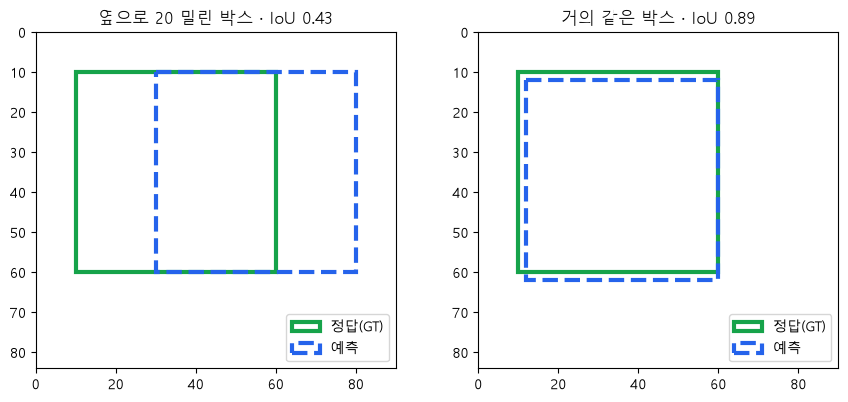

In [22]:
# ---------- 1-1 ----------
# 왜 · IoU 공식을 직접 구현해 손계산과 맞춰 보기 위해
def iou(a, b):                                     # 박스 [x1, y1, x2, y2] 두 개 → IoU
    """겹친 넓이 ÷ 합친 넓이"""                    # 함수 설명
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))  # 겹친 가로 (음수면 0)
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))  # 겹친 세로 (음수면 0)
    inter = w * h                                  # 겹친 넓이
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter  # 겹침은 한 번만
    return inter / union                           # 0 ~ 1


# 왜 · 많이 밀린 박스와 거의 같은 박스의 IoU 차이를 숫자로 보기 위해
gt = [10, 10, 60, 60]                                # 정답 50 × 50 = 2500
pairs = {"옆으로 20 밀린 박스": [30, 10, 80, 60], "거의 같은 박스": [12, 12, 60, 62]}  # 예측 2개
for name, p in pairs.items():                        # 예측마다
    print(f"{name:10s} {p} → IoU {iou(gt, p):.3f}")  # 숫자로 확인

# 왜 · 두 경우의 겹침을 그림으로 확인하기 위해
fig, axes = plt.subplots(1, 2, figsize=(9, 4))                   # 두 경우 나란히
for ax, (name, p) in zip(axes, pairs.items()):                   # 경우마다
    ax.add_patch(patches.Rectangle(gt[:2], 50, 50, fill=False, ec=GT_COLOR, lw=3,  # 정답 = 초록
                                   label="정답(GT)"))
    ax.add_patch(patches.Rectangle(p[:2], p[2] - p[0], p[3] - p[1], fill=False,  # 예측 = 파랑 점선
                                   ec=PRED_COLOR, lw=3, ls="--", label="예측"))
    ax.set_xlim(0, 90)                                           # 가로 범위
    ax.set_ylim(84, 0)                                           # 세로는 위가 0 (사진 좌표)
    ax.set_aspect("equal")                                       # 정사각형 비율
    ax.set_title(f"{name} · IoU {iou(gt, p):.2f}", fontsize=12)  # 제목에 IoU
    ax.legend(loc="lower right", fontsize=10)                    # 범례
plt.tight_layout()                                               # 여백 정리
plt.show()                                                       # 그림 출력

**실행 흐름**

1. 2-1 분류 혼동 행렬 vs 탐지
2. 2-2 정답 · 모델 A 예측

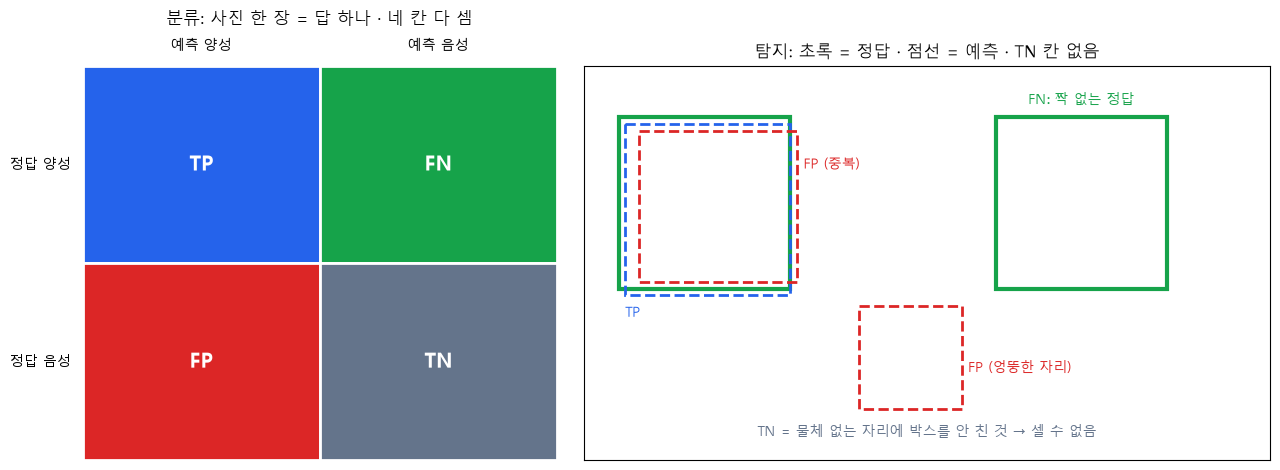

분류 칸: ['TP', 'FN', 'FP', 'TN'] | 탐지 칸: ['TP', 'FP', 'FN']


In [23]:
# ---------- 2-1 ----------
# 왜 · 분류와 탐지의 TP · FP · FN을 나란히 비교하기 위해
fig, (axl, axr) = plt.subplots(1, 2, figsize=(13, 4.8),  # 왼쪽 분류 · 오른쪽 탐지
                               gridspec_kw={"width_ratios": [1, 1.5]})

# 왼쪽: 분류의 혼동 행렬 네 칸
# 왜 · 분류에는 TN이 있다는 것을 먼저 보이기 위해
axl.set_xlim(0, 2)                                                            # 두 열
axl.set_ylim(2, 0)                                                            # 두 행 (위가 0)
axl.axis("off")                                                               # 눈금 숨김
cells = {(0, 0): ("TP", PRED_COLOR), (1, 0): ("FN", GT_COLOR),                # (열, 행): (이름, 색)
         (0, 1): ("FP", FP_COLOR), (1, 1): ("TN", "#64748b")}
for (c, r), (t, col) in cells.items():                                        # 칸마다
    axl.add_patch(patches.Rectangle((c, r), 1, 1, fc=col, ec="white", lw=2))  # 색 칸
    axl.text(c + 0.5, r + 0.5, t, ha="center", va="center", fontsize=15,      # 칸 이름
             fontweight="bold", color=INK)
axl.text(0.5, -0.08, "예측 양성", ha="center", fontsize=10)                   # 열 이름
axl.text(1.5, -0.08, "예측 음성", ha="center", fontsize=10)                   # 열 이름
axl.text(-0.05, 0.5, "정답 양성", ha="right", va="center", fontsize=10)       # 행 이름
axl.text(-0.05, 1.5, "정답 음성", ha="right", va="center", fontsize=10)       # 행 이름
axl.set_title("분류: 사진 한 장 = 답 하나 · 네 칸 다 셈", fontsize=12, pad=30)  # 제목

# 오른쪽: 탐지 (정답 2개 · 예측 3개)
# 왜 · 탐지에는 TN이 없어 정확도를 쓸 수 없다는 것을 보이기 위해
axr.set_xlim(0, 200)                                                                # 가로 범위
axr.set_ylim(115, 0)                                                                # 세로 (위가 0)
axr.set_aspect("equal")                                                             # 비율 유지
axr.set_xticks([])                                                                  # 눈금 숨김
axr.set_yticks([])                                                                  # 눈금 숨김
for g in ([10, 15, 60, 65], [120, 15, 170, 65]):                                    # 정답 2개
    axr.add_patch(patches.Rectangle(g[:2], 50, 50, fill=False, ec=GT_COLOR, lw=3))  # 초록
axr.text(145, 12, "FN: 짝 없는 정답", color=GT_COLOR, fontsize=10, ha="center", va="bottom")  # 놓침
for b, col in [([12, 17, 60, 67], PRED_COLOR), ([16, 19, 62, 63], FP_COLOR),        # TP · 중복 FP
               ([80, 70, 110, 100], FP_COLOR)]:                                     # 엉뚱한 자리 FP
    axr.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False,    # 예측 = 점선
                                    ec=col, lw=2, ls="--"))
axr.text(12, 70, "TP", color=PRED_COLOR, fontsize=10, va="top")                     # 맞힘
axr.text(64, 30, "FP (중복)", color=FP_COLOR, fontsize=10)  # 같은 정답을 또 침
axr.text(112, 88, "FP (엉뚱한 자리)", color=FP_COLOR, fontsize=10, va="center")     # 물체 없는 곳
axr.text(100, 108, "TN = 물체 없는 자리에 박스를 안 친 것 → 셀 수 없음", ha="center",  # TN 없음
         fontsize=10, color="#64748b")
axr.set_title("탐지: 초록 = 정답 · 점선 = 예측 · TN 칸 없음", fontsize=12)          # 제목
plt.tight_layout()                                                                  # 여백 정리
plt.show()                                                                          # 그림 출력
print("분류 칸:", [t for t, _ in cells.values()], "| 탐지 칸: ['TP', 'FP', 'FN']")  # 칸 비교


# ---------- 2-2 ----------
# 왜 · 손으로 검산할 수 있는 작은 정답을 만들기 위해
GT = {"사진1": [[10, 10, 60, 60], [100, 20, 150, 70]],  # 사진별 정답 박스
      "사진2": [[30, 30, 90, 90]]}
N_GT = sum(len(v) for v in GT.values())                 # 정답 수 3
GT_NAME = {("사진1", 0): "사진1 왼쪽", ("사진1", 1): "사진1 오른쪽", ("사진2", 0): "사진2"}  # 이름

# 모델 A의 예측: (컨피던스, 사진, 박스)
# 왜 · TP · FP가 섞인 예측으로 짝짓기 규칙을 연습하기 위해
PRED_A = [(0.95, "사진1", [12, 12, 60, 62]),    # 사진1 왼쪽 근처
          (0.90, "사진2", [32, 28, 92, 88]),    # 사진2 근처
          (0.80, "사진1", [14, 10, 62, 58]),    # 사진1 왼쪽 근처 (두 번째)
          (0.70, "사진1", [180, 20, 230, 70]),  # 엉뚱한 자리
          (0.60, "사진1", [108, 26, 160, 80]),  # 사진1 오른쪽 근처 (덜 맞음)
          (0.40, "사진2", [60, 60, 120, 120])]  # 사진2 반쯤

**실행 흐름**

1. 2-2 사진별 그림
2. 2-3 짝짓기 judge

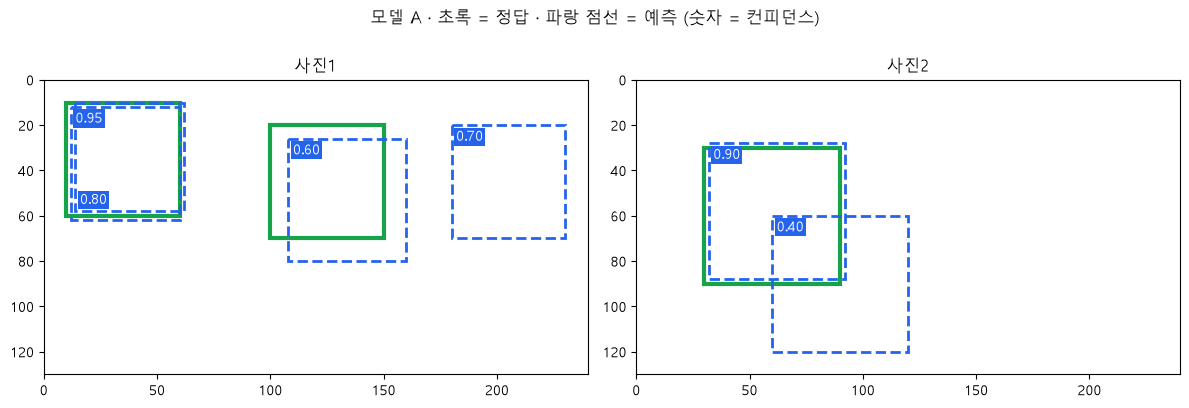

정답 박스 3 개 · 예측 박스 6 개


In [24]:
# 왜 · 정답과 예측을 사진별로 같은 형식으로 그리기 위해
def draw_boxes(ax, img, preds):                                   # 한 사진에 정답 · 예측 그리기
    for g in GT[img]:                                             # 정답
        ax.add_patch(patches.Rectangle(g[:2], g[2] - g[0], g[3] - g[1], fill=False,  # 초록 실선
                                       ec=GT_COLOR, lw=3))
    placed = []                                                   # 이미 놓은 이름표 자리
    for c, im, b in preds:                                        # 예측
        if im != img:                                             # 다른 사진이면
            continue                                              # 건너뜀
        ax.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False,  # 파랑 점선
                                       ec=PRED_COLOR, lw=2, ls="--"))
        x, y, va = b[0] + 2, b[1] + 2, "top"                      # 이름표는 왼쪽 위
        if any(abs(x - px) < 25 and abs(y - py) < 15 for px, py in placed):  # 겹치면
            y, va = b[3] - 2, "bottom"                            # 아래쪽으로
        placed.append((x, y))                                     # 자리 기록
        ax.text(x, y, f"{c:.2f}", color=INK, fontsize=10, va=va,  # 컨피던스
                bbox=dict(fc=PRED_COLOR, ec="none", pad=1.5))
    ax.set_xlim(0, 240)                                           # 가로 범위
    ax.set_ylim(130, 0)                                           # 세로 (위가 0)
    ax.set_aspect("equal")                                        # 비율 유지
    ax.set_title(img, fontsize=12)                                # 사진 이름


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))              # 사진 2장
for ax, img in zip(axes, GT):                                  # 사진마다
    draw_boxes(ax, img, PRED_A)                                # 정답 · 예측
fig.suptitle("모델 A · 초록 = 정답 · 파랑 점선 = 예측 (숫자 = 컨피던스)", fontsize=12)  # 제목
plt.tight_layout()                                             # 여백 정리
plt.show()                                                     # 그림 출력
print("정답 박스", N_GT, "개 · 예측 박스", len(PRED_A), "개")  # 개수 확인


# ---------- 2-3 ----------
# 왜 · 정답 하나에 예측 하나만 짝지어 중복 정답을 막기 위해
def judge(preds, iou_thr=0.5):                                  # 예측 목록 → (판정 목록, FN 수)
    """컨피던스 높은 순 · 아직 짝 없는 정답 중 IoU가 가장 큰 것과 짝"""  # 함수 설명
    partner = {img: [None] * len(b) for img, b in GT.items()}   # 정답마다 짝의 컨피던스
    rows = []  # (컨피던스, TP 여부, IoU, 설명, 사진, 박스)
    for conf, img, box in sorted(preds, key=lambda p: -p[0]):   # 컨피던스 높은 순
        # 빈 정답
        free = [(iou(box, g), j) for j, g in enumerate(GT[img]) if partner[img][j] is None]
        best, j = max(free) if free else (0.0, -1)              # 가장 많이 겹친 빈 정답
        taken, jt = max(((iou(box, g), k) for k, g in enumerate(GT[img])  # 이미 짝 있는 정답 중
                         if partner[img][k] is not None), default=(0.0, -1))
        if j >= 0 and best >= iou_thr:                          # 기준 이상 → TP
            partner[img][j] = conf                              # 그 정답은 짝이 생김
            note = f"{GT_NAME[(img, j)]} 정답과 IoU {best:.2f} ≥ {iou_thr} → 짝"  # 설명
            rows.append((conf, True, best, note, img, box))     # TP 기록
            continue                                            # 다음 예측
        if taken >= iou_thr:                                    # 이미 짝 있는 정답과 많이 겹침
            note = (f"가장 많이 겹친 {GT_NAME[(img, jt)]} 정답(IoU {taken:.2f})은"  # 중복
                    f" 이미 {partner[img][jt]:.2f} 박스의 짝 → 중복")
        elif best > 0:                                          # 빈 정답과 조금 겹침
            note = f"남은 {GT_NAME[(img, j)]} 정답과 IoU {best:.2f} < {iou_thr}"  # 덜 겹침
        elif taken > 0:                                         # 짝 있는 정답과만 조금 겹침
            note = (f"겹치는 {GT_NAME[(img, jt)]} 정답(IoU {taken:.2f})은"  # 남은 정답과 0
                    f" 이미 {partner[img][jt]:.2f} 박스의 짝 · 남은 정답과는 안 겹침")
        else:                                                   # 아무것도 안 겹침
            note = "겹치는 정답 없음"                           # 엉뚱한 자리
        rows.append((conf, False, best, note, img, box))        # FP 기록
    fn = sum(c is None for cs in partner.values() for c in cs)  # 끝까지 짝 없는 정답
    return rows, fn                                             # 판정 · FN

**실행 흐름**

1. 2-3 판정 표
2. 2-4 판정 그림

1. 컨피던스 0.95 · 사진1 → TP · 사진1 왼쪽 정답과 IoU 0.89 ≥ 0.5 → 짝
2. 컨피던스 0.90 · 사진2 → TP · 사진2 정답과 IoU 0.88 ≥ 0.5 → 짝
3. 컨피던스 0.80 · 사진1 → FP · 가장 많이 겹친 사진1 왼쪽 정답(IoU 0.85)은 이미 0.95 박스의 짝 → 중복
4. 컨피던스 0.70 · 사진1 → FP · 겹치는 정답 없음
5. 컨피던스 0.60 · 사진1 → TP · 사진1 오른쪽 정답과 IoU 0.53 ≥ 0.5 → 짝
6. 컨피던스 0.40 · 사진2 → FP · 겹치는 사진2 정답(IoU 0.14)은 이미 0.90 박스의 짝 · 남은 정답과는 안 겹침
예측 6개를 전부 냈을 때 FN (놓친 정답): 0


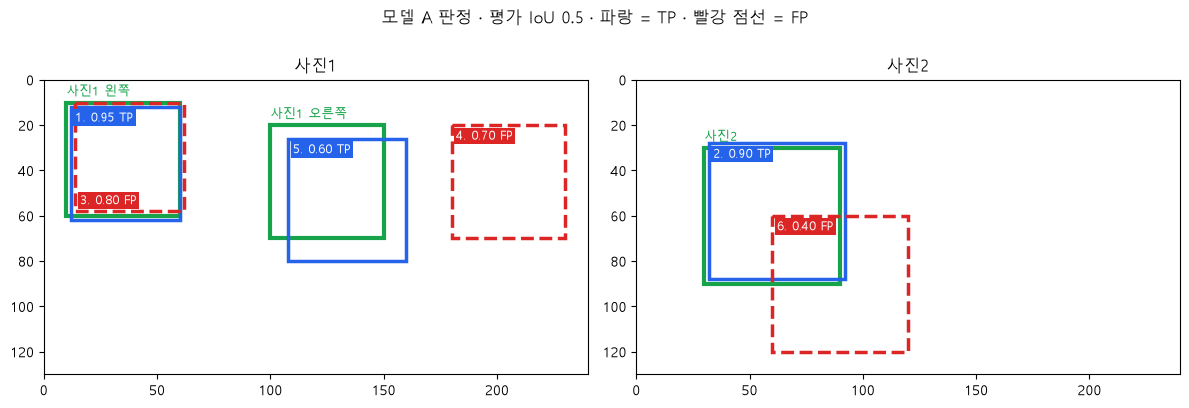

TP 3 · FP 3 · FN 0


In [25]:
# 왜 · 예측마다 왜 TP · FP가 되었는지 한 줄씩 확인하기 위해
rows_A, fn_A = judge(PRED_A, 0.5)                              # 평가 IoU 임계값 0.5
for k, (conf, ok, v, note, img, box) in enumerate(rows_A, 1):  # 꺼낸 순서대로
    print(f"{k}. 컨피던스 {conf:.2f} · {img} → {'TP' if ok else 'FP'} · {note}")  # 판정 한 줄
print("예측 6개를 전부 냈을 때 FN (놓친 정답):", fn_A)         # 놓친 수


# ---------- 2-4 ----------
# 왜 · 판정 결과를 번호 · 색으로 그림에 표시하기 위해
def show_judged(rows, title, axes=None):                             # 판정 결과로 색칠
    """TP = 파랑 실선 · FP = 빨강 점선 · 짝 못 찾은 정답 = FN · 번호 = 꺼낸 순서"""  # 함수 설명
    own = axes is None                                               # 그림을 직접 만들지
    if own:                                                          # 칸을 안 받았으면
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))            # 새 그림
    matched = {(img, max(range(len(GT[img])), key=lambda j: iou(box, GT[img][j])))  # 짝 생긴 정답
               for conf, ok, v, note, img, box in rows if ok}
    for ax, img in zip(axes, GT):                                    # 사진마다
        for j, g in enumerate(GT[img]):                              # 정답마다
            ax.add_patch(patches.Rectangle(g[:2], g[2] - g[0], g[3] - g[1], fill=False,  # 초록
                                           ec=GT_COLOR, lw=3))
            # 이름
            ax.text(g[0], g[1] - 2, GT_NAME[(img, j)], color=GT_COLOR, fontsize=9, va="bottom")
            if (img, j) not in matched:                              # 짝이 없으면
                # 놓침
                ax.text(g[0], g[3] + 2, "FN", color=GT_COLOR, fontsize=10, fontweight="bold",
                        va="top")
        placed = []                                                  # 이름표 자리
        for k, (conf, ok, v, note, im, b) in enumerate(rows, 1):     # 판정마다
            if im != img:                                            # 다른 사진
                continue                                             # 건너뜀
            col, ls = (PRED_COLOR, "-") if ok else (FP_COLOR, "--")  # TP · FP 색
            ax.add_patch(patches.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False,  # 예측 박스
                                           ec=col, lw=2.5, ls=ls))
            x, y, va = b[0] + 2, b[1] + 2, "top"                     # 이름표 자리
            if any(abs(x - px) < 25 and abs(y - py) < 15 for px, py in placed):  # 겹치면
                y, va = b[3] - 2, "bottom"                           # 아래쪽
            placed.append((x, y))                                    # 기록
            # 번호 · 판정
            ax.text(x, y, f"{k}. {conf:.2f} {'TP' if ok else 'FP'}", color=INK, fontsize=9,
                    va=va, bbox=dict(fc=col, ec="none", pad=1.5))
        ax.set_xlim(0, 240)                                          # 가로 범위
        ax.set_ylim(130, 0)                                          # 세로 (위가 0)
        ax.set_aspect("equal")                                       # 비율 유지
        ax.set_title(img, fontsize=12)                               # 사진 이름
    if own:                                                          # 직접 만든 그림이면
        fig.suptitle(title, fontsize=12)                             # 제목
        plt.tight_layout()                                           # 여백 정리
        plt.show()                                                   # 그림 출력


# 왜 · 숫자로 본 판정을 그림으로 확인하기 위해
show_judged(rows_A, "모델 A 판정 · 평가 IoU 0.5 · 파랑 = TP · 빨강 점선 = FP")  # 판정 그림
print("TP", sum(r[1] for r in rows_A), "· FP", sum(not r[1] for r in rows_A), "· FN", fn_A)  # 개수

**실행 흐름**

1. 3-1 정밀도 · 재현율 · F1 · 분모 그림

컨피던스 0.75 이상: 낸 박스 3개 · TP 2 · FP 1 · FN 1
정밀도 2/3 = 0.667 · 재현율 2/3 = 0.667 · F1 0.667


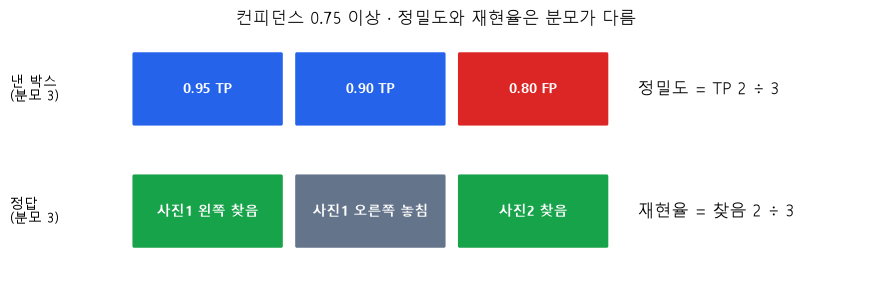

In [26]:
# ---------- 3-1 ----------
# 왜 · 임계값 하나에서의 정밀도 · 재현율 · F1을 한 함수로 구하기 위해
def prf(rows, conf_thr):                                      # 컨피던스 임계값 이상만 냈을 때
    """TP · FP · FN · 정밀도 · 재현율 · F1"""                 # 함수 설명
    kept = [ok for conf, ok, *_ in rows if conf >= conf_thr]  # 낸 박스의 판정
    tp = sum(kept)                                            # 맞힌 박스
    fp = len(kept) - tp                                       # 틀린 박스
    fn = N_GT - tp                                            # 놓친 정답
    p = tp / (tp + fp) if kept else 0.0                       # 정밀도 = TP ÷ 낸 박스
    r = tp / N_GT                                             # 재현율 = TP ÷ 정답 수
    f1 = 2 * p * r / (p + r) if p + r else 0.0                # 조화 평균
    return tp, fp, fn, p, r, f1                               # 여섯 값


# 왜 · 컨피던스 0.75에서의 지표를 손계산과 맞춰 보기 위해
tp, fp, fn, p, r, f1 = prf(rows_A, 0.75)                                         # 0.75 이상만
print(f"컨피던스 0.75 이상: 낸 박스 {tp + fp}개 · TP {tp} · FP {fp} · FN {fn}")  # 개수
print(f"정밀도 {tp}/{tp + fp} = {p:.3f} · 재현율 {tp}/{N_GT} = {r:.3f} · F1 {f1:.3f}")  # 비율

# 그림: 정밀도와 재현율은 분모가 다름
# 왜 · 두 지표의 분모 차이를 그림으로 보이기 위해
kept = [row for row in rows_A if row[0] >= 0.75]                              # 낸 박스 3개
found = {(img, max(range(len(GT[img])), key=lambda j: iou(box, GT[img][j])))  # 찾은 정답
         for conf, ok, v, note, img, box in kept if ok}
fig, ax = plt.subplots(figsize=(11, 3.4))                                     # 가로로 긴 그림
ax.set_xlim(0, 11)                                                            # 가로 범위
ax.set_ylim(3.0, 0)                                                           # 세로 (위가 0)
ax.axis("off")                                                                # 눈금 숨김


# 왜 · 판정 칩을 같은 모양으로 그리기 위해
def chip(x, y, text, col):                                                   # 둥근 이름표 하나
    ax.add_patch(patches.FancyBboxPatch((x, y), 1.9, 0.8, boxstyle="round,pad=0.02",  # 상자
                                        fc=col, ec="none"))
    ax.text(x + 0.95, y + 0.4, text, ha="center", va="center", fontsize=10,  # 글자
            color=INK, fontweight="bold")


ax.text(0, 0.65, f"낸 박스\n(분모 {len(kept)})", fontsize=10, va="center")       # 정밀도의 분모
for k, (conf, ok, *_) in enumerate(kept):                                        # 낸 박스마다
    # 판정
    chip(1.6 + k * 2.1, 0.25, f"{conf:.2f} {'TP' if ok else 'FP'}", PRED_COLOR if ok else FP_COLOR)
ax.text(8.1, 0.65, f"정밀도 = TP {sum(r_[1] for r_ in kept)} ÷ {len(kept)}", fontsize=12,  # 식
        va="center")
ax.text(0, 2.05, f"정답\n(분모 {N_GT})", fontsize=10, va="center")               # 재현율의 분모
for k, key in enumerate(GT_NAME):                                                # 정답마다
    chip(1.6 + k * 2.1, 1.65, f"{GT_NAME[key]} {'찾음' if key in found else '놓침'}",  # 찾았나
         GT_COLOR if key in found else "#64748b")
ax.text(8.1, 2.05, f"재현율 = 찾음 {len(found)} ÷ {N_GT}", fontsize=12, va="center")  # 식
ax.set_title("컨피던스 0.75 이상 · 정밀도와 재현율은 분모가 다름", fontsize=12)  # 제목
plt.show()                                                                       # 그림 출력

**실행 흐름**

1. 3-2 임계값 바꾸기
2. 3-3 모델 B · F1 곡선

컨피던스 임계값 | 낸 박스 | TP | FP | FN | 정밀도 | 재현율 | F1    | 새로 든 박스
           0.9 |      2 |  2 |  0 |  1 |  1.000 |  0.667 | 0.800 | 0.95 TP · 0.90 TP
           0.7 |      4 |  2 |  2 |  1 |  0.500 |  0.667 | 0.571 | 0.80 FP · 0.70 FP
           0.5 |      5 |  3 |  2 |  0 |  0.600 |  1.000 | 0.750 | 0.60 TP


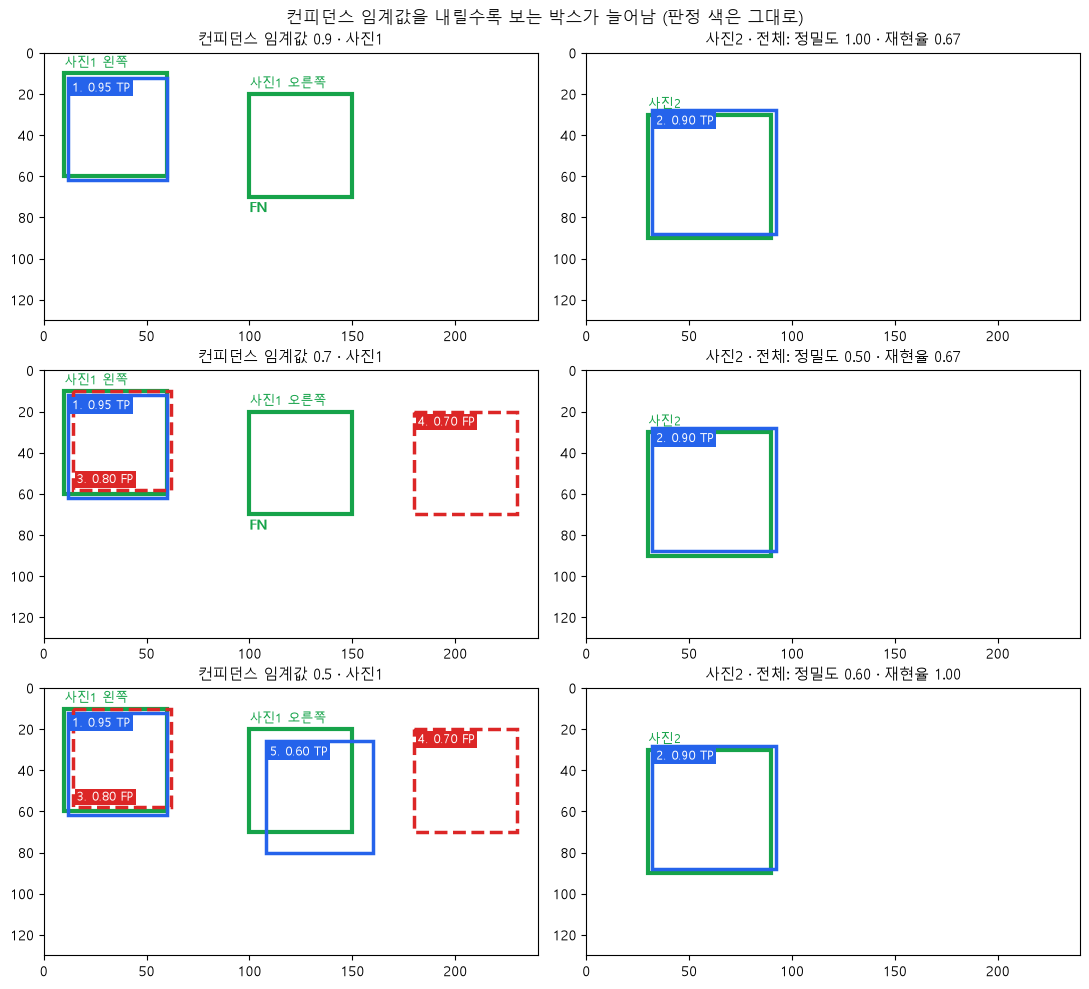

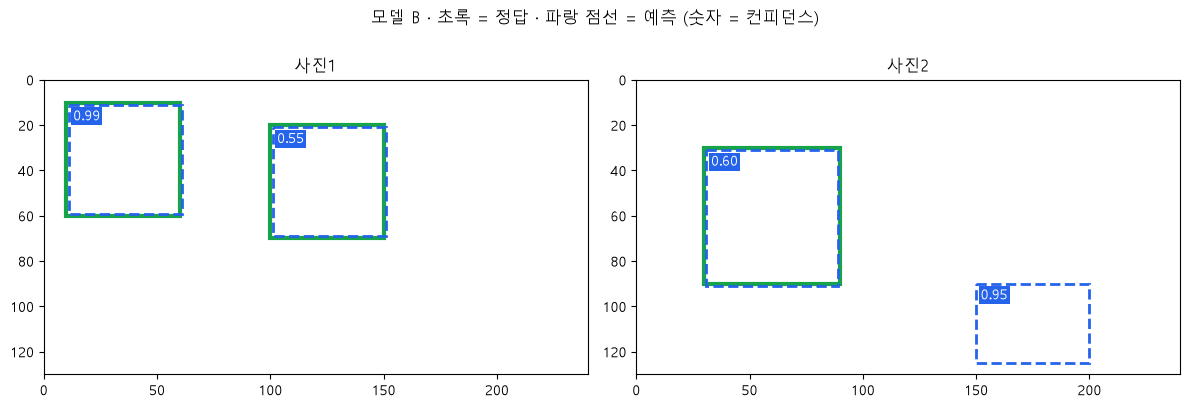

컨피던스 임계값 | 모델 A 정밀도 · 재현율 · F1 | 모델 B 정밀도 · 재현율 · F1
           0.9 | 1.000 · 0.667 · 0.800        | 0.500 · 0.333 · 0.400
           0.5 | 0.600 · 1.000 · 0.750        | 0.750 · 1.000 · 0.857


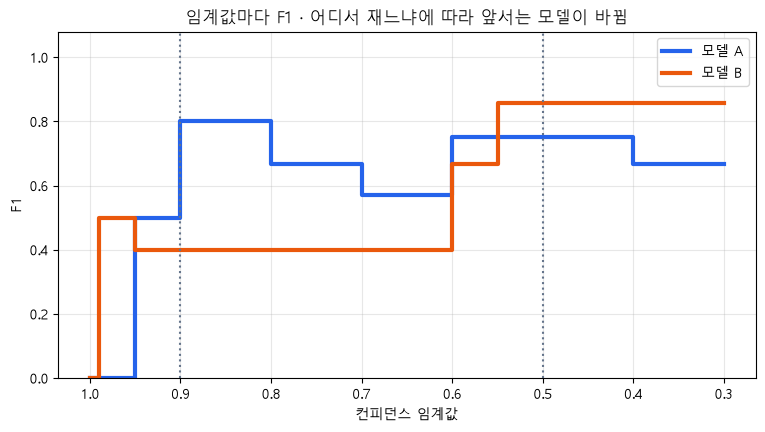

In [27]:
# ---------- 3-2 ----------
# 왜 · 임계값마다 지표가 어떻게 바뀌는지 한 표로 보기 위해
head = ("컨피던스 임계값 | 낸 박스 | TP | FP | FN | 정밀도 | 재현율 | F1    |"  # 표 머리
        " 새로 든 박스")
print(head)                                                                     # 머리 출력
prev = 1.01  # 이전 임계값 (처음은 1보다 크게)
for t in (0.9, 0.7, 0.5):                                                       # 임계값을 내리며
    tp, fp, fn, p, r, f1 = prf(rows_A, t)                                       # 그 임계값의 성적
    new = " · ".join(f"{c:.2f} {'TP' if ok else 'FP'}" for c, ok, *_ in rows_A  # 새로 든 박스
                     if t <= c < prev)
    print(f"{t:14.1f} | {tp + fp:6d} | {tp:2d} | {fp:2d} | {fn:2d} | {p:6.3f} | {r:6.3f} |"  # 한 줄
          f" {f1:.3f} | {new}")
    prev = t                                                                    # 다음 구간 시작

# 왜 · 임계값 세 개에서 남는 박스를 그림으로 비교하기 위해
fig, axes = plt.subplots(3, 2, figsize=(11, 10))                         # 임계값 3개 × 사진 2장
for row_axes, t in zip(axes, (0.9, 0.7, 0.5)):                           # 줄마다 임계값 하나
    show_judged([r_ for r_ in rows_A if r_[0] >= t], "", axes=row_axes)  # 그 임계값까지만
    tp, fp, fn, p, r, f1 = prf(rows_A, t)                                # 성적
    row_axes[0].set_title(f"컨피던스 임계값 {t} · 사진1", fontsize=11)   # 왼쪽 제목
    # 오른쪽 제목
    row_axes[1].set_title(f"사진2 · 전체: 정밀도 {p:.2f} · 재현율 {r:.2f}", fontsize=11)
# 제목
fig.suptitle("컨피던스 임계값을 내릴수록 보는 박스가 늘어남 (판정 색은 그대로)", fontsize=12)
plt.tight_layout()                                                       # 여백 정리
plt.show()                                                               # 그림 출력


# ---------- 3-3 ----------
# 왜 · 한 임계값의 지표만으로는 두 모델을 공정하게 비교하기 어렵다는 것을 보이기 위해
PRED_B = [(0.99, "사진1", [11, 11, 61, 59]),       # 사진1 왼쪽
          (0.95, "사진2", [150, 90, 200, 125]),    # 엉뚱한 자리
          (0.60, "사진2", [31, 31, 89, 91]),       # 사진2
          (0.55, "사진1", [101, 21, 151, 69])]     # 사진1 오른쪽
rows_B, _ = judge(PRED_B, 0.5)                     # 같은 규칙으로 판정
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))  # 사진 2장
for ax, img in zip(axes, GT):                      # 사진마다
    draw_boxes(ax, img, PRED_B)                    # 정답 · 예측
fig.suptitle("모델 B · 초록 = 정답 · 파랑 점선 = 예측 (숫자 = 컨피던스)", fontsize=12)  # 제목
plt.tight_layout()                                 # 여백 정리
plt.show()                                         # 그림 출력

# 왜 · 임계값에 따라 나은 모델이 뒤바뀌는 것을 보기 위해
print("컨피던스 임계값 | 모델 A 정밀도 · 재현율 · F1 | 모델 B 정밀도 · 재현율 · F1")  # 표 머리
for t in (0.9, 0.5):                                                                  # 두 기준
    a, b = prf(rows_A, t), prf(rows_B, t)                                             # 두 모델 성적
    print(f"{t:14.1f} | {a[3]:.3f} · {a[4]:.3f} · {a[5]:.3f}        |"                # 한 줄
          f" {b[3]:.3f} · {b[4]:.3f} · {b[5]:.3f}")

# 왜 · 모든 임계값의 F1을 곡선으로 비교하기 위해
ts = np.round(np.arange(0.30, 1.001, 0.01), 2)      # 임계값 0.30 ~ 1.00
fig, ax = plt.subplots(figsize=(9, 4.5))            # F1 곡선
for name, rows, col in [("모델 A", rows_A, PRED_COLOR), ("모델 B", rows_B, ENV_COLOR)]:  # 두 모델
    ax.plot(ts, [prf(rows, t)[5] for t in ts], lw=3, color=col, label=name,  # 계단 모양
            drawstyle="steps-pre")
for t in (0.9, 0.5):                                # 비교한 두 자리
    ax.axvline(t, color="#64748b", ls=":", lw=1.5)  # 세로 점선
ax.set_xlabel("컨피던스 임계값", fontsize=10)       # x축
ax.set_ylabel("F1", fontsize=10)                    # y축
ax.set_ylim(0, 1.08)                                # 범위
ax.invert_xaxis()                                   # 왼쪽 = 높은 임계값 (적게 냄)
ax.set_title("임계값마다 F1 · 어디서 재느냐에 따라 앞서는 모델이 바뀜", fontsize=12)  # 제목
ax.grid(alpha=0.3)                                  # 옅은 격자
ax.legend(fontsize=10)                              # 범례
plt.show()                                          # 그림 출력

**실행 흐름**

1. 4-1 PR 점
2. 4-2 보간 · 포락선 함수

컨피던스 임계값 | 새로 든 박스 | 누적 TP | 누적 FP | 재현율 | 정밀도
          0.95 | TP         |       1 |       0 |  0.333 | 1.000
          0.90 | TP         |       2 |       0 |  0.667 | 1.000
          0.80 | FP         |       2 |       1 |  0.667 | 0.667
          0.70 | FP         |       2 |       2 |  0.667 | 0.500
          0.60 | TP         |       3 |       2 |  1.000 | 0.600
          0.40 | FP         |       3 |       3 |  1.000 | 0.500


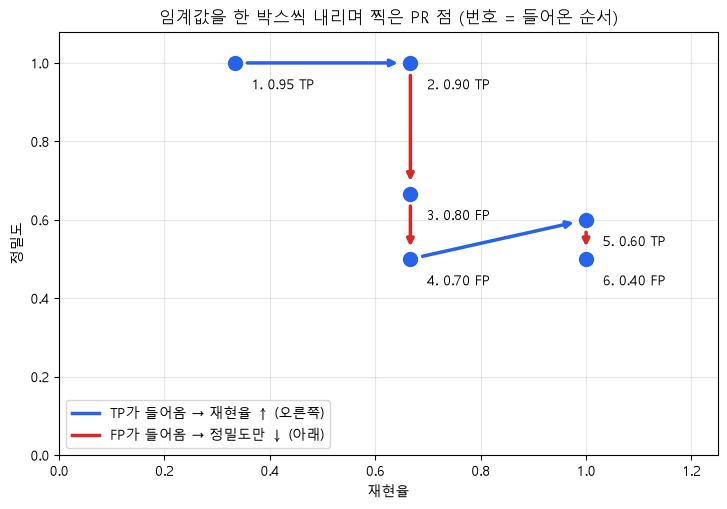

In [28]:
# ---------- 4-1 ----------
# 왜 · 모든 임계값을 한 번에 보는 PR 점을 만들기 위해
def pr_points(rows, n_gt=None):                                   # 판정 목록 → (재현율, 정밀도) 점
    """컨피던스 높은 순으로 한 박스씩 더하며 (재현율, 정밀도)"""  # 함수 설명
    n_gt = n_gt or N_GT                                           # 정답 수 (기본 3)
    tp = np.cumsum([ok for _, ok, *_ in rows])                    # 누적 TP
    k = np.arange(1, len(rows) + 1)                               # 낸 박스 수 1, 2, ...
    return tp / n_gt, tp / k                                      # 재현율 · 정밀도


# 왜 · 박스를 하나씩 더할 때 재현율 · 정밀도가 어떻게 바뀌는지 표로 보기 위해
rec_A, prec_A = pr_points(rows_A)                                              # 모델 A의 PR 점 6개
print("컨피던스 임계값 | 새로 든 박스 | 누적 TP | 누적 FP | 재현율 | 정밀도")  # 표 머리
for (conf, ok, *_), r, p, k in zip(rows_A, rec_A, prec_A, range(1, 7)):        # 점마다
    tp = round(r * N_GT)                                                       # 누적 TP
    # 한 줄
    print(f"{conf:14.2f} | {'TP' if ok else 'FP':10s} | {tp:7d} | {k - tp:7d} | {r:6.3f} | {p:.3f}")

# 왜 · PR 점을 그림으로 확인하기 위해
fig, ax = plt.subplots(figsize=(8.5, 5.5))                                # PR 점 그림
ax.plot(rec_A, prec_A, "o", color=PRED_COLOR, ms=10, zorder=3)            # 점 6개
for k, ((conf, ok, *_), r, p) in enumerate(zip(rows_A, rec_A, prec_A)):   # 점마다
    ax.annotate(f"{k + 1}. {conf:.2f} {'TP' if ok else 'FP'}", (r, p), xytext=(12, -16),  # 이름표
                textcoords="offset points", va="center", fontsize=10)
    if k > 0:                                                             # 두 번째 점부터
        ax.annotate("", xy=(r, p), xytext=(rec_A[k - 1], prec_A[k - 1]),  # 이전 점에서 화살표
                    arrowprops=dict(arrowstyle="-|>", color=PRED_COLOR if ok else FP_COLOR,
                                    lw=2.5, shrinkA=9, shrinkB=9))
ax.plot([], [], color=PRED_COLOR, lw=2.5, label="TP가 들어옴 → 재현율 ↑ (오른쪽)")  # 범례용
ax.plot([], [], color=FP_COLOR, lw=2.5, label="FP가 들어옴 → 정밀도만 ↓ (아래)")  # 범례용
ax.set_xlim(0, 1.25)                                                      # 이름표 자리까지
ax.set_ylim(0, 1.08)                                                      # 범위
ax.set_xlabel("재현율", fontsize=10)                                      # x축
ax.set_ylabel("정밀도", fontsize=10)                                      # y축
ax.set_title("임계값을 한 박스씩 내리며 찍은 PR 점 (번호 = 들어온 순서)", fontsize=12)  # 제목
ax.grid(alpha=0.3)                                                        # 격자
ax.legend(loc="lower left", fontsize=10)                                  # 범례
plt.show()                                                                # 그림 출력


# ---------- 4-2 ----------
# 왜 · AP 계산이 쓰는 보간 규칙을 직접 구현하기 위해
def envelope(prec):                                    # 포락선 (보간 정밀도)
    """오른쪽(재현율이 같거나 큰 쪽)에서 본 최댓값"""  # 함수 설명
    return np.maximum.accumulate(prec[::-1])[::-1]     # 뒤집기 → 누적 최대 → 뒤집기


# 왜 · 재현율 r에서 읽을 보간 정밀도를 구하기 위해
def interp_precision(rec, prec, r):                    # 정의 그대로
    """재현율이 r 이상인 점들 중 가장 높은 정밀도 (없으면 0)"""  # 함수 설명
    ok = rec >= r - 1e-12                              # 재현율 r 이상인 점 (반올림 오차 허용)
    return float(prec[ok].max()) if ok.any() else 0.0  # 그중 최고


# 왜 · 포락선을 계단 그림으로 그릴 좌표를 만들기 위해
def env_xy(rec, prec):                                            # 포락선 계단의 꼭짓점
    """재현율 구간 (이전, lv]의 높이 = interp_precision(lv) · 끝에서 0으로"""  # 함수 설명
    levels = np.unique(rec)                                       # 재현율이 바뀌는 자리
    heights = [interp_precision(rec, prec, lv) for lv in levels]  # 자리마다 높이
    xs, ys = [0.0], [heights[0]]                                  # 왼쪽 끝에서 시작
    for lv, h in zip(levels, heights):                            # 자리마다
        xs += [xs[-1], lv]                                        # 세로 → 가로
        ys += [h, h]                                              # 같은 높이
    return xs + [levels[-1]], ys + [0.0], levels, heights         # 끝에서 0으로 내림

**실행 흐름**

1. 4-2 포락선 그림
2. 4-3 AP = 포락선 아래 넓이

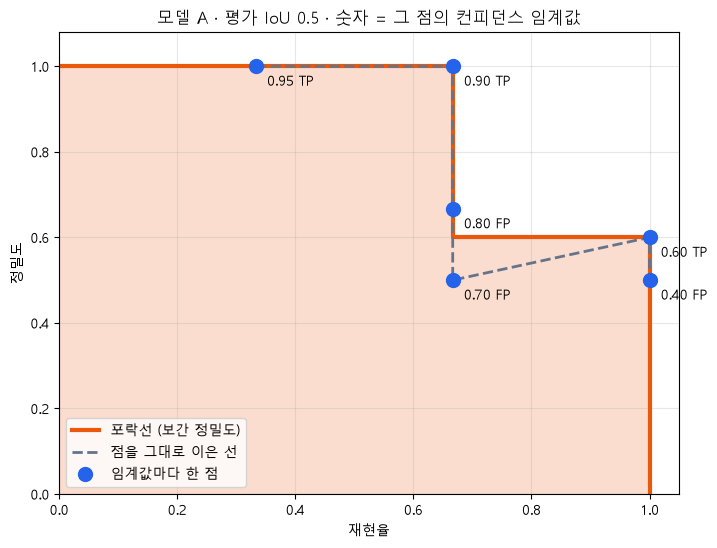

재현율 0.333 이상에서 얻을 수 있는 최고 정밀도 = 1.000
재현율 0.667 이상에서 얻을 수 있는 최고 정밀도 = 1.000
재현율 1.000 이상에서 얻을 수 있는 최고 정밀도 = 0.600
손계산: 재현율 0 → 2/3 구간 높이 1.0 · 2/3 → 1 구간 높이 0.6
        (2/3) × 1.0 + (1/3) × 0.6 = 0.8667
함수   : AP = 0.8667


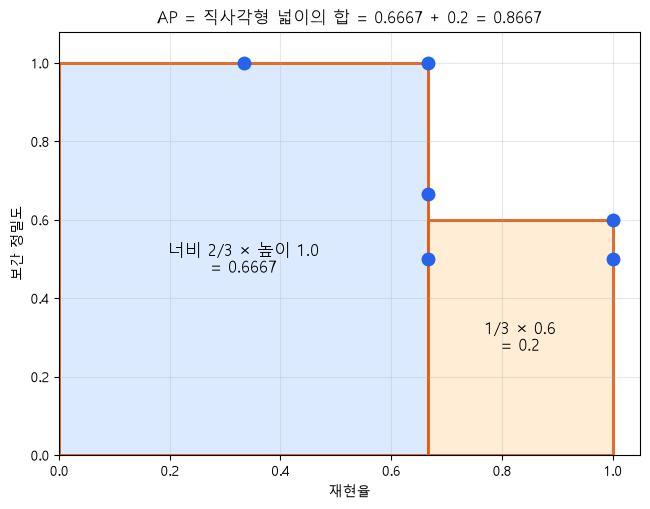

모델 A AP = 0.8667 · 모델 B AP = 0.8333
수업 Day02 그림 (정답 2개 · 예측 3개): 0.8333


In [29]:
# 왜 · PR 점과 포락선을 함께 그려 보간의 뜻을 보이기 위해
xs, ys, levels, heights = env_xy(rec_A, prec_A)                                   # 모델 A의 포락선
fig, ax = plt.subplots(figsize=(8, 6))                                            # 그림
ax.fill_between(xs, ys, color=ENV_COLOR, alpha=0.2)                               # 넓이 = AP
ax.plot(xs, ys, color=ENV_COLOR, lw=3, label="포락선 (보간 정밀도)")              # 계단
ax.plot(rec_A, prec_A, "--", color="#64748b", lw=2, label="점을 그대로 이은 선")  # 지그재그
ax.plot(rec_A, prec_A, "o", color=PRED_COLOR, ms=10, label="임계값마다 한 점")    # PR 점
for (conf, ok, *_), r, p in zip(rows_A, rec_A, prec_A):                           # 점마다
    ax.annotate(f"{conf:.2f} {'TP' if ok else 'FP'}", (r, p), xytext=(8, -14),    # 이름표
                textcoords="offset points", fontsize=10)
ax.set_xlim(0, 1.05)                                                              # 범위
ax.set_ylim(0, 1.08)                                                              # 범위
ax.set_xlabel("재현율", fontsize=10)                                              # x축
ax.set_ylabel("정밀도", fontsize=10)                                              # y축
ax.set_title("모델 A · 평가 IoU 0.5 · 숫자 = 그 점의 컨피던스 임계값", fontsize=12)  # 제목
ax.grid(alpha=0.3)                                                                # 격자
ax.legend(loc="lower left", fontsize=10)                                          # 범례
plt.show()                                                                        # 그림 출력
for lv, h in zip(levels, heights):                                                # 계단 높이
    print(f"재현율 {lv:.3f} 이상에서 얻을 수 있는 최고 정밀도 = {h:.3f}")         # 보간 정밀도


# ---------- 4-3 ----------
# 왜 · 곡선 아래 넓이를 손으로 계산할 수 있는 방식으로 구하기 위해
def ap_all_point(rec, prec):                            # 포락선 아래 넓이
    """재현율이 바뀌는 모든 자리에서 직사각형 넓이를 더함 (PASCAL VOC 2010 이후)"""  # 함수 설명
    r = np.concatenate([[0.0], rec, [1.0]])             # 양 끝 재현율 0 · 1 추가
    p = envelope(np.concatenate([[0.0], prec, [0.0]]))  # 양 끝 정밀도 0 · 포락선
    return float(np.sum((r[1:] - r[:-1]) * p[1:]))      # 너비 × 높이의 합


# 왜 · 함수 결과를 직사각형 넓이 손계산과 맞춰 보기 위해
print("손계산: 재현율 0 → 2/3 구간 높이 1.0 · 2/3 → 1 구간 높이 0.6")          # 계단 두 칸
print(f"        (2/3) × 1.0 + (1/3) × 0.6 = {2 / 3 * 1.0 + 1 / 3 * 0.6:.4f}")  # 손계산
print(f"함수   : AP = {ap_all_point(rec_A, prec_A):.4f}")                      # 함수 결과

fig, ax = plt.subplots(figsize=(7.5, 5.5))                                      # 직사각형 그림
ax.add_patch(patches.Rectangle((0, 0), 2 / 3, 1.0, fc="#dbeafe", ec=ENV_COLOR, lw=2))  # 왼쪽 칸
# 오른쪽 칸
ax.add_patch(patches.Rectangle((2 / 3, 0), 1 / 3, 0.6, fc="#ffedd5", ec=ENV_COLOR, lw=2))
ax.text(1 / 3, 0.5, "너비 2/3 × 높이 1.0\n= 0.6667", ha="center", va="center", fontsize=12)  # 넓이
ax.text(5 / 6, 0.3, "1/3 × 0.6\n= 0.2", ha="center", va="center", fontsize=12)  # 넓이
ax.plot(rec_A, prec_A, "o", color=PRED_COLOR, ms=9)                             # PR 점
ax.set_xlim(0, 1.05)                                                            # 범위
ax.set_ylim(0, 1.08)                                                            # 범위
ax.set_xlabel("재현율", fontsize=10)                                            # x축
ax.set_ylabel("보간 정밀도", fontsize=10)                                       # y축
ax.set_title("AP = 직사각형 넓이의 합 = 0.6667 + 0.2 = 0.8667", fontsize=12)    # 제목
ax.grid(alpha=0.3)                                                              # 격자
plt.show()                                                                      # 그림 출력

# 왜 · 두 모델을 AP 하나로 비교하기 위해
rec_B, prec_B = pr_points(rows_B)                         # 모델 B도 같은 방법
print(f"모델 A AP = {ap_all_point(rec_A, prec_A):.4f} ·"  # 두 모델 비교
      f" 모델 B AP = {ap_all_point(rec_B, prec_B):.4f}")
print("수업 Day02 그림 (정답 2개 · 예측 3개):",           # 0.5 × 1.0 + 0.5 × 0.67
      round(ap_all_point(np.array([0.5, 0.5, 1.0]), np.array([1.0, 0.5, 2 / 3])), 4))

**실행 흐름**

1. 5-1 먼저 자른 AP
2. 5-2 11 · 101-point 함수

잘려 나간 박스: 0.70 FP · 0.60 TP · 0.40 FP
0.75 이상만: 재현율 최대 0.667 · AP = 0.6667
전부 사용  : 재현율 최대 1.000 · AP = 0.8667


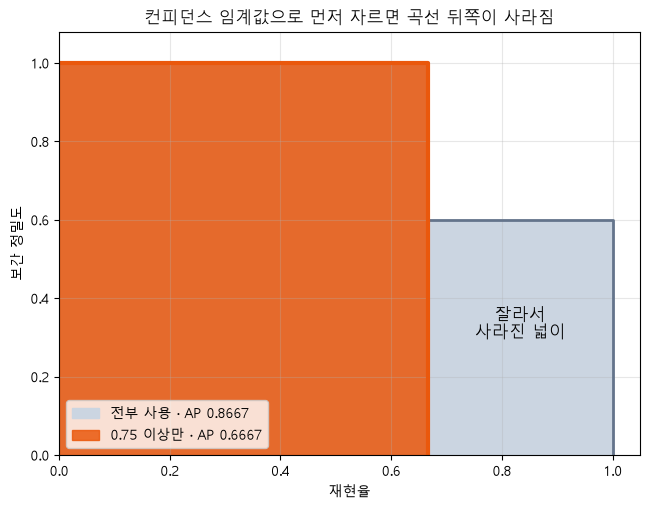

In [30]:
# ---------- 5-1 ----------
# 왜 · AP 전에 임계값으로 자르면 AP가 낮아지는 실수를 보이기 위해
cut = [row for row in rows_A if row[0] >= 0.75]                        # 0.75 이상만 남김
rec_c, prec_c = pr_points(cut)                                         # 남은 박스로 PR 점
print("잘려 나간 박스:", " · ".join(f"{c:.2f} {'TP' if ok else 'FP'}"  # 버린 박스
                              for c, ok, *_ in rows_A if c < 0.75))
# 잘린 AP
print(f"0.75 이상만: 재현율 최대 {rec_c[-1]:.3f} · AP = {ap_all_point(rec_c, prec_c):.4f}")
# 원래 AP
print(f"전부 사용  : 재현율 최대 {rec_A[-1]:.3f} · AP = {ap_all_point(rec_A, prec_A):.4f}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))                                       # 두 넓이 비교
xa, ya, *_ = env_xy(rec_A, prec_A)                                               # 전부 사용한 계단
xc, yc, *_ = env_xy(rec_c, prec_c)                                               # 잘라 낸 계단
ax.fill_between(xa, ya, color="#cbd5e1", label="전부 사용 · AP 0.8667")          # 회색 넓이
ax.fill_between(xc, yc, color=ENV_COLOR, alpha=0.85, label="0.75 이상만 · AP 0.6667")  # 주황 넓이
ax.plot(xa, ya, color="#64748b", lw=2)                                           # 회색 계단
ax.plot(xc, yc, color=ENV_COLOR, lw=3)                                           # 주황 계단
ax.text(5 / 6, 0.3, "잘라서\n사라진 넓이", ha="center", fontsize=12)             # 설명
ax.set_xlim(0, 1.05)                                                             # 범위
ax.set_ylim(0, 1.08)                                                             # 범위
ax.set_xlabel("재현율", fontsize=10)                                             # x축
ax.set_ylabel("보간 정밀도", fontsize=10)                                        # y축
ax.set_title("컨피던스 임계값으로 먼저 자르면 곡선 뒤쪽이 사라짐", fontsize=12)  # 제목
ax.grid(alpha=0.3)                                                               # 격자
ax.legend(fontsize=10, loc="lower left")                                         # 범례
plt.show()                                                                       # 그림 출력


# ---------- 5-2 ----------
# 왜 · 옛 PASCAL VOC 방식 AP를 구하기 위해
def ap_11_point(rec, prec):                                                       # PASCAL VOC 2007
    """재현율 0, 0.1, …, 1.0마다 그 재현율 이상에서의 최고 정밀도를 읽어 평균"""  # 함수 설명
    return float(np.mean([prec[rec >= t].max() if (rec >= t).any() else 0.0       # 11곳 평균
                          for t in np.linspace(0, 1, 11)]))


# 왜 · COCO 방식 AP를 구하기 위해
def ap_101_point(rec, prec):                                         # COCO와 같은 읽는 법
    """재현율 0, 0.01, …, 1.0마다 보간 정밀도를 읽어 평균"""         # 함수 설명
    env = envelope(prec)                                             # 포락선
    idx = np.searchsorted(rec, np.linspace(0, 1, 101), side="left")  # 그 재현율에 처음 닿는 점
    return float(np.mean([env[i] if i < len(env) else 0.0 for i in idx]))  # 못 닿으면 0

**실행 흐름**

1. 5-2 세 방식 비교 그림
2. 5-3 평가 IoU 기준별 AP

모델 A: all-point 0.8667 · 11-point 0.8545 · 101-point 0.8653
모델 B: all-point 0.8333 · 11-point 0.8409 · 101-point 0.8342


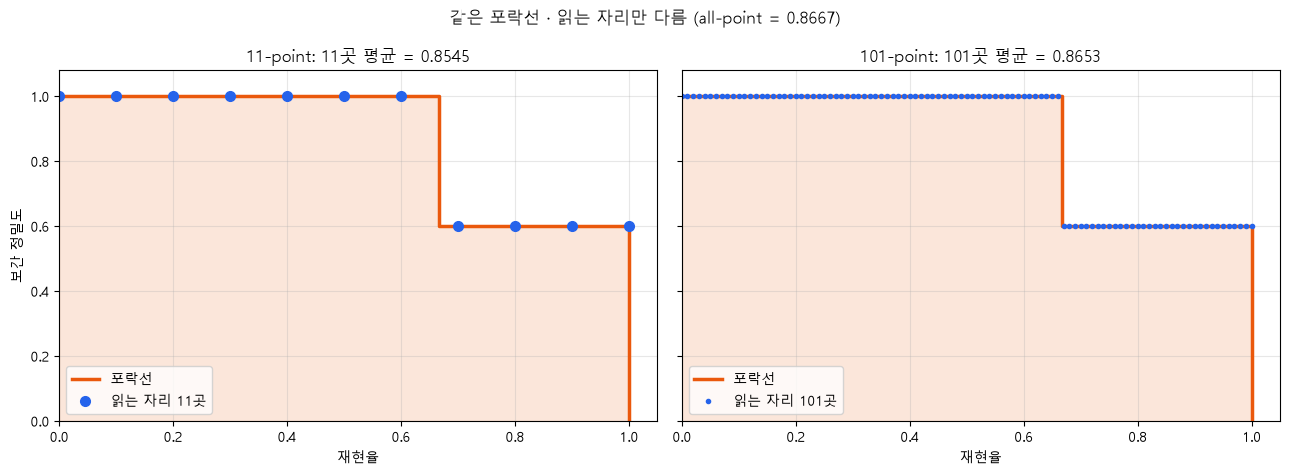

컨피던스 0.60 박스: IoU 0.53 → 0.5에서 TP · 0.75에서 FP
평가 IoU 0.5에서 TP 박스들의 IoU: 0.89 · 0.88 · 0.53
평가 IoU 임계값별 AP: {0.5: 0.867, 0.55: 0.667, 0.6: 0.667, 0.65: 0.667, 0.7: 0.667, 0.75: 0.667, 0.8: 0.667, 0.85: 0.667, 0.9: 0.0, 0.95: 0.0}
AP50 = 0.8667 · AP75 = 0.6667 · IoU 0.50~0.95 평균 AP = 0.5533


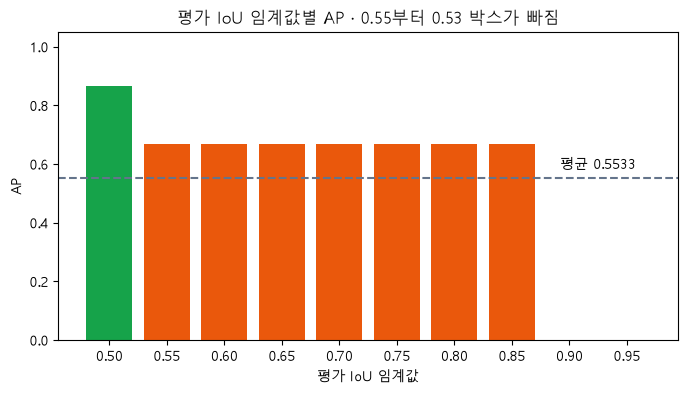

In [31]:
# 왜 · 같은 판정이라도 계산 방식에 따라 AP가 달라지는 것을 보이기 위해
for name, (r, p) in {"모델 A": (rec_A, prec_A), "모델 B": (rec_B, prec_B)}.items():  # 두 모델
    # 세 방식
    print(f"{name}: all-point {ap_all_point(r, p):.4f} · 11-point {ap_11_point(r, p):.4f}"
          f" · 101-point {ap_101_point(r, p):.4f}")

# 왜 · 11-point · 101-point가 읽는 자리를 그림으로 비교하기 위해
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)                # 11곳 · 101곳
xa, ya, *_ = env_xy(rec_A, prec_A)                                            # 같은 포락선
for ax, n, name in [(axes[0], 11, "11-point"), (axes[1], 101, "101-point")]:  # 방식마다
    ax.fill_between(xa, ya, color=ENV_COLOR, alpha=0.15)                      # 넓이
    ax.plot(xa, ya, color=ENV_COLOR, lw=2.5, label="포락선")                  # 계단
    tr = np.linspace(0, 1, n)                                                 # 읽는 자리
    vals = [interp_precision(rec_A, prec_A, t) for t in tr]                   # 자리마다 높이
    ax.plot(tr, vals, "o", color=PRED_COLOR, ms=7 if n == 11 else 3, label=f"읽는 자리 {n}곳")  # 점
    ax.set_title(f"{name}: {n}곳 평균 = {np.mean(vals):.4f}", fontsize=12)    # 제목
    ax.set_xlabel("재현율", fontsize=10)                                      # x축
    ax.set_xlim(0, 1.05)                                                      # 범위
    ax.set_ylim(0, 1.08)                                                      # 범위
    ax.grid(alpha=0.3)                                                        # 격자
    ax.legend(fontsize=10, loc="lower left")                                  # 범례
axes[0].set_ylabel("보간 정밀도", fontsize=10)                                # y축
# 제목
fig.suptitle(f"같은 포락선 · 읽는 자리만 다름 (all-point = {ap_all_point(rec_A, prec_A):.4f})",
             fontsize=12)
plt.tight_layout()                                                            # 여백 정리
plt.show()                                                                    # 그림 출력


# ---------- 5-3 ----------
# 왜 · 평가 IoU 기준을 바꿔 다시 판정한 AP를 구하기 위해
def ap_at(preds, iou_thr):           # 평가 IoU 임계값 하나의 AP
    rows, _ = judge(preds, iou_thr)  # 그 기준으로 다시 판정
    r, p = pr_points(rows)           # PR 점
    return ap_all_point(r, p)        # all-point AP


# 왜 · IoU 0.75에서 TP가 FP로 바뀌는 예측을 찾기 위해
rows_75, _ = judge(PRED_A, 0.75)                                                 # 기준 0.75로 판정
for (c, ok5, *_), (_, ok75, v, *_) in zip(rows_A, rows_75):                      # 두 판정 비교
    if ok5 != ok75:                                                              # 판정이 바뀐 박스
        print(f"컨피던스 {c:.2f} 박스: IoU {v:.2f} → 0.5에서 TP · 0.75에서 FP")  # 바뀐 이유

# 왜 · COCO mAP가 여러 IoU 기준의 평균이라는 것을 직접 계산하기 위해
steps = np.round(np.arange(0.50, 0.96, 0.05), 2)                                 # 0.50 ~ 0.95, 10개
aps = {t: ap_at(PRED_A, t) for t in steps}                                       # 기준마다 AP
# 3개
print("평가 IoU 0.5에서 TP 박스들의 IoU:", " · ".join(f"{v:.2f}" for _, ok, v, *_ in rows_A if ok))
print("평가 IoU 임계값별 AP:", {float(t): round(v, 3) for t, v in aps.items()})  # 10개
print(f"AP50 = {aps[0.5]:.4f} · AP75 = {aps[0.75]:.4f} ·"                        # 세 숫자
      f" IoU 0.50~0.95 평균 AP = {np.mean(list(aps.values())):.4f}")

# 왜 · IoU 기준별 AP를 막대로 비교하기 위해
fig, ax = plt.subplots(figsize=(8, 4))                                         # 기준별 막대
# 높이별 색
cols = [GT_COLOR if v > 0.8 else ENV_COLOR if v > 0.5 else FP_COLOR for v in aps.values()]
ax.bar([f"{t:.2f}" for t in aps], list(aps.values()), color=cols)              # 막대 10개
ax.axhline(np.mean(list(aps.values())), color="#64748b", ls="--", lw=1.5)      # 평균선
# 평균값
ax.text(8.5, np.mean(list(aps.values())) + 0.03, f"평균 {np.mean(list(aps.values())):.4f}",
        ha="center", fontsize=10)
ax.set_ylim(0, 1.05)                                                           # 범위
ax.set_xlabel("평가 IoU 임계값", fontsize=10)                                  # x축
ax.set_ylabel("AP", fontsize=10)                                               # y축
ax.set_title("평가 IoU 임계값별 AP · 0.55부터 0.53 박스가 빠짐", fontsize=12)  # 제목
plt.show()                                                                     # 그림 출력

**실행 흐름**

1. 6-1 mAP = 클래스별 AP 평균
2. 6-2 평균 IoU 반례

고양이 얼굴 AP50 0.8667 · 개 얼굴 AP50 1.0000 → mAP50 = (0.8667 + 1.0000) ÷ 2 = 0.9333


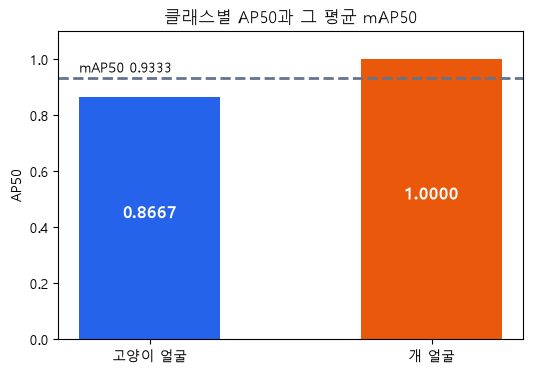

모델 C: 맞힌 박스 1개 · 맞힌 박스 평균 IoU 0.980 · 놓친 정답 2개 · AP50 0.333
모델 D: 맞힌 박스 3개 · 맞힌 박스 평균 IoU 0.673 · 놓친 정답 0개 · AP50 1.000


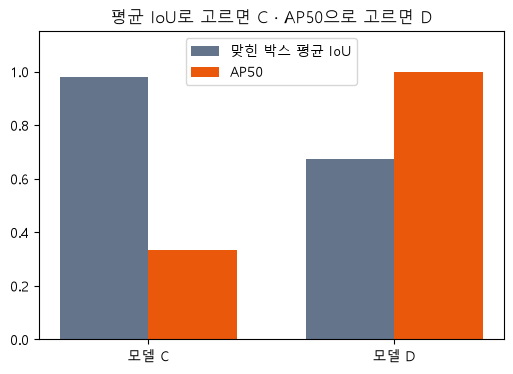

In [32]:
# ---------- 6-1 ----------
# 왜 · mAP가 클래스별 AP의 단순 평균이라는 것을 숫자로 확인하기 위해
ap_cat = ap_at(PRED_A, 0.5)  # 고양이 얼굴 = 모델 A
ap_dog = 1.0                 # 개 얼굴: 예측 2개가 순서대로 둘 다 TP → 넓이 1.0
print(f"고양이 얼굴 AP50 {ap_cat:.4f} · 개 얼굴 AP50 {ap_dog:.4f} →"  # 클래스별
      f" mAP50 = ({ap_cat:.4f} + {ap_dog:.4f}) ÷ 2 = {(ap_cat + ap_dog) / 2:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))                             # 막대 그림
# 두 AP
ax.bar(["고양이 얼굴", "개 얼굴"], [ap_cat, ap_dog], color=[PRED_COLOR, ENV_COLOR], width=0.5)
ax.axhline((ap_cat + ap_dog) / 2, color="#64748b", ls="--", lw=2)  # 평균선
# 평균값
ax.text(-0.25, (ap_cat + ap_dog) / 2 + 0.02, f"mAP50 {(ap_cat + ap_dog) / 2:.4f}", ha="left",
        fontsize=10)
for i, v in enumerate([ap_cat, ap_dog]):                           # 막대마다
    ax.text(i, v / 2, f"{v:.4f}", ha="center", color=INK, fontsize=12, fontweight="bold")  # 값
ax.set_ylim(0, 1.1)                                                # 범위
ax.set_ylabel("AP50", fontsize=10)                                 # y축
ax.set_title("클래스별 AP50과 그 평균 mAP50", fontsize=12)         # 제목
plt.show()                                                         # 그림 출력


# ---------- 6-2 ----------
# 왜 · 평균 IoU가 높아도 놓친 정답이 많으면 나쁜 모델이라는 반례를 만들기 위해
PRED_C = [(0.90, "사진1", [10, 10, 60, 59])]  # 모델 C: 1개만 · 딱 맞음
PRED_D = [(0.90, "사진1", [16, 14, 66, 62]), (0.85, "사진1", [106, 25, 156, 75]),  # 모델 D: 3개
          (0.80, "사진2", [37, 36, 97, 96])]  # 셋 다 적당히

# 왜 · 두 모델의 평균 IoU와 AP를 나란히 비교하기 위해
res = {}                                                      # 모델마다 (평균 IoU, AP50)
for name, preds in [("모델 C", PRED_C), ("모델 D", PRED_D)]:  # 두 모델
    rows, fn = judge(preds, 0.5)                              # 판정
    tp_ious = [v for _, ok, v, *_ in rows if ok]              # 맞힌 박스의 IoU
    r, p = pr_points(rows)                                    # PR 점
    res[name] = (np.mean(tp_ious), ap_all_point(r, p))        # 두 숫자
    # 비교
    print(f"{name}: 맞힌 박스 {len(tp_ious)}개 · 맞힌 박스 평균 IoU {np.mean(tp_ious):.3f} ·"
          f" 놓친 정답 {fn}개 · AP50 {ap_all_point(r, p):.3f}")

fig, ax = plt.subplots(figsize=(6, 4))                                           # 막대 비교
x = np.arange(2)                                                                 # 모델 2개 자리
# 회색
ax.bar(x - 0.18, [res[n][0] for n in res], 0.36, color="#64748b", label="맞힌 박스 평균 IoU")
ax.bar(x + 0.18, [res[n][1] for n in res], 0.36, color=ENV_COLOR, label="AP50")  # 주황
ax.set_xticks(x)                                                                 # 눈금 자리
ax.set_xticklabels(list(res))                                                    # 모델 이름
ax.set_ylim(0, 1.15)                                                             # 범위
ax.legend(fontsize=10, loc="upper center")                                       # 범례
ax.set_title("평균 IoU로 고르면 C · AP50으로 고르면 D", fontsize=12)             # 제목
plt.show()                                                                       # 그림 출력

**실행 흐름**

1. 보고 값 모으기 · 한 문장
2. 점검표 확인
3. 조건만 바꾼 숫자 비교

In [33]:
# ---------- 7. 종합 실습 ----------
# 1) 미션 노트북에 적을 값 모으기 (모델 A · 고양이 얼굴 + 개 얼굴 예시)
# 왜 · 보고에 필요한 조건 · 값을 한곳에 모으기 위해
conf_floor = min(c for c, *_ in PRED_A)               # 예측을 모은 컨피던스 하한 (0.40)
report = {"split": "예시 사진 2장", "평가 IoU": 0.5,  # 평가 조건
          "컨피던스 하한": conf_floor,
          "계산 방식": "우리 평가 함수 all-point", "정답 수": {"고양이 얼굴": N_GT, "개 얼굴": 2},
          "AP50": {"고양이 얼굴": round(ap_cat, 4), "개 얼굴": round(ap_dog, 4)}}
report["mAP50"] = round((ap_cat + ap_dog) / 2, 4)     # 클래스 평균
tp, fp, fn, p, r, f1 = prf(rows_A, 0.5)               # 실제로 쓸 임계값 0.5의 성적 (고양이)
# 따로 적음
report["임계값 0.5"] = {"정밀도": round(p, 3), "재현율": round(r, 3), "F1": round(f1, 3)}

# 2) B9 한 문장 형식으로
# 왜 · 조건과 값을 빠짐없이 한 문장으로 쓰는 연습을 하기 위해
# 조건
sentence = (f"{report['split']} · 평가 IoU {report['평가 IoU']} · 컨피던스 {conf_floor} 이상으로"
            f" 모은 예측 전부 · {report['계산 방식']}"
            f" · 고양이 얼굴 정답 {N_GT}개 · 개 얼굴 정답 2개"
            f" → 고양이 AP50 {ap_cat:.4f} · 개 AP50 {ap_dog:.4f} · mAP50 {report['mAP50']:.4f}")
print(sentence)                                      # 한 문장
print("임계값 0.5 (고양이):", report["임계값 0.5"])  # 실제로 쓸 기준


# 3) 점검표를 코드로 확인 (원본 B9의 7가지 중 숫자로 볼 수 있는 것)
# 왜 · 보고에 빠진 조건이 없는지 사람이 아니라 코드로 확인하기 위해
checks = {  # 점검 항목 → 통과 여부
    "평가 IoU 임계값을 적었나": "평가 IoU" in report,                               # AP50인지 명시
    "먼저 자르지 않았나 (컨피던스 하한 ≤ 0.5)": report["컨피던스 하한"] <= 0.5,     # 0.4까지 모음
    "계산 방식을 적었나 · COCO라고 부르지 않았나": "COCO" not in report["계산 방식"],  # 우리 함수
    # 두 클래스
    "클래스별 AP와 정답 수를 적었나": len(report["AP50"]) == len(report["정답 수"]) == 2,
    "실제 임계값의 정밀도 · 재현율 · F1을 적었나": len(report["임계값 0.5"]) == 3,  # 따로 적음
}
for k, v in checks.items():                                                         # 항목마다
    print(f"{'통과' if v else '빠짐'} · {k}")                                       # 결과
print("모두 통과:", all(checks.values()))                                           # 최종

# 4) 같은 예측 · 조건만 바꾸면 숫자가 얼마나 달라지나 (조건을 적어야 하는 이유)
# 왜 · 조건을 적지 않으면 숫자를 비교할 수 없다는 것을 보이기 위해
variants = {"AP50 all-point": ap_all_point(rec_A, prec_A),       # 기준
            "AP50 101-point": ap_101_point(rec_A, prec_A),       # 계산 방식만 다름
            "AP75 all-point": ap_at(PRED_A, 0.75),               # 평가 IoU만 다름
            "0.75 먼저 자른 AP50": ap_all_point(rec_c, prec_c)}  # 하한만 다름
for k, v in variants.items():                                    # 조건마다
    print(f"{k:16s} {v:.4f}")                                    # 같은 예측 · 다른 숫자

예시 사진 2장 · 평가 IoU 0.5 · 컨피던스 0.4 이상으로 모은 예측 전부 · 우리 평가 함수 all-point · 고양이 얼굴 정답 3개 · 개 얼굴 정답 2개 → 고양이 AP50 0.8667 · 개 AP50 1.0000 · mAP50 0.9333


임계값 0.5 (고양이): {'정밀도': 0.6, '재현율': 1.0, 'F1': 0.75}
통과 · 평가 IoU 임계값을 적었나
통과 · 먼저 자르지 않았나 (컨피던스 하한 ≤ 0.5)
통과 · 계산 방식을 적었나 · COCO라고 부르지 않았나
통과 · 클래스별 AP와 정답 수를 적었나
통과 · 실제 임계값의 정밀도 · 재현율 · F1을 적었나
모두 통과: True
AP50 all-point   0.8667
AP50 101-point   0.8653
AP75 all-point   0.6667
0.75 먼저 자른 AP50  0.6667
